In [ ]:
# --- 1. INSTALASI LIBRARY ---
!pip install pandas_ta yfinance keras-tuner xgboost optuna

# --- 2. IMPORT SEMUA LIBRARY YANG DIBUTUHKAN ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import pandas_ta as ta

from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from xgboost import XGBRegressor
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
import keras_tuner as kt

In [ ]:
# --- 1. LOAD DATASET NVDA (LANGSUNG DARI YFINANCE) ---
print("Mengunduh data historis NVDA secara real-time dari Yahoo Finance...")
# Mengambil dari hari pertama IPO Nvidia (1999) hingga hari ini
df_nvda = yf.download('NVDA', start='1999-02-01')

# Trik Anti-Error: yfinance versi baru kadang membuat MultiIndex pada kolom.
# Kita ratakan kolomnya agar fitur teknikal (SMA, MACD, dll) tidak error.
if isinstance(df_nvda.columns, pd.MultiIndex):
    df_nvda.columns = df_nvda.columns.get_level_values(0)

# --- 2. STANDARISASI WAKTU ---
# Kita bersihkan zona waktu dan jadikan tanggal sebagai Index
df_nvda.index = pd.to_datetime(df_nvda.index).tz_localize(None).normalize()
df_nvda.index.name = 'Date' # Menyamakan nama index dengan kode Anda sebelumnya
df_nvda.sort_index(inplace=True)

print(f"Berhasil! Anda sekarang menggunakan data terbaru sejumlah {df_nvda.shape[0]} hari perdagangan.")

# --- 3. FEATURE ENGINEERING (NVIDIA) ---
# Indikator Klasik
df_nvda['SMA_20'] = ta.sma(df_nvda['Close'], length=20)
df_nvda['SMA_50'] = ta.sma(df_nvda['Close'], length=50)
df_nvda['RSI_14'] = ta.rsi(df_nvda['Close'], length=14)
macd = ta.macd(df_nvda['Close'])
df_nvda = pd.concat([df_nvda, macd], axis=1)

# Bollinger Bands (Periode 20, 2 Standar Deviasi)
bbands = ta.bbands(df_nvda['Close'], length=20, std=2)
# Paksa ubah nama kolom Bollinger Bands agar seragam dan aman dari KeyError
bbands.columns = ['BBL_20_2', 'BBM_20_2', 'BBU_20_2', 'BBB_20_2', 'BBP_20_2']
df_nvda = pd.concat([df_nvda, bbands], axis=1)

# Average True Range (ATR) untuk Volatilitas
df_nvda['ATR_14'] = ta.atr(df_nvda['High'], df_nvda['Low'], df_nvda['Close'], length=14)
# Bollinger Band Width (Kerapatan Band)
df_nvda['BB_Width'] = df_nvda['BBB_20_2']

# Return Harian saat ini
df_nvda['Return_Hari_Ini'] = df_nvda['Close'].pct_change()

# ==========================================
# Fitur Lag (Riwayat Harga & Volume)
lag_list = [1, 3, 7]
for lag in lag_list:
    df_nvda[f"lag_close_{lag}"] = df_nvda["Close"].shift(lag)
    df_nvda[f"lag_volume_{lag}"] = df_nvda["Volume"].shift(lag)

# Fitur Rolling Mean & Volatility (Statistik Berjalan)
rolling_list = [7, 14]
for r in rolling_list:
    df_nvda[f"rolling_mean_close_{r}"] = df_nvda["Close"].rolling(window=r).mean()
    df_nvda[f"rolling_std_close_{r}"] = df_nvda["Close"].rolling(window=r).std()
# ==========================================

# --- 4. TARGET & PEMBERSIHAN AKHIR ---
# Target prediksi: Persentase Return untuk hari esok
df_nvda['Target_Return_Besok'] = df_nvda['Close'].pct_change().shift(-1)

# Buang baris yang kosong (NaN) akibat pembuatan indikator dan fitur lag
df_nvda.dropna(inplace=True)

print(f"Data siap! Total baris data untuk dievaluasi: {df_nvda.shape[0]} baris.")

Mengunduh data historis NVDA secara real-time dari Yahoo Finance...


/tmp/ipykernel_2759/3982034696.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_nvda = yf.download('NVDA', start='1999-02-01')
/usr/local/lib/python3.12/dist-packages/yfinance/scrapers/history.py:147: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  end_dt = pd.Timestamp.utcnow().tz_convert(tz)
/usr/local/lib/python3.12/dist-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
[*********************100%***********************]  1 of 1 completed


Berhasil! Anda sekarang menggunakan data terbaru sejumlah 6870 hari perdagangan.
Data siap! Total baris data untuk dievaluasi: 6820 baris.


In [ ]:
# =============================================================================
# FEATURE ENGINEERING - FONDASI MODEL
# Semua rekomendasi baru untuk proyek prediksi return NVDA
# Tempelkan cell-cell ini setelah cell Feature Engineering yang sudah ada
# =============================================================================

# %% =========================================================================
# INSTALASI LIBRARY TAMBAHAN
# =============================================================================
# !pip install yfinance pandas_ta pandas numpy scikit-learn yfinance pandas-market-calendars

# %% =========================================================================
# CELL 1: IMPORT LIBRARY TAMBAHAN
# =============================================================================
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_ta as ta
import warnings
warnings.filterwarnings('ignore')

# Asumsi: df_nvda sudah ada dari cell sebelumnya (data NVDA + indikator dasar)
# Kode ini MELANJUTKAN dari notebook yang sudah ada


# %% =========================================================================
# CELL 2: FITUR 1 — VIX (Fear Index) & SMH (Chip Sector ETF)
# Tujuan: Menangkap konteks pasar makro dan korelasi sektoral NVDA
# =============================================================================
print("=" * 60)
print("CELL 2: Mengunduh VIX & SMH...")
print("=" * 60)

# Tentukan rentang tanggal yang sama dengan df_nvda
start_date = df_nvda.index.min()
end_date   = df_nvda.index.max()

# --- Download VIX ---
vix_raw = yf.download('^VIX', start=start_date, end=end_date, auto_adjust=True)
if isinstance(vix_raw.columns, pd.MultiIndex):
    vix_raw.columns = vix_raw.columns.get_level_values(0)
vix_raw.index = pd.to_datetime(vix_raw.index).tz_localize(None).normalize()

# Kita pakai kolom Close VIX saja
df_vix = vix_raw[['Close']].rename(columns={'Close': 'VIX_Close'})

# Fitur turunan VIX:
df_vix['VIX_Change']      = df_vix['VIX_Close'].pct_change()          # Perubahan harian VIX
df_vix['VIX_MA5']         = df_vix['VIX_Close'].rolling(5).mean()     # Rata-rata 5 hari VIX
df_vix['VIX_spike']       = (df_vix['VIX_Close'] > 30).astype(int)    # Flag: panik ekstrem (VIX > 30)
df_vix['VIX_above_MA5']   = (df_vix['VIX_Close'] > df_vix['VIX_MA5']).astype(int)  # VIX naik vs MA

# --- Download SMH (VanEck Semiconductor ETF) ---
smh_raw = yf.download('SMH', start=start_date, end=end_date, auto_adjust=True)
if isinstance(smh_raw.columns, pd.MultiIndex):
    smh_raw.columns = smh_raw.columns.get_level_values(0)
smh_raw.index = pd.to_datetime(smh_raw.index).tz_localize(None).normalize()

df_smh = smh_raw[['Close']].rename(columns={'Close': 'SMH_Close'})

# Fitur turunan SMH:
df_smh['SMH_Return']     = df_smh['SMH_Close'].pct_change()            # Return harian SMH
df_smh['SMH_MA20']       = df_smh['SMH_Close'].rolling(20).mean()
df_smh['SMH_above_MA20'] = (df_smh['SMH_Close'] > df_smh['SMH_MA20']).astype(int)

# --- Gabungkan ke df_nvda ---
df_nvda = df_nvda.join(df_vix[['VIX_Close','VIX_Change','VIX_MA5','VIX_spike','VIX_above_MA5']], how='left')
df_nvda = df_nvda.join(df_smh[['SMH_Return','SMH_above_MA20']], how='left')

# Forward-fill untuk hari libur yang berbeda antar instrument
vix_smh_cols = ['VIX_Close','VIX_Change','VIX_MA5','VIX_spike','VIX_above_MA5',
                'SMH_Return','SMH_above_MA20']
df_nvda[vix_smh_cols] = df_nvda[vix_smh_cols].ffill()

print(f"✓ Fitur VIX ditambahkan: VIX_Close, VIX_Change, VIX_MA5, VIX_spike, VIX_above_MA5")
print(f"✓ Fitur SMH ditambahkan: SMH_Return, SMH_above_MA20")
print(f"  Sample VIX terbaru: {df_nvda['VIX_Close'].tail(3).values}")


# %% =========================================================================
# CELL 3: FITUR 2 — IMPLIED VOLATILITY (IV) NVDA
# Tujuan: Mengukur ekspektasi volatilitas dari pasar opsi (sering leading indicator)
# CATATAN: IV historis tidak gratis dari yfinance. Kita gunakan dua pendekatan:
#   (a) IV real-time dari options chain (untuk prediksi hari ini)
#   (b) IV proxy dari HV (Historical Volatility) yang dipercepat — standar industri
# =============================================================================
print("=" * 60)
print("CELL 3: Menghitung Implied Volatility Proxy...")
print("=" * 60)

# -----------------------------------------------------------------------------
# Pendekatan (a): IV REAL-TIME dari yfinance options chain
# Berguna untuk prediksi hari ini / live trading
# -----------------------------------------------------------------------------
def get_atm_iv_realtime(ticker_symbol='NVDA'):
    """
    Ambil ATM (At-The-Money) Implied Volatility dari options chain terbaru.
    Mengembalikan IV dalam bentuk desimal (misal 0.65 = 65% annualized IV).
    """
    ticker = yf.Ticker(ticker_symbol)
    spot_price = ticker.history(period='1d')['Close'].iloc[-1]

    # Ambil expiration tanggal terdekat (1–4 minggu ke depan untuk likuiditas terbaik)
    expirations = ticker.options
    if len(expirations) == 0:
        print("  Tidak ada data options tersedia.")
        return None

    # Pilih expiration 2–3 minggu ke depan (lebih stabil dari weekly)
    target_exp = expirations[min(2, len(expirations)-1)]
    chain = ticker.option_chain(target_exp)

    # --- Call options: cari yang paling dekat dengan harga spot (ATM) ---
    calls = chain.calls.copy()
    calls['distance'] = (calls['strike'] - spot_price).abs()
    atm_call = calls.sort_values('distance').iloc[0]

    # --- Put options: sama ---
    puts = chain.puts.copy()
    puts['distance'] = (puts['strike'] - spot_price).abs()
    atm_put = puts.sort_values('distance').iloc[0]

    # Rata-rata IV call dan put ATM (lebih robust)
    iv = (atm_call['impliedVolatility'] + atm_put['impliedVolatility']) / 2

    print(f"  Spot Price      : ${spot_price:.2f}")
    print(f"  Expiration      : {target_exp}")
    print(f"  ATM Strike      : ${atm_call['strike']:.2f}")
    print(f"  IV (Call ATM)   : {atm_call['impliedVolatility']*100:.1f}%")
    print(f"  IV (Put ATM)    : {atm_put['impliedVolatility']*100:.1f}%")
    print(f"  IV Average ATM  : {iv*100:.1f}%")
    return iv

iv_today = get_atm_iv_realtime('NVDA')

# -----------------------------------------------------------------------------
# Pendekatan (b): HV-based IV PROXY untuk fitur historis
# Historical Volatility 30 hari (annualized) sebagai proxy IV
# Ini adalah standar industri ketika data IV historis tidak tersedia
# Korelasi dengan IV nyata biasanya > 0.85 untuk saham besar
# -----------------------------------------------------------------------------
log_returns = np.log(df_nvda['Close'] / df_nvda['Close'].shift(1))

# HV 10, 20, 30 hari (annualized) — pasar opsi menggunakan 252 hari trading
df_nvda['HV_10']  = log_returns.rolling(10).std()  * np.sqrt(252)
df_nvda['HV_20']  = log_returns.rolling(20).std()  * np.sqrt(252)   # Proxy IV 1 bulan
df_nvda['HV_30']  = log_returns.rolling(30).std()  * np.sqrt(252)   # Proxy IV utama

# IV Ratio: HV10 / HV30 — jika > 1 artinya volatilitas baru-baru ini melonjak
df_nvda['HV_ratio_10_30'] = df_nvda['HV_10'] / df_nvda['HV_30'].replace(0, np.nan)

# Volatility term structure slope: HV10 - HV30
# Positif = short-term vol tinggi = mungkin ada event/earnings
df_nvda['Vol_term_slope'] = df_nvda['HV_10'] - df_nvda['HV_30']

print(f"✓ Fitur IV Proxy ditambahkan: HV_10, HV_20, HV_30, HV_ratio_10_30, Vol_term_slope")
print(f"  Sample HV_30 (annualized): {df_nvda['HV_30'].tail(3).values.round(3)}")


# %% =========================================================================
# CELL 4: FITUR 3 — EARNINGS CALENDAR FLAG
# Tujuan: Beri tahu model bahwa "besok ada earnings" — pergerakan ekstrem sering terjadi
# NVDA biasanya earnings 4x setahun (Februari, Mei, Agustus, November)
# =============================================================================
print("=" * 60)
print("CELL 4: Membuat Earnings Calendar Flag...")
print("=" * 60)

# --- Metode A: Otomatis dari yfinance (disarankan) ---
def get_earnings_dates_nvda():
    """Ambil semua tanggal earnings NVDA dari yfinance."""
    ticker = yf.Ticker('NVDA')
    try:
        # get_earnings_dates mengembalikan DataFrame dengan index berupa tanggal
        earnings_df = ticker.get_earnings_dates(limit=40)
        if earnings_df is None or len(earnings_df) == 0:
            return pd.DatetimeIndex([])
        dates = pd.to_datetime(earnings_df.index).tz_localize(None).normalize()
        return dates
    except Exception as e:
        print(f"  Warning: Tidak bisa ambil earnings otomatis ({e}), pakai manual.")
        return pd.DatetimeIndex([])

earnings_dates = get_earnings_dates_nvda()

# --- Metode B: Manual fallback (jika API gagal) ---
# Data earnings NVDA historis (lengkapi sesuai kebutuhan)
earnings_manual = pd.to_datetime([
    # 2020
    '2020-02-19', '2020-05-21', '2020-08-19', '2020-11-18',
    # 2021
    '2021-02-24', '2021-05-26', '2021-08-25', '2021-11-17',
    # 2022
    '2022-02-16', '2022-05-25', '2022-08-24', '2022-11-16',
    # 2023
    '2023-02-22', '2023-05-24', '2023-08-23', '2023-11-21',
    # 2024
    '2024-02-21', '2024-05-22', '2024-08-28', '2024-11-20',
    # 2025
    '2025-02-26', '2025-05-28',
])

# Gabungkan otomatis + manual, buang duplikat
if len(earnings_dates) > 0:
    all_earnings = pd.DatetimeIndex(
        earnings_dates.tolist() + earnings_manual.tolist()
    ).normalize().unique().sort_values()
    print(f"  Earnings dates ditemukan otomatis: {len(earnings_dates)}")
else:
    all_earnings = earnings_manual
    print(f"  Menggunakan manual earnings dates: {len(all_earnings)} tanggal")

# --- Buat fitur flag ---
# Flag 1: Apakah HARI INI adalah hari earnings
df_nvda['is_earnings_day'] = df_nvda.index.isin(all_earnings).astype(int)

# Flag 2: Berapa hari lagi menuju earnings terdekat (0 = hari earnings itu)
def days_to_next_earnings(date, earnings_list):
    future = earnings_list[earnings_list >= date]
    if len(future) == 0:
        return 999  # Tidak ada data earnings ke depan
    return (future[0] - date).days

df_nvda['days_to_earnings'] = [
    days_to_next_earnings(d, all_earnings) for d in df_nvda.index
]

# Flag 3: Apakah dalam 5 hari sebelum earnings (pre-earnings window — biasa ada gerakan)
df_nvda['pre_earnings_5d']  = ((df_nvda['days_to_earnings'] <= 5) &
                               (df_nvda['days_to_earnings'] > 0)).astype(int)

# Flag 4: Apakah dalam 2 hari SETELAH earnings (post-earnings drift)
df_nvda['days_since_earnings'] = df_nvda.index.map(
    lambda d: min([(d - e).days for e in all_earnings if (d - e).days >= 0], default=999)
)
df_nvda['post_earnings_2d'] = ((df_nvda['days_since_earnings'] >= 1) &
                               (df_nvda['days_since_earnings'] <= 2)).astype(int)

earnings_count = df_nvda['is_earnings_day'].sum()
print(f"✓ Fitur Earnings ditambahkan:")
print(f"  is_earnings_day  : {earnings_count} hari earnings dalam data")
print(f"  days_to_earnings : min={df_nvda['days_to_earnings'].min()}, max={df_nvda['days_to_earnings'].max()}")
print(f"  pre_earnings_5d  : {df_nvda['pre_earnings_5d'].sum()} hari")
print(f"  post_earnings_2d : {df_nvda['post_earnings_2d'].sum()} hari")


# %% =========================================================================
# CELL 5: FITUR 4 — LAG YANG LEBIH PANJANG (14, 21, 30 HARI)
# Tujuan: Tangkap momentum multi-minggu yang tidak terlihat dari lag 1/3/7 hari
# =============================================================================
print("=" * 60)
print("CELL 5: Menambah Extended Lag Features...")
print("=" * 60)

extended_lags = [14, 21, 30]

for lag in extended_lags:
    # Lag harga penutupan
    df_nvda[f'lag_close_{lag}']  = df_nvda['Close'].shift(lag)

    # Lag volume
    df_nvda[f'lag_volume_{lag}'] = df_nvda['Volume'].shift(lag)

    # Lag return (return N hari lalu)
    df_nvda[f'lag_return_{lag}'] = df_nvda['Return_Hari_Ini'].shift(lag)

    # Momentum: return kumulatif N hari ke belakang
    df_nvda[f'momentum_{lag}d']  = df_nvda['Close'].pct_change(lag)

# Rolling stats untuk window yang lebih panjang
for window in [21, 30]:
    df_nvda[f'rolling_mean_close_{window}'] = df_nvda['Close'].rolling(window).mean()
    df_nvda[f'rolling_std_close_{window}']  = df_nvda['Close'].rolling(window).std()

# Rate of Change (ROC) — persentase perubahan dari N hari lalu
for period in [10, 20]:
    df_nvda[f'ROC_{period}'] = ((df_nvda['Close'] - df_nvda['Close'].shift(period))
                                 / df_nvda['Close'].shift(period)) * 100

new_lag_cols = ([f'lag_close_{l}' for l in extended_lags] +
                [f'lag_volume_{l}' for l in extended_lags] +
                [f'lag_return_{l}' for l in extended_lags] +
                [f'momentum_{l}d' for l in extended_lags] +
                ['rolling_mean_close_21','rolling_std_close_21',
                 'rolling_mean_close_30','rolling_std_close_30',
                 'ROC_10','ROC_20'])

print(f"✓ Extended lag features ditambahkan ({len(new_lag_cols)} kolom baru):")
print(f"  {new_lag_cols}")


# %% =========================================================================
# CELL 6: FITUR 5 — OBV (On-Balance Volume) & CHAIKIN MONEY FLOW (CMF)
# Tujuan: Konfirmasi teknikal berbasis volume — lebih kuat dari sekedar volume mentah
# OBV: Akumulasi/distribusi oleh institusi
# CMF: Apakah uang "mengalir masuk" atau "mengalir keluar" dari saham
# =============================================================================
print("=" * 60)
print("CELL 6: Menghitung OBV & Chaikin Money Flow...")
print("=" * 60)

# --- On-Balance Volume (OBV) ---
# Logika: jika harga naik, tambah volume; jika harga turun, kurangi volume
df_nvda['OBV'] = ta.obv(df_nvda['Close'], df_nvda['Volume'])

# Normalisasi OBV dengan rolling z-score (agar skala tidak jadi masalah)
df_nvda['OBV_zscore'] = (
    (df_nvda['OBV'] - df_nvda['OBV'].rolling(20).mean())
    / df_nvda['OBV'].rolling(20).std()
)

# OBV signal: apakah OBV di atas MA 20-nya (konfirmasi trend)
df_nvda['OBV_above_MA20'] = (df_nvda['OBV'] > df_nvda['OBV'].rolling(20).mean()).astype(int)

# --- Chaikin Money Flow (CMF) ---
# Standar periode: 20 hari
# Nilai positif = uang masuk (akumulasi), negatif = uang keluar (distribusi)
df_nvda['CMF_20'] = ta.cmf(
    df_nvda['High'],
    df_nvda['Low'],
    df_nvda['Close'],
    df_nvda['Volume'],
    length=20
)

# CMF signal: apakah CMF positif (aliran dana masuk)
df_nvda['CMF_positive'] = (df_nvda['CMF_20'] > 0).astype(int)

# --- Money Flow Index (MFI) — versi RSI berbasis volume ---
# Overbought > 80, Oversold < 20
df_nvda['MFI_14'] = ta.mfi(
    df_nvda['High'],
    df_nvda['Low'],
    df_nvda['Close'],
    df_nvda['Volume'],
    length=14
)

# --- Accumulation/Distribution Line ---
df_nvda['AD_Line'] = ta.ad(
    df_nvda['High'],
    df_nvda['Low'],
    df_nvda['Close'],
    df_nvda['Volume']
)
df_nvda['AD_zscore'] = (
    (df_nvda['AD_Line'] - df_nvda['AD_Line'].rolling(20).mean())
    / df_nvda['AD_Line'].rolling(20).std()
)

# Volume Spike: apakah volume hari ini > 2x rata-rata 20 hari (sinyal aksi korporat)
df_nvda['volume_spike'] = (
    df_nvda['Volume'] > df_nvda['Volume'].rolling(20).mean() * 2
).astype(int)

# Volume ratio vs MA20
df_nvda['volume_ratio_MA20'] = df_nvda['Volume'] / df_nvda['Volume'].rolling(20).mean()

print(f"✓ Fitur OBV & Volume Flow ditambahkan:")
print(f"  OBV, OBV_zscore, OBV_above_MA20")
print(f"  CMF_20, CMF_positive")
print(f"  MFI_14 (Money Flow Index)")
print(f"  AD_Line, AD_zscore")
print(f"  volume_spike, volume_ratio_MA20")
print(f"\n  Sample CMF_20 terbaru: {df_nvda['CMF_20'].dropna().tail(3).values.round(3)}")


# %% =========================================================================
# CELL 7: FITUR 6 — RELATIVE STRENGTH vs SPY & NASDAQ (QQQ)
# Tujuan: Ukur apakah NVDA outperform atau underperform indeks
# Jika NVDA naik tapi SPY turun → sinyal kuat (uang khusus masuk NVDA)
# Jika NVDA turun tapi SPY naik → sinyal lemah (NVDA relatif lemah)
# =============================================================================
print("=" * 60)
print("CELL 7: Menghitung Relative Strength vs SPY & QQQ...")
print("=" * 60)

# --- Download SPY (S&P 500 ETF) & QQQ (NASDAQ 100 ETF) ---
for ticker_sym, col_prefix in [('SPY', 'SPY'), ('QQQ', 'QQQ')]:
    raw = yf.download(ticker_sym, start=start_date, end=end_date, auto_adjust=True)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw.index = pd.to_datetime(raw.index).tz_localize(None).normalize()

    # Return harian
    ret_col = f'{col_prefix}_Return'
    df_tmp = raw[['Close']].rename(columns={'Close': f'{col_prefix}_Close'})
    df_tmp[ret_col] = df_tmp[f'{col_prefix}_Close'].pct_change()

    # Gabungkan
    df_nvda = df_nvda.join(
        df_tmp[[f'{col_prefix}_Close', ret_col]],
        how='left'
    )
    df_nvda[[f'{col_prefix}_Close', ret_col]] = \
        df_nvda[[f'{col_prefix}_Close', ret_col]].ffill()

# --- Relative Strength Ratio ---
# RS > 1: NVDA outperform; RS < 1: NVDA underperform
df_nvda['RS_vs_SPY'] = df_nvda['Close'] / df_nvda['SPY_Close']
df_nvda['RS_vs_QQQ'] = df_nvda['Close'] / df_nvda['QQQ_Close']

# Normalisasi RS (z-score 20 hari) agar comparable lintas periode
for col in ['RS_vs_SPY', 'RS_vs_QQQ']:
    df_nvda[f'{col}_zscore'] = (
        (df_nvda[col] - df_nvda[col].rolling(20).mean())
        / df_nvda[col].rolling(20).std()
    )

# --- Return Alpha: Seberapa jauh NVDA mengungguli benchmark hari ini ---
# Positif = NVDA lebih baik dari SPY; negatif = NVDA tertinggal
df_nvda['alpha_vs_SPY'] = df_nvda['Return_Hari_Ini'] - df_nvda['SPY_Return']
df_nvda['alpha_vs_QQQ'] = df_nvda['Return_Hari_Ini'] - df_nvda['QQQ_Return']

# --- Relative Strength Trend ---
# Apakah RS NVDA vs SPY sedang trending naik? (RS di atas MA 10-nya)
df_nvda['RS_SPY_trending_up'] = (
    df_nvda['RS_vs_SPY'] > df_nvda['RS_vs_SPY'].rolling(10).mean()
).astype(int)

df_nvda['RS_QQQ_trending_up'] = (
    df_nvda['RS_vs_QQQ'] > df_nvda['RS_vs_QQQ'].rolling(10).mean()
).astype(int)

# --- Beta proxy (rolling 60 hari) ---
# Beta > 1: NVDA lebih agresif dari pasar; beta < 1: lebih defensif
def rolling_beta(stock_ret, market_ret, window=60):
    """Hitung rolling beta antara stock dan market."""
    cov_   = stock_ret.rolling(window).cov(market_ret)
    var_   = market_ret.rolling(window).var()
    return cov_ / var_.replace(0, np.nan)

df_nvda['beta_vs_SPY_60d'] = rolling_beta(
    df_nvda['Return_Hari_Ini'], df_nvda['SPY_Return'], window=60
)

print(f"✓ Fitur Relative Strength ditambahkan:")
print(f"  RS_vs_SPY, RS_vs_SPY_zscore, RS_SPY_trending_up")
print(f"  RS_vs_QQQ, RS_vs_QQQ_zscore, RS_QQQ_trending_up")
print(f"  alpha_vs_SPY, alpha_vs_QQQ")
print(f"  beta_vs_SPY_60d")
print(f"\n  Sample alpha_vs_SPY terbaru: {df_nvda['alpha_vs_SPY'].dropna().tail(3).values.round(4)}")


# %% =========================================================================
# CELL 8: PEMBERSIHAN AKHIR & DAFTAR FITUR LENGKAP
# =============================================================================
print("=" * 60)
print("CELL 8: Pembersihan & Rekap Fitur Baru...")
print("=" * 60)

# Drop baris NaN yang muncul akibat fitur-fitur baru (rolling window terpanjang = 60 hari)
baris_sebelum = len(df_nvda)
df_nvda.dropna(inplace=True)
baris_sesudah = len(df_nvda)
print(f"  Baris dihapus karena NaN: {baris_sebelum - baris_sesudah}")
print(f"  Total baris siap pakai  : {baris_sesudah}")

# --- Daftar SEMUA fitur baru yang ditambahkan ---
fitur_vix_smh = [
    'VIX_Close', 'VIX_Change', 'VIX_MA5', 'VIX_spike', 'VIX_above_MA5',
    'SMH_Return', 'SMH_above_MA20'
]

fitur_iv_proxy = [
    'HV_10', 'HV_20', 'HV_30', 'HV_ratio_10_30', 'Vol_term_slope'
]

fitur_earnings = [
    'is_earnings_day', 'days_to_earnings', 'pre_earnings_5d', 'post_earnings_2d'
]

fitur_extended_lag = (
    [f'lag_close_{l}' for l in [14, 21, 30]] +
    [f'lag_volume_{l}' for l in [14, 21, 30]] +
    [f'lag_return_{l}' for l in [14, 21, 30]] +
    [f'momentum_{l}d' for l in [14, 21, 30]] +
    ['rolling_mean_close_21', 'rolling_std_close_21',
     'rolling_mean_close_30', 'rolling_std_close_30',
     'ROC_10', 'ROC_20']
)

fitur_obv_cmf = [
    'OBV_zscore', 'OBV_above_MA20',
    'CMF_20', 'CMF_positive',
    'MFI_14',
    'AD_zscore',
    'volume_spike', 'volume_ratio_MA20'
]

fitur_rs = [
    'RS_vs_SPY_zscore', 'RS_vs_QQQ_zscore',
    'alpha_vs_SPY', 'alpha_vs_QQQ',
    'RS_SPY_trending_up', 'RS_QQQ_trending_up',
    'beta_vs_SPY_60d'
]

# --- Fitur lama dari notebook asli ---
fitur_lama = [
    'RSI_14', 'Volume', 'Return_Hari_Ini', 'lag_volume_7',
    'MACDh_12_26_9', 'ATR_14', 'BB_Width', 'SMA_50',
    'lag_close_1', 'lag_close_3', 'lag_close_7',
    'lag_volume_1', 'lag_volume_3',
    'rolling_mean_close_7', 'rolling_mean_close_14',
    'rolling_std_close_7', 'rolling_std_close_14',
    'BBU_20_2', 'BBL_20_2', 'SMA_20',
    'MACD_12_26_9', 'MACDs_12_26_9'
]

# --- Gabungkan semua fitur ---
SEMUA_FITUR_BARU = (
    fitur_lama +
    fitur_vix_smh +
    fitur_iv_proxy +
    fitur_earnings +
    fitur_extended_lag +
    fitur_obv_cmf +
    fitur_rs
)

# Filter hanya kolom yang benar-benar ada di df_nvda (antisipasi jika ada yang gagal download)
SEMUA_FITUR_BARU = [f for f in SEMUA_FITUR_BARU if f in df_nvda.columns]

print(f"\n{'='*60}")
print(f"REKAP FITUR BARU")
print(f"{'='*60}")
print(f"  Fitur lama (notebook asli) : {len(fitur_lama)}")
print(f"  VIX & SMH                  : {len(fitur_vix_smh)}")
print(f"  IV Proxy (HV-based)        : {len(fitur_iv_proxy)}")
print(f"  Earnings Calendar          : {len(fitur_earnings)}")
print(f"  Extended Lag & Momentum    : {len(fitur_extended_lag)}")
print(f"  OBV & Volume Flow          : {len(fitur_obv_cmf)}")
print(f"  Relative Strength          : {len(fitur_rs)}")
print(f"  {'─'*40}")
print(f"  TOTAL FITUR                : {len(SEMUA_FITUR_BARU)}")
print(f"{'='*60}")


# %% =========================================================================
# CELL 9: VALIDASI CEPAT — CEK KORELASI FITUR BARU DENGAN TARGET
# =============================================================================
print("=" * 60)
print("CELL 9: Korelasi Fitur Baru vs Target Return...")
print("=" * 60)

target = 'Target_Return_Besok'
fitur_untuk_cek = (fitur_vix_smh + fitur_iv_proxy + fitur_earnings +
                   fitur_extended_lag[:6] + fitur_obv_cmf + fitur_rs)
fitur_untuk_cek = [f for f in fitur_untuk_cek if f in df_nvda.columns]

corr = df_nvda[fitur_untuk_cek + [target]].corr()[target].drop(target)
corr_sorted = corr.abs().sort_values(ascending=False)

print(f"\nTop 15 Fitur Baru (absolut korelasi dengan {target}):")
print(f"{'Fitur':<30} {'Korelasi':>10}")
print("─" * 42)
for feat, val in corr_sorted.head(15).items():
    direction = "+" if corr[feat] > 0 else "-"
    bar = "█" * int(abs(val) * 40)
    print(f"  {feat:<28} {direction}{val:.4f}  {bar}")

print(f"\nNOTE: Korelasi saham memang rendah (< 0.1 normal).")
print(f"      Yang penting: fitur baru ini MELENGKAPI fitur lama,")
print(f"      bukan menggantikan. Model tree-based menangkap")
print(f"      interaksi non-linear yang tidak terlihat dari korelasi.")


# %% =========================================================================
# CELL 10: UPDATE VARIABEL UNTUK MODEL (PLUG-IN KE NOTEBOOK ASLI)
# =============================================================================
# Jalankan cell ini SEBELUM cell training model di notebook asli
# Variabel X_all, X_train_all, X_test_all akan diperbarui otomatis

from sklearn.model_selection import train_test_split

# Siapkan X & y dengan semua fitur
X_all_baru = df_nvda[SEMUA_FITUR_BARU]
y          = df_nvda['Target_Return_Besok']

# Split (sama seperti di notebook asli: 80/20, tanpa shuffle)
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all_baru, y, test_size=0.2, shuffle=False
)

# Untuk klasifikasi
X_ens = X_all_baru.copy()

print(f"✓ Variabel model diperbarui:")
print(f"  X_train_all shape : {X_train_all.shape}")
print(f"  X_test_all shape  : {X_test_all.shape}")
print(f"  y_train shape     : {y_train.shape}")
print(f"\n✅ Semua fitur baru siap! Lanjutkan ke cell Feature Importance & Training.")

CELL 2: Mengunduh VIX & SMH...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


✓ Fitur VIX ditambahkan: VIX_Close, VIX_Change, VIX_MA5, VIX_spike, VIX_above_MA5
✓ Fitur SMH ditambahkan: SMH_Return, SMH_above_MA20
  Sample VIX terbaru: [18.05999947 17.44000053 17.44000053]
CELL 3: Menghitung Implied Volatility Proxy...
  Spot Price      : $215.33
  Expiration      : 2026-05-29
  ATM Strike      : $215.00
  IV (Call ATM)   : 43.1%
  IV (Put ATM)    : 41.9%
  IV Average ATM  : 42.5%
✓ Fitur IV Proxy ditambahkan: HV_10, HV_20, HV_30, HV_ratio_10_30, Vol_term_slope
  Sample HV_30 (annualized): [0.386 0.384 0.39 ]
CELL 4: Membuat Earnings Calendar Flag...
  Earnings dates ditemukan otomatis: 50
✓ Fitur Earnings ditambahkan:
  is_earnings_day  : 51 hari earnings dalam data
  days_to_earnings : min=0, max=5504
  pre_earnings_5d  : 148 hari
  post_earnings_2d : 78 hari
CELL 5: Menambah Extended Lag Features...
✓ Extended lag features ditambahkan (18 kolom baru):
  ['lag_close_14', 'lag_close_21', 'lag_close_30', 'lag_volume_14', 'lag_volume_21', 'lag_volume_30', 'lag_retu

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


✓ Fitur Relative Strength ditambahkan:
  RS_vs_SPY, RS_vs_SPY_zscore, RS_SPY_trending_up
  RS_vs_QQQ, RS_vs_QQQ_zscore, RS_QQQ_trending_up
  alpha_vs_SPY, alpha_vs_QQQ
  beta_vs_SPY_60d

  Sample alpha_vs_SPY terbaru: [-0.001   0.0027 -0.028 ]
CELL 8: Pembersihan & Rekap Fitur Baru...
  Baris dihapus karena NaN: 291
  Total baris siap pakai  : 6529

REKAP FITUR BARU
  Fitur lama (notebook asli) : 22
  VIX & SMH                  : 7
  IV Proxy (HV-based)        : 5
  Earnings Calendar          : 4
  Extended Lag & Momentum    : 18
  OBV & Volume Flow          : 8
  Relative Strength          : 7
  ────────────────────────────────────────
  TOTAL FITUR                : 71
CELL 9: Korelasi Fitur Baru vs Target Return...

Top 15 Fitur Baru (absolut korelasi dengan Target_Return_Besok):
Fitur                            Korelasi
──────────────────────────────────────────
  is_earnings_day              +0.0640  ██
  volume_spike                 +0.0387  █
  VIX_spike                    +0.034

In [ ]:
def directional_accuracy(y_true, y_pred):
    # Membandingkan kesamaan tanda (positif/negatif) antara nilai asli dan prediksi
    correct_direction = np.sign(y_true) == np.sign(y_pred)
    return np.mean(correct_direction)

# 2. Bungkus fungsi menjadi objek scorer yang bisa dibaca oleh algoritma tuning
da_scorer = make_scorer(directional_accuracy)

In [ ]:
import optuna
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# =====================================================================
# PRE-FASE: SPLIT DATA YANG BENAR
# WAJIB dilakukan SEBELUM training apapun agar tidak ada leakage
# 70% Train | 15% Validation (feature selection) | 15% Test (evaluasi final)
# =====================================================================
split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]  # untuk permutation importance
X_test_all  = X_all_baru.iloc[split_val:]             # HANYA untuk evaluasi final

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

tscv = TimeSeriesSplit(n_splits=5)

print("=" * 55)
print("SPLIT DATA")
print("=" * 55)
print(f"  Train      : {len(X_train_all):>5} baris (70%)")
print(f"  Validation : {len(X_val_all):>5} baris (15%) — untuk feature selection")
print(f"  Test       : {len(X_test_all):>5} baris (15%) — untuk evaluasi final")
print(f"  Total fitur: {X_train_all.shape[1]}")


# =====================================================================
# FASE 1: TUNING OPTUNA PADA SEMUA FITUR
# Tujuan: dapatkan model yang cukup baik untuk mengukur importance
# =====================================================================
print("\n" + "=" * 55)
print("FASE 1: Tuning Optuna pada Semua Fitur...")
print("=" * 55)

def objective_rf_all(trial):
    param = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 300),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 100),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 5, 50),
        'max_features':      trial.suggest_categorical('max_features', [0.5, 0.7, 1.0, 'sqrt', 'log2'])
    }
    model = RandomForestRegressor(**param, random_state=42, n_jobs=-1)
    return cross_val_score(model, X_train_all, y_train, cv=tscv, scoring=da_scorer).mean()

study_rf_all = optuna.create_study(direction='maximize')
study_rf_all.optimize(objective_rf_all, n_trials=50)  # naik dari 10 → 50

best_rf_all = RandomForestRegressor(**study_rf_all.best_params, random_state=42, n_jobs=-1)
best_rf_all.fit(X_train_all, y_train)
print(f"✓ Selesai. Best DA CV: {study_rf_all.best_value:.5f}")
print(f"  Parameter: {study_rf_all.best_params}")


# =====================================================================
# FASE 2A: PERMUTATION IMPORTANCE PADA VALIDATION SET
# Menggunakan X_val_all — BUKAN X_test_all
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2A: Permutation Importance pada Validation Set...")
print("=" * 55)

perm_result_rf = permutation_importance(
    best_rf_all, X_val_all, y_val,      # ← val set, bukan test set
    scoring=da_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df_rf = pd.DataFrame({
    'Fitur':    X_val_all.columns,      # ← X_val_all.columns
    'Skor_DA':  perm_result_rf.importances_mean,
    'Skor_Std': perm_result_rf.importances_std
}).sort_values(by='Skor_DA', ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur (Permutation Importance):")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 60)
for i, row in perm_df_rf.head(20).iterrows():
    print(f"{i+1:<4} {row['Fitur']:<35} {row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}")


# =====================================================================
# FASE 2B: SELEKSI FITUR BERBASIS STATISTIK + DEDUP KELOMPOK LOGIS
# Menggantikan: regex + hardcode top-10
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2B: Seleksi Fitur Berbasis Statistik...")
print("=" * 55)

# Kelompok fitur yang redundan secara finansial
# Dari setiap kelompok, hanya 1 fitur terbaik yang akan dipilih
kelompok_fitur = {
    'lag_close':    [f'lag_close_{l}'  for l in [1, 3, 7, 14, 21, 30]],
    'lag_volume':   [f'lag_volume_{l}' for l in [1, 3, 7, 14, 21, 30]],
    'lag_return':   [f'lag_return_{l}' for l in [14, 21, 30]],
    'momentum':     [f'momentum_{l}d'  for l in [14, 21, 30]] + ['ROC_10', 'ROC_20'],
    'rolling_mean': [f'rolling_mean_close_{w}' for w in [7, 14, 21, 30]],
    'rolling_std':  [f'rolling_std_close_{w}'  for w in [7, 14, 21, 30]],
    'hv':           ['HV_10', 'HV_20', 'HV_30'],
    'sma':          ['SMA_20', 'SMA_50'],
    'bb_band':      ['BBU_20_2', 'BBL_20_2', 'BBM_20_2', 'BBB_20_2', 'BBP_20_2'],
    'macd':         ['MACD_12_26_9', 'MACDs_12_26_9', 'MACDh_12_26_9'],
    'rs_spy':       ['RS_vs_SPY', 'RS_vs_SPY_zscore', 'RS_SPY_trending_up'],
    'rs_qqq':       ['RS_vs_QQQ', 'RS_vs_QQQ_zscore', 'RS_QQQ_trending_up'],
    'vix':          ['VIX_Close', 'VIX_Change', 'VIX_MA5', 'VIX_spike', 'VIX_above_MA5'],
    'obv':          ['OBV_zscore', 'OBV_above_MA20'],
    'ad':           ['AD_Line', 'AD_zscore'],
    'volume_flow':  ['volume_spike', 'volume_ratio_MA20'],
}

# Buat mapping: fitur → nama kelompoknya
fitur_ke_kelompok = {}
for nama_kelompok, daftar in kelompok_fitur.items():
    for f in daftar:
        fitur_ke_kelompok[f] = nama_kelompok

def seleksi_fitur(perm_df, fitur_ke_kelompok, min_features=10, top_k_fallback=20):
    """
    Seleksi fitur dengan pendekatan hybrid:
    1. Ambil fitur dengan Skor_DA > threshold statistik (std importance).
    2. Dari setiap kelompok redundan, hanya ambil 1 fitur dengan skor tertinggi.
    3. Jika hasil threshold terlalu sedikit, fallback ke Top-K ranking permutation importance.
    """
    threshold = perm_df['Skor_DA'].std()
    kandidat  = perm_df[perm_df['Skor_DA'] > threshold].copy()

    fitur_terpilih       = []
    kelompok_terpakai    = set()

    for _, row in kandidat.iterrows():
        fitur    = row['Fitur']
        kelompok = fitur_ke_kelompok.get(fitur, f'_solo_{fitur}')

        if kelompok not in kelompok_terpakai:
            fitur_terpilih.append(fitur)
            kelompok_terpakai.add(kelompok)

    if len(fitur_terpilih) < min_features:
        print(f"Peringatan: fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)['Fitur'].tolist()

    return fitur_terpilih, threshold

fitur_rf_terpilih, threshold_rf = seleksi_fitur(
    perm_df_rf,
    fitur_ke_kelompok,
    min_features=10,
    top_k_fallback=20
)

print(f"Threshold statistis : {threshold_rf:.5f}")
print(f"Fitur terpilih      : {len(fitur_rf_terpilih)} fitur\n")
for i, f in enumerate(fitur_rf_terpilih, 1):
    skor = perm_df_rf.loc[perm_df_rf['Fitur'] == f, 'Skor_DA'].values[0]
    print(f"  {i:>2}. {f:<35} (DA: {skor:.5f})")

# Buat irisan dataset dengan fitur terpilih
X_train_rf_sel = X_train_all[fitur_rf_terpilih]
X_val_rf_sel   = X_val_all[fitur_rf_terpilih]
X_test_rf_sel  = X_test_all[fitur_rf_terpilih]


# =====================================================================
# FASE 3: TUNING ULANG OPTUNA PADA FITUR TERPILIH
# Lebih banyak trial karena ruang pencarian lebih sempit & cepat
# =====================================================================
print("\n" + "=" * 55)
print("FASE 3: Tuning Ulang pada Fitur Terpilih...")
print("=" * 55)

def objective_rf_final(trial):
    param = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 2, 8),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 50),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 2, 20),
        'max_features':      trial.suggest_categorical('max_features', [0.5, 0.8, 1.0, 'sqrt'])
    }
    model = RandomForestRegressor(**param, random_state=42, n_jobs=-1)
    return cross_val_score(model, X_train_rf_sel, y_train, cv=tscv, scoring=da_scorer).mean()

study_rf_final = optuna.create_study(direction='maximize')
study_rf_final.optimize(objective_rf_final, n_trials=100)  # naik dari 15 → 100

best_rf_final = RandomForestRegressor(**study_rf_final.best_params, random_state=42, n_jobs=-1)
best_rf_final.fit(X_train_rf_sel, y_train)
print(f"✓ Selesai. Best DA CV: {study_rf_final.best_value:.5f}")
print(f"  Parameter: {study_rf_final.best_params}")


# =====================================================================
# EVALUASI MODEL FINAL
# Test set disentuh pertama kali di sini
# =====================================================================
print("\n" + "=" * 55)
print("EVALUASI MODEL FINAL RANDOM FOREST")
print("=" * 55)

prediksi_train_rf = best_rf_final.predict(X_train_rf_sel)
prediksi_test_rf  = best_rf_final.predict(X_test_rf_sel)

print(f"Fitur yang digunakan ({len(fitur_rf_terpilih)}): {fitur_rf_terpilih}\n")

print("[DATA TRAIN - Masa Lalu (Cek Overfitting)]")
print(f"MAE Train  : {mean_absolute_error(y_train, prediksi_train_rf):.5f}")
print(f"RMSE Train : {np.sqrt(mean_squared_error(y_train, prediksi_train_rf)):.5f}")
print(f"R2 Train   : {r2_score(y_train, prediksi_train_rf):.5f}")
print(f"DA Train   : {directional_accuracy(y_train, prediksi_train_rf):.5f}")

print("\n[DATA TEST - Masa Depan (Realita Pasar)]")
print(f"MAE Test   : {mean_absolute_error(y_test, prediksi_test_rf):.5f}")
print(f"RMSE Test  : {np.sqrt(mean_squared_error(y_test, prediksi_test_rf)):.5f}")
print(f"R2 Test    : {r2_score(y_test, prediksi_test_rf):.5f}")
print(f"DA Test    : {directional_accuracy(y_test, prediksi_test_rf):.5f}")

SPLIT DATA
  Train      :  4570 baris (70%)
  Validation :   979 baris (15%) — untuk feature selection
  Test       :   980 baris (15%) — untuk evaluasi final
  Total fitur: 71

FASE 1: Tuning Optuna pada Semua Fitur...
✓ Selesai. Best DA CV: 0.52589
  Parameter: {'n_estimators': 247, 'max_depth': 3, 'min_samples_split': 46, 'min_samples_leaf': 5, 'max_features': 0.7}

FASE 2A: Permutation Importance pada Validation Set...

Top 20 Fitur (Permutation Importance):
No   Fitur                                  Skor_DA     ±Std
------------------------------------------------------------
1    momentum_30d                           0.00123  0.00136
2    VIX_MA5                                0.00041  0.00068
3    lag_return_14                          0.00020  0.00041
4    lag_volume_30                          0.00020  0.00041
5    Return_Hari_Ini                        0.00010  0.00031
6    RSI_14                                 0.00000  0.00000
7    Volume                                 0

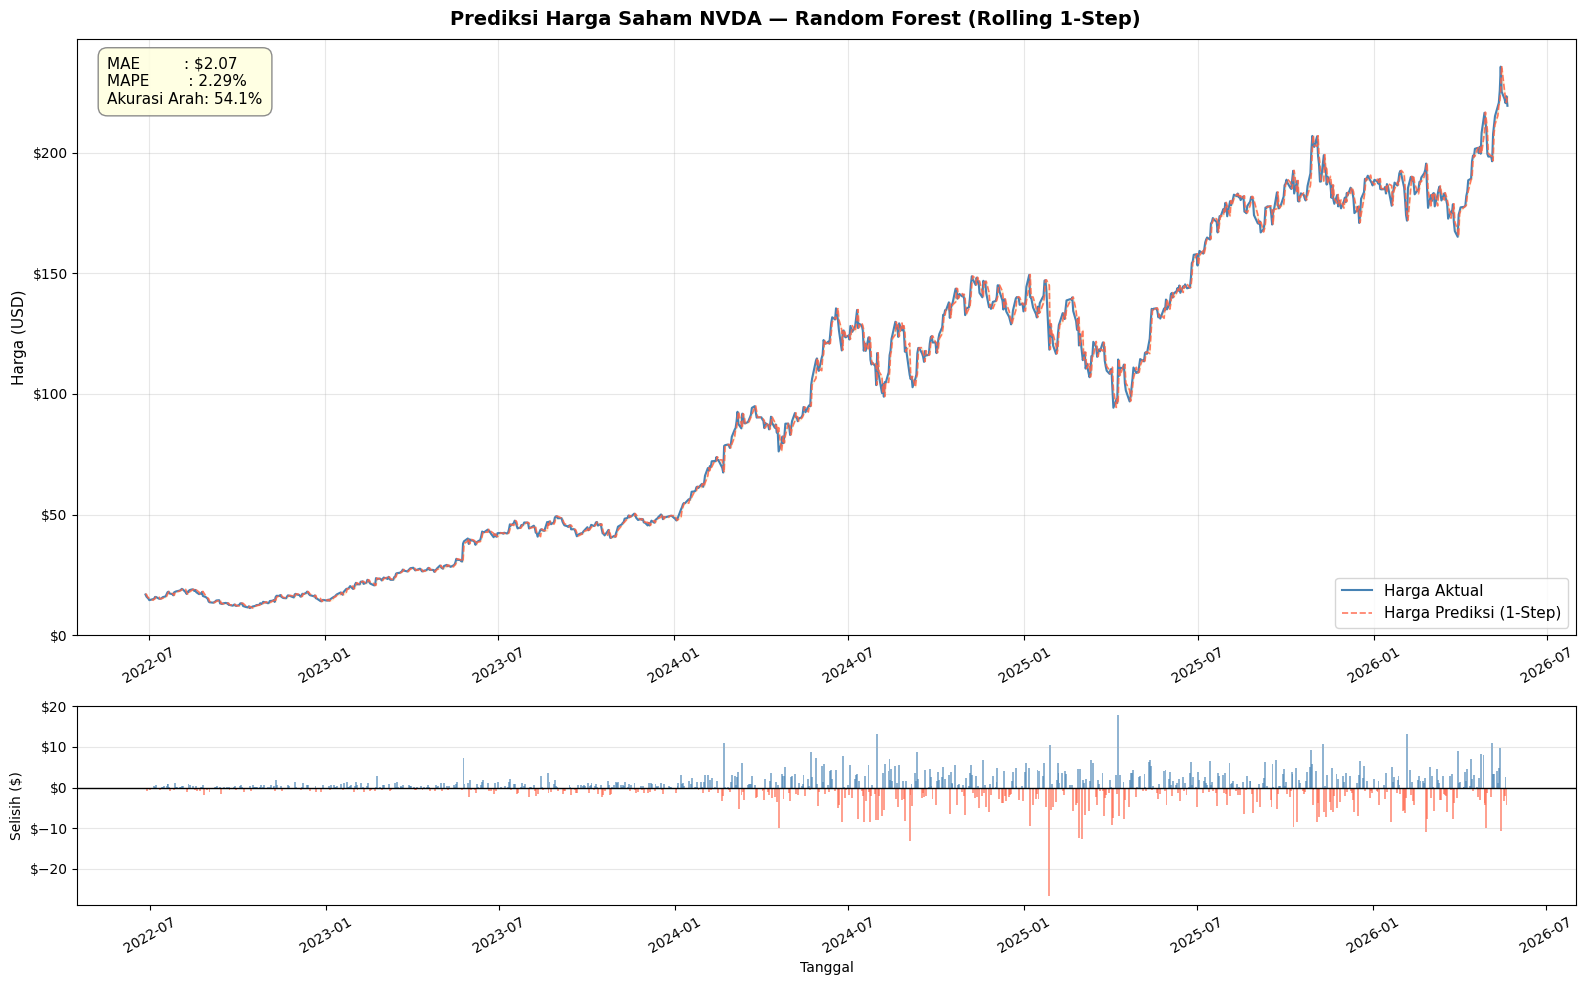

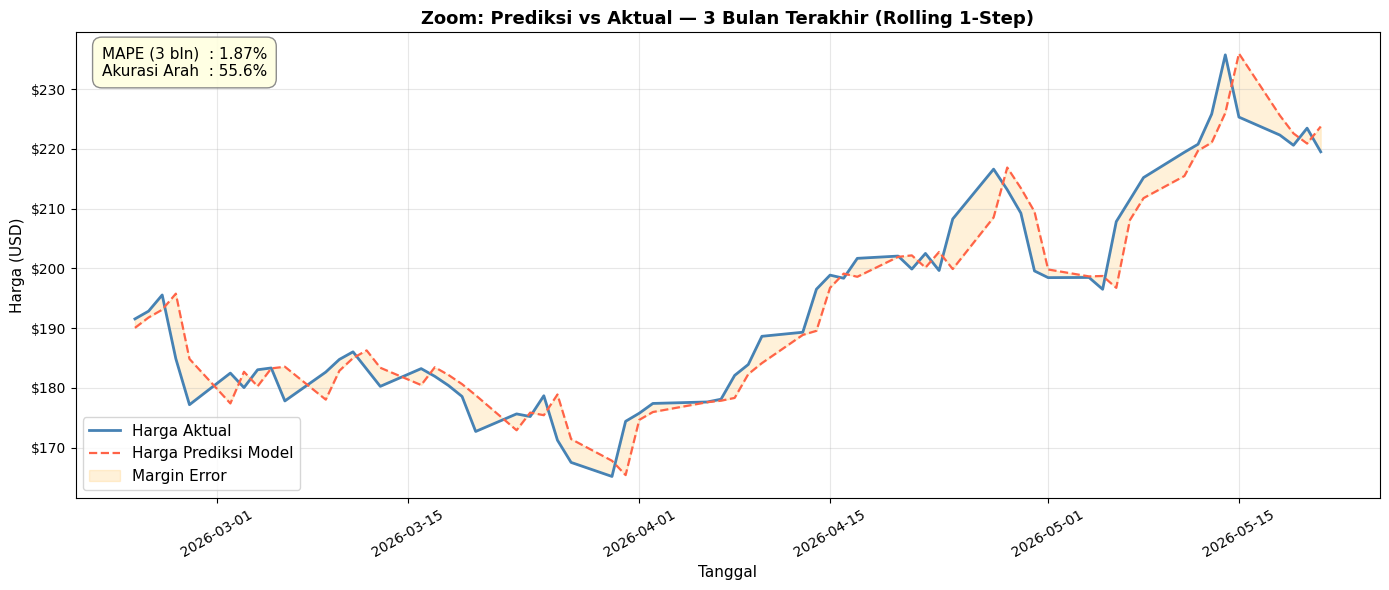


=== METRIK FINAL (ROLLING 1-STEP) ===
MAE Harga    : $2.07
MAPE Harga   : 2.29%
Akurasi Arah : 54.1%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# =============================================================
# ROLLING 1-STEP: pakai harga aktual kemarin + prediksi return
# Ini cara yang BENAR secara finansial
# predicted_price[t] = actual_price[t-1] × (1 + predicted_return[t])
# =============================================================

# Ambil harga Close aktual untuk seluruh test period
harga_close_aktual = df_nvda.loc[X_test_rf_sel.index, 'Close'].values

# Geser 1 hari: harga kemarin × return prediksi hari ini
harga_prediksi_rolling = np.zeros(len(harga_close_aktual))
for i in range(len(harga_close_aktual)):
    if i == 0:
        # Hari pertama: pakai harga terakhir sebelum test set
        harga_kemarin = df_nvda.loc[
            df_nvda.index < X_test_rf_sel.index[0], 'Close'
        ].iloc[-1]
    else:
        harga_kemarin = harga_close_aktual[i - 1]  # ← harga AKTUAL kemarin

    harga_prediksi_rolling[i] = harga_kemarin * (1 + prediksi_test_rf[i])

tanggal = X_test_rf_sel.index

# Metrik berbasis harga rolling
mae_rolling  = np.mean(np.abs(harga_close_aktual - harga_prediksi_rolling))
mape_rolling = np.mean(np.abs(
    (harga_close_aktual - harga_prediksi_rolling) / harga_close_aktual
)) * 100
da = (np.sign(y_test.values) == np.sign(prediksi_test_rf)).mean() * 100


# =============================================================
# GRAFIK FULL PERIOD
# =============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10),
                          gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('Prediksi Harga Saham NVDA — Random Forest (Rolling 1-Step)',
             fontsize=14, fontweight='bold')

ax1 = axes[0]
ax1.plot(tanggal, harga_close_aktual,
         label='Harga Aktual', color='steelblue', linewidth=1.5)
ax1.plot(tanggal, harga_prediksi_rolling,
         label='Harga Prediksi (1-Step)', color='tomato',
         linewidth=1.2, linestyle='--', alpha=0.85)
ax1.fill_between(tanggal,
                  harga_close_aktual,
                  harga_prediksi_rolling,
                  alpha=0.12, color='orange')

ax1.text(0.02, 0.97,
         f"MAE         : ${mae_rolling:.2f}\n"
         f"MAPE        : {mape_rolling:.2f}%\n"
         f"Akurasi Arah: {da:.1f}%",
         transform=ax1.transAxes, fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.6',
                   facecolor='lightyellow',
                   edgecolor='gray', alpha=0.9))

ax1.set_ylabel('Harga (USD)', fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)
ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax1.tick_params(axis='x', rotation=30)

# Selisih harga harian
ax2 = axes[1]
gap = harga_close_aktual - harga_prediksi_rolling
ax2.bar(tanggal, gap,
        color=['tomato' if g < 0 else 'steelblue' for g in gap],
        alpha=0.6, width=2)
ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylabel('Selisih ($)', fontsize=10)
ax2.set_xlabel('Tanggal', fontsize=10)
ax2.grid(alpha=0.3, axis='y')
ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('rf_rolling_1step_full.png', dpi=150, bbox_inches='tight')
plt.show()


# =============================================================
# GRAFIK ZOOM 3 BULAN TERAKHIR — untuk presentasi dosen
# =============================================================
zoom_n = 63

fig2, ax3 = plt.subplots(figsize=(14, 6))

ax3.plot(tanggal[-zoom_n:], harga_close_aktual[-zoom_n:],
         label='Harga Aktual', color='steelblue', linewidth=2.0)
ax3.plot(tanggal[-zoom_n:], harga_prediksi_rolling[-zoom_n:],
         label='Harga Prediksi Model', color='tomato',
         linewidth=1.6, linestyle='--')
ax3.fill_between(tanggal[-zoom_n:],
                  harga_close_aktual[-zoom_n:],
                  harga_prediksi_rolling[-zoom_n:],
                  alpha=0.15, color='orange', label='Margin Error')

mape_zoom = np.mean(np.abs(
    (harga_close_aktual[-zoom_n:] - harga_prediksi_rolling[-zoom_n:])
    / harga_close_aktual[-zoom_n:]
)) * 100
da_zoom = (np.sign(y_test.values[-zoom_n:]) ==
           np.sign(prediksi_test_rf[-zoom_n:])).mean() * 100

ax3.text(0.02, 0.97,
         f"MAPE (3 bln)  : {mape_zoom:.2f}%\n"
         f"Akurasi Arah  : {da_zoom:.1f}%",
         transform=ax3.transAxes, fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.6',
                   facecolor='lightyellow',
                   edgecolor='gray', alpha=0.9))

ax3.set_title('Zoom: Prediksi vs Aktual — 3 Bulan Terakhir (Rolling 1-Step)',
              fontsize=13, fontweight='bold')
ax3.set_ylabel('Harga (USD)', fontsize=11)
ax3.set_xlabel('Tanggal', fontsize=11)
ax3.legend(fontsize=11)
ax3.grid(alpha=0.3)
ax3.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('rf_rolling_zoom.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n=== METRIK FINAL (ROLLING 1-STEP) ===")
print(f"MAE Harga    : ${mae_rolling:.2f}")
print(f"MAPE Harga   : {mape_rolling:.2f}%")
print(f"Akurasi Arah : {da:.1f}%")

In [ ]:
import optuna
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# =====================================================================
# PRE-FASE: SPLIT DATA YANG BENAR
# =====================================================================
split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]
X_test_all  = X_all_baru.iloc[split_val:]

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

tscv = TimeSeriesSplit(n_splits=5)

print("=" * 55)
print("SPLIT DATA (XGBOOST PIPELINE)")
print("=" * 55)
print(f"  Train      : {len(X_train_all):>5} baris (70%)")
print(f"  Validation : {len(X_val_all):>5} baris (15%)")
print(f"  Test       : {len(X_test_all):>5} baris (15%)")
print(f"  Total fitur: {X_train_all.shape[1]}")


# =====================================================================
# FASE 1: TUNING OPTUNA PADA SEMUA FITUR (BASELINE)
# =====================================================================
print("\n" + "=" * 55)
print("FASE 1: Tuning Optuna XGBoost pada Semua Fitur...")
print("=" * 55)

def objective_xgb_all(trial):
    param = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 400),
        'max_depth':        trial.suggest_int('max_depth', 3, 9),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    model = XGBRegressor(**param, random_state=42, n_jobs=-1, objective='reg:squarederror')
    return cross_val_score(model, X_train_all, y_train, cv=tscv, scoring=da_scorer).mean()

study_xgb_all = optuna.create_study(direction='maximize')
study_xgb_all.optimize(objective_xgb_all, n_trials=50)

best_xgb_all = XGBRegressor(**study_xgb_all.best_params, random_state=42, n_jobs=-1, objective='reg:squarederror')
best_xgb_all.fit(X_train_all, y_train)
print(f"✓ Selesai. Best DA CV: {study_xgb_all.best_value:.5f}")
print(f"  Parameter: {study_xgb_all.best_params}")


# =====================================================================
# FASE 2A: PERMUTATION IMPORTANCE PADA VALIDATION SET
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2A: Permutation Importance pada Validation Set...")
print("=" * 55)

perm_result_xgb = permutation_importance(
    best_xgb_all, X_val_all, y_val,
    scoring=da_scorer, n_repeats=10, random_state=42, n_jobs=-1
)

perm_df_xgb = pd.DataFrame({
    'Fitur':    X_val_all.columns,
    'Skor_DA':  perm_result_xgb.importances_mean,
    'Skor_Std': perm_result_xgb.importances_std
}).sort_values(by='Skor_DA', ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur XGBoost (Permutation Importance):")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 60)
for i, row in perm_df_xgb.head(20).iterrows():
    print(f"{i+1:<4} {row['Fitur']:<35} {row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}")


# =====================================================================
# FASE 2B: SELEKSI FITUR BERBASIS STATISTIK + DEDUP
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2B: Seleksi Fitur Berbasis Statistik...")
print("=" * 55)

kelompok_fitur = {
    'lag_close':    [f'lag_close_{l}'  for l in [1, 3, 7, 14, 21, 30]],
    'lag_volume':   [f'lag_volume_{l}' for l in [1, 3, 7, 14, 21, 30]],
    'lag_return':   [f'lag_return_{l}' for l in [14, 21, 30]],
    'momentum':     [f'momentum_{l}d'  for l in [14, 21, 30]] + ['ROC_10', 'ROC_20'],
    'rolling_mean': [f'rolling_mean_close_{w}' for w in [7, 14, 21, 30]],
    'rolling_std':  [f'rolling_std_close_{w}'  for w in [7, 14, 21, 30]],
    'hv':           ['HV_10', 'HV_20', 'HV_30'],
    'sma':          ['SMA_20', 'SMA_50'],
    'bb_band':      ['BBU_20_2', 'BBL_20_2', 'BBM_20_2', 'BBB_20_2', 'BBP_20_2'],
    'macd':         ['MACD_12_26_9', 'MACDs_12_26_9', 'MACDh_12_26_9'],
    'rs_spy':       ['RS_vs_SPY', 'RS_vs_SPY_zscore', 'RS_SPY_trending_up'],
    'rs_qqq':       ['RS_vs_QQQ', 'RS_vs_QQQ_zscore', 'RS_QQQ_trending_up'],
    'vix':          ['VIX_Close', 'VIX_Change', 'VIX_MA5', 'VIX_spike', 'VIX_above_MA5'],
    'obv':          ['OBV_zscore', 'OBV_above_MA20'],
    'ad':           ['AD_Line', 'AD_zscore'],
    'volume_flow':  ['volume_spike', 'volume_ratio_MA20'],
}

fitur_ke_kelompok = {f: k for k, v in kelompok_fitur.items() for f in v}

def seleksi_fitur_xgb(perm_df, mapping, min_features=10, top_k_fallback=20):
    threshold = perm_df['Skor_DA'].std()
    kandidat  = perm_df[perm_df['Skor_DA'] > threshold].copy()
    fitur_terpilih = []
    kelompok_terpakai = set()

    for _, row in kandidat.iterrows():
        fitur = row['Fitur']
        kelompok = mapping.get(fitur, f'_solo_{fitur}')
        if kelompok not in kelompok_terpakai:
            fitur_terpilih.append(fitur)
            kelompok_terpakai.add(kelompok)

    if len(fitur_terpilih) < min_features:
        print(f"Peringatan: fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)['Fitur'].tolist()

    return fitur_terpilih, threshold

fitur_xgb_terpilih, threshold_xgb = seleksi_fitur_xgb(
    perm_df_xgb,
    fitur_ke_kelompok,
    min_features=10,
    top_k_fallback=20
)

print(f"Threshold statistis : {threshold_xgb:.5f}")
print(f"Fitur terpilih      : {len(fitur_xgb_terpilih)} fitur\n")
for i, f in enumerate(fitur_xgb_terpilih, 1):
    skor = perm_df_xgb.loc[perm_df_xgb['Fitur'] == f, 'Skor_DA'].values[0]
    print(f"  {i:>2}. {f:<35} (DA: {skor:.5f})")

X_train_xgb_sel = X_train_all[fitur_xgb_terpilih]
X_val_xgb_sel   = X_val_all[fitur_xgb_terpilih]
X_test_xgb_sel  = X_test_all[fitur_xgb_terpilih]


# =====================================================================
# FASE 3: TUNING ULANG OPTUNA PADA FITUR TERPILIH
# =====================================================================
print("\n" + "=" * 55)
print("FASE 3: Tuning Ulang XGBoost pada Fitur Terpilih...")
print("=" * 55)

def objective_xgb_final(trial):
    param = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 600),
        'max_depth':        trial.suggest_int('max_depth', 2, 7),
        'learning_rate':    trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma':            trial.suggest_float('gamma', 0, 5.0) # Penalti tambahan spesifik XGBoost
    }
    model = XGBRegressor(**param, random_state=42, n_jobs=-1, objective='reg:squarederror')
    return cross_val_score(model, X_train_xgb_sel, y_train, cv=tscv, scoring=da_scorer).mean()

study_xgb_final = optuna.create_study(direction='maximize')
study_xgb_final.optimize(objective_xgb_final, n_trials=100)

best_xgb_final = XGBRegressor(**study_xgb_final.best_params, random_state=42, n_jobs=-1, objective='reg:squarederror')
best_xgb_final.fit(X_train_xgb_sel, y_train)
print(f"✓ Selesai. Best DA CV: {study_xgb_final.best_value:.5f}")
print(f"  Parameter: {study_xgb_final.best_params}")


# =====================================================================
# EVALUASI MODEL FINAL
# =====================================================================
print("\n" + "=" * 55)
print("EVALUASI MODEL FINAL XGBOOST")
print("=" * 55)

prediksi_train_xgb = best_xgb_final.predict(X_train_xgb_sel)
prediksi_test_xgb  = best_xgb_final.predict(X_test_xgb_sel)

print(f"Fitur yang digunakan ({len(fitur_xgb_terpilih)}): {fitur_xgb_terpilih}\n")

print("[DATA TRAIN - Masa Lalu]")
print(f"MAE Train  : {mean_absolute_error(y_train, prediksi_train_xgb):.5f}")
print(f"RMSE Train : {np.sqrt(mean_squared_error(y_train, prediksi_train_xgb)):.5f}")
print(f"R2 Train   : {r2_score(y_train, prediksi_train_xgb):.5f}")
print(f"DA Train   : {directional_accuracy(y_train, prediksi_train_xgb):.5f}")

print("\n[DATA TEST - Masa Depan (Realita Pasar)]")
print(f"MAE Test   : {mean_absolute_error(y_test, prediksi_test_xgb):.5f}")
print(f"RMSE Test  : {np.sqrt(mean_squared_error(y_test, prediksi_test_xgb)):.5f}")
print(f"R2 Test    : {r2_score(y_test, prediksi_test_xgb):.5f}")
print(f"DA Test    : {directional_accuracy(y_test, prediksi_test_xgb):.5f}")

SPLIT DATA (XGBOOST PIPELINE)
  Train      :  4570 baris (70%)
  Validation :   979 baris (15%)
  Test       :   980 baris (15%)
  Total fitur: 71

FASE 1: Tuning Optuna XGBoost pada Semua Fitur...
✓ Selesai. Best DA CV: 0.50986
  Parameter: {'n_estimators': 376, 'max_depth': 3, 'learning_rate': 0.01088248995121881, 'subsample': 0.6673310625269484, 'colsample_bytree': 0.8263592726959276}

FASE 2A: Permutation Importance pada Validation Set...

Top 20 Fitur XGBoost (Permutation Importance):
No   Fitur                                  Skor_DA     ±Std
------------------------------------------------------------
1    alpha_vs_SPY                           0.00613  0.00546
2    VIX_Close                              0.00429  0.00335
3    Return_Hari_Ini                        0.00398  0.00235
4    alpha_vs_QQQ                           0.00358  0.00220
5    Volume                                 0.00306  0.00112
6    momentum_30d                           0.00255  0.00635
7    ROC_10      

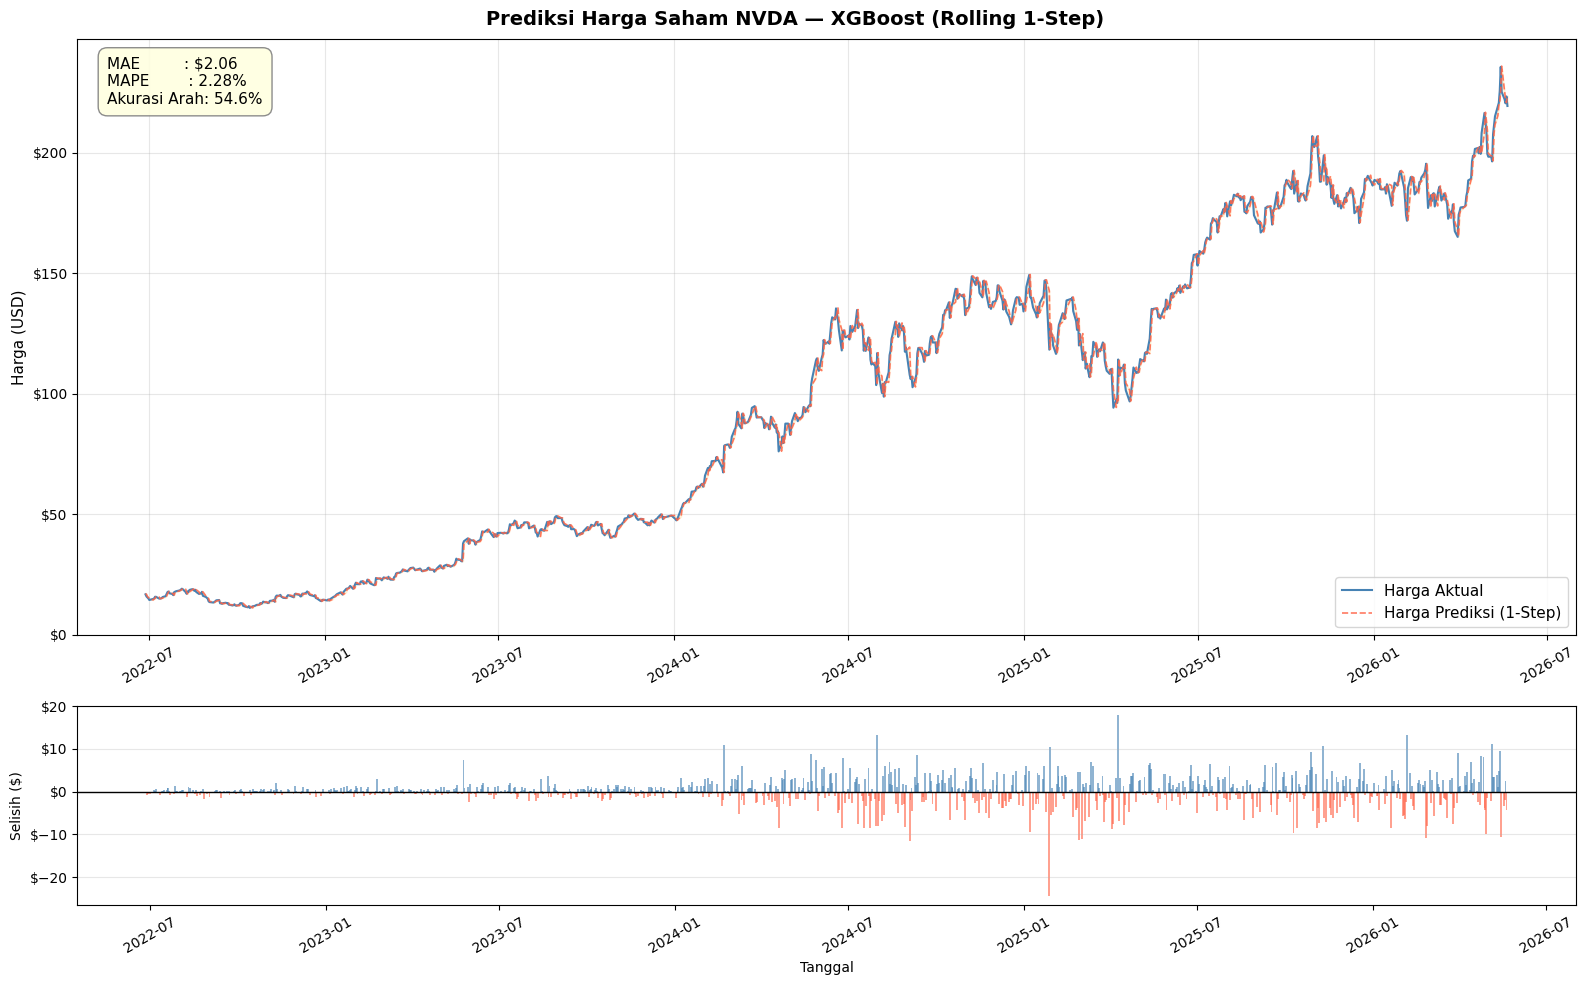

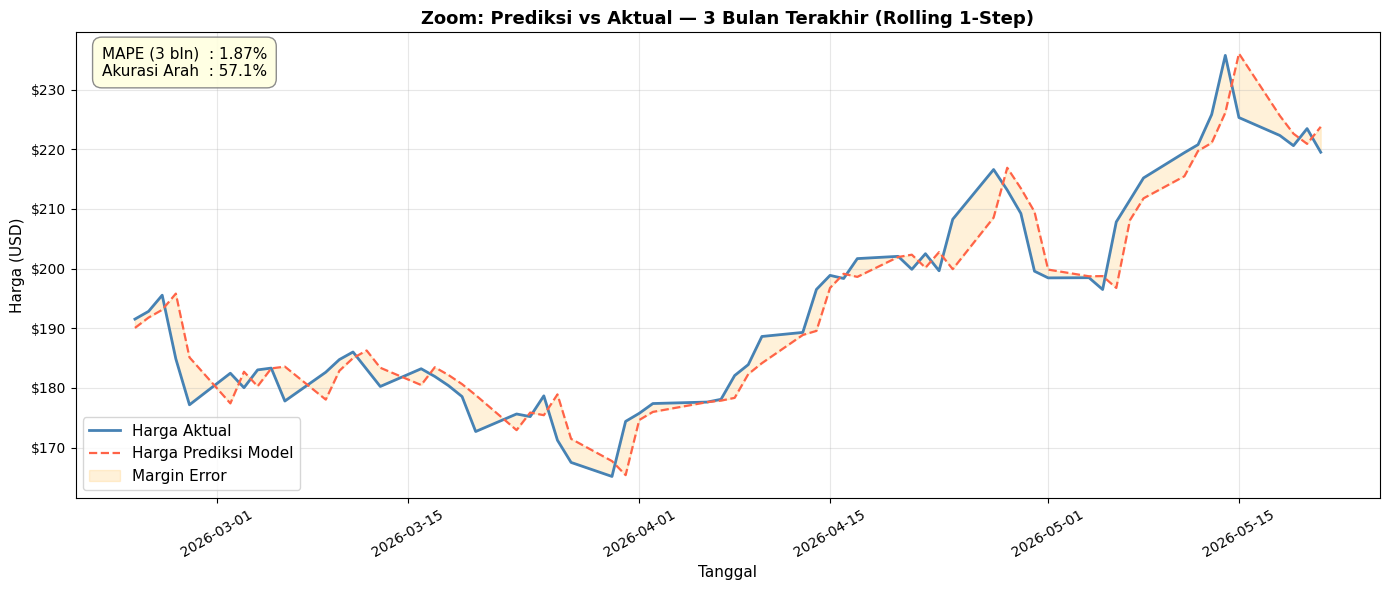


=== METRIK FINAL (ROLLING 1-STEP) ===
MAE Harga    : $2.06
MAPE Harga   : 2.28%
Akurasi Arah : 54.6%


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# =============================================================
# ROLLING 1-STEP: pakai harga aktual kemarin + prediksi return
# Ini cara yang BENAR secara finansial
# predicted_price[t] = actual_price[t-1] × (1 + predicted_return[t])
# =============================================================

# Ambil harga Close aktual untuk seluruh test period
harga_close_aktual = df_nvda.loc[X_test_xgb_sel.index, 'Close'].values

# Geser 1 hari: harga kemarin × return prediksi hari ini
harga_prediksi_rolling = np.zeros(len(harga_close_aktual))
for i in range(len(harga_close_aktual)):
    if i == 0:
        # Hari pertama: pakai harga terakhir sebelum test set
        harga_kemarin = df_nvda.loc[
            df_nvda.index < X_test_xgb_sel.index[0], 'Close'
        ].iloc[-1]
    else:
        harga_kemarin = harga_close_aktual[i - 1]  # ← harga AKTUAL kemarin

    harga_prediksi_rolling[i] = harga_kemarin * (1 + prediksi_test_xgb[i])

tanggal = X_test_xgb_sel.index

# Metrik berbasis harga rolling
mae_rolling  = np.mean(np.abs(harga_close_aktual - harga_prediksi_rolling))
mape_rolling = np.mean(np.abs(
    (harga_close_aktual - harga_prediksi_rolling) / harga_close_aktual
)) * 100
da = (np.sign(y_test.values) == np.sign(prediksi_test_xgb)).mean() * 100


# =============================================================
# GRAFIK FULL PERIOD
# =============================================================
fig, axes = plt.subplots(2, 1, figsize=(16, 10),
                          gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('Prediksi Harga Saham NVDA — XGBoost (Rolling 1-Step)',
             fontsize=14, fontweight='bold')

ax1 = axes[0]
ax1.plot(tanggal, harga_close_aktual,
         label='Harga Aktual', color='steelblue', linewidth=1.5)
ax1.plot(tanggal, harga_prediksi_rolling,
         label='Harga Prediksi (1-Step)', color='tomato',
         linewidth=1.2, linestyle='--', alpha=0.85)
ax1.fill_between(tanggal,
                  harga_close_aktual,
                  harga_prediksi_rolling,
                  alpha=0.12, color='orange')

ax1.text(0.02, 0.97,
         f"MAE         : ${mae_rolling:.2f}\n"
         f"MAPE        : {mape_rolling:.2f}%\n"
         f"Akurasi Arah: {da:.1f}%",
         transform=ax1.transAxes, fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.6',
                   facecolor='lightyellow',
                   edgecolor='gray', alpha=0.9))

ax1.set_ylabel('Harga (USD)', fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)
ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax1.tick_params(axis='x', rotation=30)

# Selisih harga harian
ax2 = axes[1]
gap = harga_close_aktual - harga_prediksi_rolling
ax2.bar(tanggal, gap,
        color=['tomato' if g < 0 else 'steelblue' for g in gap],
        alpha=0.6, width=2)
ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylabel('Selisih ($)', fontsize=10)
ax2.set_xlabel('Tanggal', fontsize=10)
ax2.grid(alpha=0.3, axis='y')
ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('rf_rolling_1step_full.png', dpi=150, bbox_inches='tight')
plt.show()


# =============================================================
# GRAFIK ZOOM 3 BULAN TERAKHIR — untuk presentasi dosen
# =============================================================
zoom_n = 63

fig2, ax3 = plt.subplots(figsize=(14, 6))

ax3.plot(tanggal[-zoom_n:], harga_close_aktual[-zoom_n:],
         label='Harga Aktual', color='steelblue', linewidth=2.0)
ax3.plot(tanggal[-zoom_n:], harga_prediksi_rolling[-zoom_n:],
         label='Harga Prediksi Model', color='tomato',
         linewidth=1.6, linestyle='--')
ax3.fill_between(tanggal[-zoom_n:],
                  harga_close_aktual[-zoom_n:],
                  harga_prediksi_rolling[-zoom_n:],
                  alpha=0.15, color='orange', label='Margin Error')

mape_zoom = np.mean(np.abs(
    (harga_close_aktual[-zoom_n:] - harga_prediksi_rolling[-zoom_n:])
    / harga_close_aktual[-zoom_n:]
)) * 100
da_zoom = (np.sign(y_test.values[-zoom_n:]) ==
           np.sign(prediksi_test_xgb[-zoom_n:])).mean() * 100

ax3.text(0.02, 0.97,
         f"MAPE (3 bln)  : {mape_zoom:.2f}%\n"
         f"Akurasi Arah  : {da_zoom:.1f}%",
         transform=ax3.transAxes, fontsize=11,
         verticalalignment='top',
         bbox=dict(boxstyle='round,pad=0.6',
                   facecolor='lightyellow',
                   edgecolor='gray', alpha=0.9))

ax3.set_title('Zoom: Prediksi vs Aktual — 3 Bulan Terakhir (Rolling 1-Step)',
              fontsize=13, fontweight='bold')
ax3.set_ylabel('Harga (USD)', fontsize=11)
ax3.set_xlabel('Tanggal', fontsize=11)
ax3.legend(fontsize=11)
ax3.grid(alpha=0.3)
ax3.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('rf_rolling_zoom.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n=== METRIK FINAL (ROLLING 1-STEP) ===")
print(f"MAE Harga    : ${mae_rolling:.2f}")
print(f"MAPE Harga   : {mape_rolling:.2f}%")
print(f"Akurasi Arah : {da:.1f}%")

In [ ]:
import optuna
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# =====================================================================
# PRE-FASE: SPLIT DATA YANG BENAR
# =====================================================================
split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]
X_test_all  = X_all_baru.iloc[split_val:]

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

tscv = TimeSeriesSplit(n_splits=5)

print("=" * 55)
print("SPLIT DATA (LIGHTGBM PIPELINE)")
print("=" * 55)
print(f"  Train      : {len(X_train_all):>5} baris (70%)")
print(f"  Validation : {len(X_val_all):>5} baris (15%)")
print(f"  Test       : {len(X_test_all):>5} baris (15%)")
print(f"  Total fitur: {X_train_all.shape[1]}")


# =====================================================================
# FASE 1: TUNING OPTUNA PADA SEMUA FITUR
# =====================================================================
print("\n" + "=" * 55)
print("FASE 1: Tuning Optuna LightGBM pada Semua Fitur...")
print("=" * 55)

def objective_lgb_all(trial):
    param = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 400),
        'max_depth':         trial.suggest_int('max_depth', 3, 9),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'num_leaves':        trial.suggest_int('num_leaves', 15, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-5, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-5, 10.0, log=True),
    }

    model = LGBMRegressor(
        **param,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    return cross_val_score(
        model,
        X_train_all,
        y_train,
        cv=tscv,
        scoring=da_scorer
    ).mean()

study_lgb_all = optuna.create_study(direction='maximize')
study_lgb_all.optimize(objective_lgb_all, n_trials=50)

best_lgb_all = LGBMRegressor(
    **study_lgb_all.best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

best_lgb_all.fit(X_train_all, y_train)

print(f"✓ Selesai. Best DA CV: {study_lgb_all.best_value:.5f}")
print(f"  Parameter: {study_lgb_all.best_params}")


# =====================================================================
# FASE 2A: PERMUTATION IMPORTANCE PADA VALIDATION SET
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2A: Permutation Importance LightGBM pada Validation Set...")
print("=" * 55)

perm_result_lgb = permutation_importance(
    best_lgb_all,
    X_val_all,
    y_val,
    scoring=da_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df_lgb = pd.DataFrame({
    'Fitur':    X_val_all.columns,
    'Skor_DA':  perm_result_lgb.importances_mean,
    'Skor_Std': perm_result_lgb.importances_std
}).sort_values(by='Skor_DA', ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur LightGBM (Permutation Importance):")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 60)

for i, row in perm_df_lgb.head(20).iterrows():
    print(f"{i+1:<4} {row['Fitur']:<35} {row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}")


# =====================================================================
# FASE 2B: SELEKSI FITUR BERBASIS STATISTIK + DEDUP
# =====================================================================
print("\n" + "=" * 55)
print("FASE 2B: Seleksi Fitur LightGBM Berbasis Statistik...")
print("=" * 55)

kelompok_fitur = {
    'lag_close':    [f'lag_close_{l}'  for l in [1, 3, 7, 14, 21, 30]],
    'lag_volume':   [f'lag_volume_{l}' for l in [1, 3, 7, 14, 21, 30]],
    'lag_return':   [f'lag_return_{l}' for l in [14, 21, 30]],
    'momentum':     [f'momentum_{l}d'  for l in [14, 21, 30]] + ['ROC_10', 'ROC_20'],
    'rolling_mean': [f'rolling_mean_close_{w}' for w in [7, 14, 21, 30]],
    'rolling_std':  [f'rolling_std_close_{w}'  for w in [7, 14, 21, 30]],
    'hv':           ['HV_10', 'HV_20', 'HV_30'],
    'sma':          ['SMA_20', 'SMA_50'],
    'bb_band':      ['BBU_20_2', 'BBL_20_2', 'BBM_20_2', 'BBB_20_2', 'BBP_20_2'],
    'macd':         ['MACD_12_26_9', 'MACDs_12_26_9', 'MACDh_12_26_9'],
    'rs_spy':       ['RS_vs_SPY', 'RS_vs_SPY_zscore', 'RS_SPY_trending_up'],
    'rs_qqq':       ['RS_vs_QQQ', 'RS_vs_QQQ_zscore', 'RS_QQQ_trending_up'],
    'vix':          ['VIX_Close', 'VIX_Change', 'VIX_MA5', 'VIX_spike', 'VIX_above_MA5'],
    'obv':          ['OBV_zscore', 'OBV_above_MA20'],
    'ad':           ['AD_Line', 'AD_zscore'],
    'volume_flow':  ['volume_spike', 'volume_ratio_MA20'],
}

fitur_ke_kelompok = {f: k for k, v in kelompok_fitur.items() for f in v}

def seleksi_fitur_lgb(perm_df, mapping, min_features=10, top_k_fallback=20):
    threshold = perm_df['Skor_DA'].std()
    kandidat = perm_df[perm_df['Skor_DA'] > threshold].copy()

    fitur_terpilih = []
    kelompok_terpakai = set()

    for _, row in kandidat.iterrows():
        fitur = row['Fitur']
        kelompok = mapping.get(fitur, f'_solo_{fitur}')

        if kelompok not in kelompok_terpakai:
            fitur_terpilih.append(fitur)
            kelompok_terpakai.add(kelompok)

    if len(fitur_terpilih) < min_features:
        print(f"Peringatan: fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)['Fitur'].tolist()

    return fitur_terpilih, threshold

fitur_lgb_terpilih, threshold_lgb = seleksi_fitur_lgb(
    perm_df_lgb,
    fitur_ke_kelompok,
    min_features=10,
    top_k_fallback=20
)

print(f"Threshold statistis : {threshold_lgb:.5f}")
print(f"Fitur terpilih      : {len(fitur_lgb_terpilih)} fitur\n")

for i, f in enumerate(fitur_lgb_terpilih, 1):
    skor = perm_df_lgb.loc[perm_df_lgb['Fitur'] == f, 'Skor_DA'].values[0]
    print(f"  {i:>2}. {f:<35} (DA: {skor:.5f})")

X_train_lgb_sel = X_train_all[fitur_lgb_terpilih]
X_val_lgb_sel   = X_val_all[fitur_lgb_terpilih]
X_test_lgb_sel  = X_test_all[fitur_lgb_terpilih]


# =====================================================================
# FASE 3: TUNING ULANG OPTUNA PADA FITUR TERPILIH
# =====================================================================
print("\n" + "=" * 55)
print("FASE 3: Tuning Ulang LightGBM pada Fitur Terpilih...")
print("=" * 55)

def objective_lgb_final(trial):
    param = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 600),
        'max_depth':         trial.suggest_int('max_depth', 2, 7),
        'learning_rate':     trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'num_leaves':        trial.suggest_int('num_leaves', 7, 63),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-5, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-5, 10.0, log=True),
    }

    model = LGBMRegressor(
        **param,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    return cross_val_score(
        model,
        X_train_lgb_sel,
        y_train,
        cv=tscv,
        scoring=da_scorer
    ).mean()

study_lgb_final = optuna.create_study(direction='maximize')
study_lgb_final.optimize(objective_lgb_final, n_trials=100)

best_lgb_final = LGBMRegressor(
    **study_lgb_final.best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

best_lgb_final.fit(X_train_lgb_sel, y_train)

print(f"✓ Selesai. Best DA CV: {study_lgb_final.best_value:.5f}")
print(f"  Parameter: {study_lgb_final.best_params}")


# =====================================================================
# EVALUASI MODEL FINAL
# =====================================================================
print("\n" + "=" * 55)
print("EVALUASI MODEL FINAL LIGHTGBM")
print("=" * 55)

prediksi_train_lgb = best_lgb_final.predict(X_train_lgb_sel)
prediksi_test_lgb  = best_lgb_final.predict(X_test_lgb_sel)

print(f"Fitur yang digunakan ({len(fitur_lgb_terpilih)}): {fitur_lgb_terpilih}\n")

print("[DATA TRAIN - Masa Lalu]")
print(f"MAE Train  : {mean_absolute_error(y_train, prediksi_train_lgb):.5f}")
print(f"RMSE Train : {np.sqrt(mean_squared_error(y_train, prediksi_train_lgb)):.5f}")
print(f"R2 Train   : {r2_score(y_train, prediksi_train_lgb):.5f}")
print(f"DA Train   : {directional_accuracy(y_train, prediksi_train_lgb):.5f}")

print("\n[DATA TEST - Masa Depan (Realita Pasar)]")
print(f"MAE Test   : {mean_absolute_error(y_test, prediksi_test_lgb):.5f}")
print(f"RMSE Test  : {np.sqrt(mean_squared_error(y_test, prediksi_test_lgb)):.5f}")
print(f"R2 Test    : {r2_score(y_test, prediksi_test_lgb):.5f}")
print(f"DA Test    : {directional_accuracy(y_test, prediksi_test_lgb):.5f}")

SPLIT DATA (LIGHTGBM PIPELINE)
  Train      :  4570 baris (70%)
  Validation :   979 baris (15%)
  Test       :   980 baris (15%)
  Total fitur: 71

FASE 1: Tuning Optuna LightGBM pada Semua Fitur...
✓ Selesai. Best DA CV: 0.51643
  Parameter: {'n_estimators': 114, 'max_depth': 3, 'learning_rate': 0.010799346008834141, 'subsample': 0.7749338801083677, 'colsample_bytree': 0.6989580314233927, 'num_leaves': 38, 'min_child_samples': 56, 'reg_alpha': 3.7762128388555234, 'reg_lambda': 6.5089062720012e-05}

FASE 2A: Permutation Importance LightGBM pada Validation Set...

Top 20 Fitur LightGBM (Permutation Importance):
No   Fitur                                  Skor_DA     ±Std
------------------------------------------------------------
1    RSI_14                                 0.00000  0.00000
2    Volume                                 0.00000  0.00000
3    Return_Hari_Ini                        0.00000  0.00000
4    lag_volume_7                           0.00000  0.00000
5    MACDh_12_2

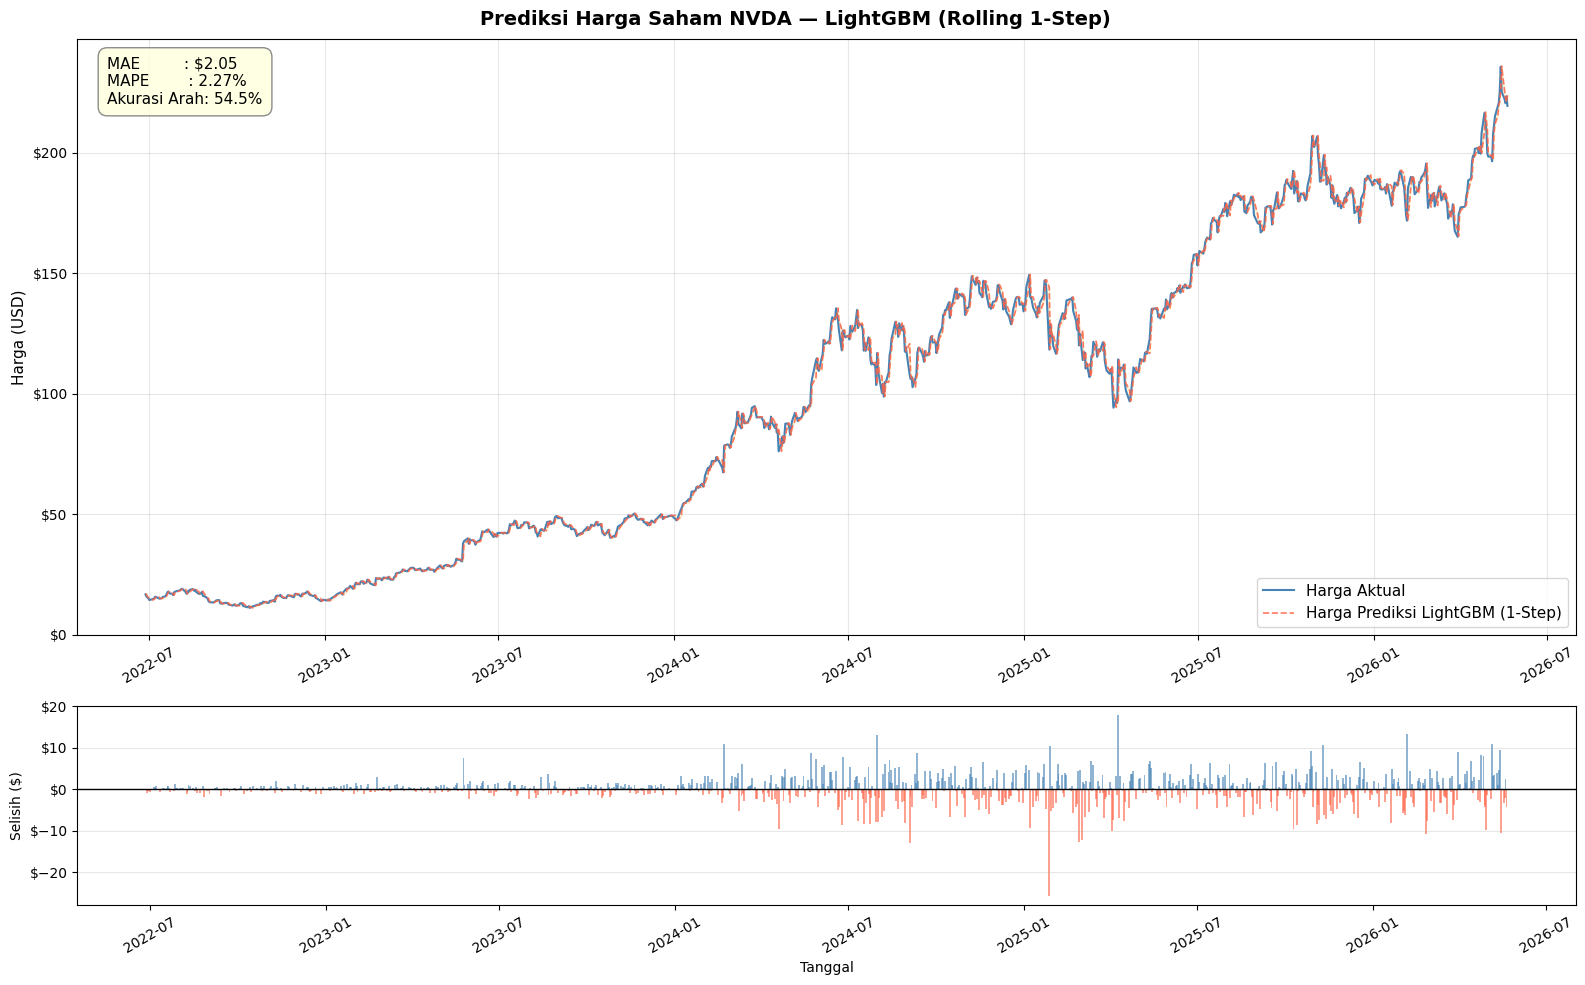

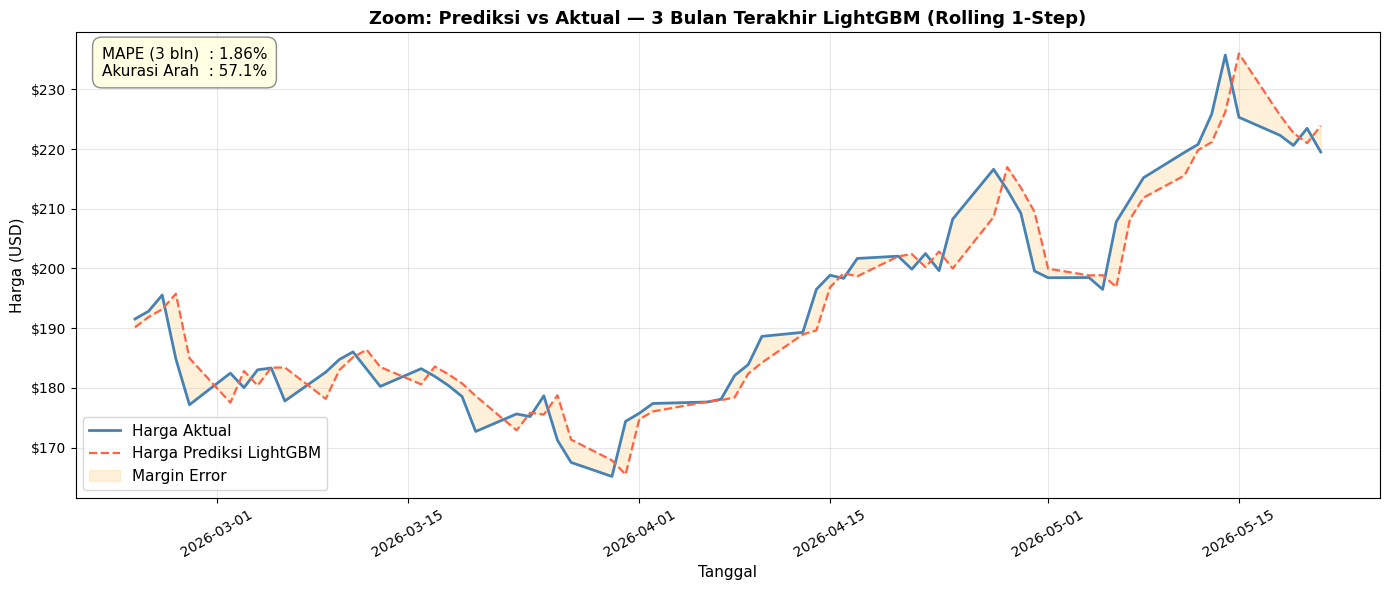


=== METRIK FINAL LIGHTGBM (ROLLING 1-STEP) ===
MAE Harga    : $2.05
MAPE Harga   : 2.27%
Akurasi Arah : 54.5%


In [ ]:
# =============================================================
# CELL: ROLLING 1-STEP PRICE PLOT — LIGHTGBM
# =============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# =============================================================
# ROLLING 1-STEP:
# predicted_price[t] = actual_price[t-1] × (1 + predicted_return[t])
# =============================================================

# Ambil harga Close aktual untuk seluruh test period
harga_close_aktual_lgb = df_nvda.loc[X_test_lgb_sel.index, 'Close'].values

# Geser 1 hari: harga kemarin × return prediksi hari ini
harga_prediksi_rolling_lgb = np.zeros(len(harga_close_aktual_lgb))

for i in range(len(harga_close_aktual_lgb)):
    if i == 0:
        # Hari pertama: pakai harga terakhir sebelum test set
        harga_kemarin = df_nvda.loc[
            df_nvda.index < X_test_lgb_sel.index[0], 'Close'
        ].iloc[-1]
    else:
        harga_kemarin = harga_close_aktual_lgb[i - 1]

    harga_prediksi_rolling_lgb[i] = harga_kemarin * (1 + prediksi_test_lgb[i])

tanggal_lgb = X_test_lgb_sel.index

# Metrik berbasis harga rolling
mae_rolling_lgb = np.mean(np.abs(harga_close_aktual_lgb - harga_prediksi_rolling_lgb))

mape_rolling_lgb = np.mean(np.abs(
    (harga_close_aktual_lgb - harga_prediksi_rolling_lgb) / harga_close_aktual_lgb
)) * 100

da_lgb = (np.sign(y_test.values) == np.sign(prediksi_test_lgb)).mean() * 100


# =============================================================
# GRAFIK FULL PERIOD — LIGHTGBM
# =============================================================
fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 10),
    gridspec_kw={'height_ratios': [3, 1]}
)

fig.suptitle(
    'Prediksi Harga Saham NVDA — LightGBM (Rolling 1-Step)',
    fontsize=14,
    fontweight='bold'
)

ax1 = axes[0]

ax1.plot(
    tanggal_lgb,
    harga_close_aktual_lgb,
    label='Harga Aktual',
    color='steelblue',
    linewidth=1.5
)

ax1.plot(
    tanggal_lgb,
    harga_prediksi_rolling_lgb,
    label='Harga Prediksi LightGBM (1-Step)',
    color='tomato',
    linewidth=1.2,
    linestyle='--',
    alpha=0.85
)

ax1.fill_between(
    tanggal_lgb,
    harga_close_aktual_lgb,
    harga_prediksi_rolling_lgb,
    alpha=0.12,
    color='orange'
)

ax1.text(
    0.02,
    0.97,
    f"MAE         : ${mae_rolling_lgb:.2f}\n"
    f"MAPE        : {mape_rolling_lgb:.2f}%\n"
    f"Akurasi Arah: {da_lgb:.1f}%",
    transform=ax1.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round,pad=0.6',
        facecolor='lightyellow',
        edgecolor='gray',
        alpha=0.9
    )
)

ax1.set_ylabel('Harga (USD)', fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)
ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax1.tick_params(axis='x', rotation=30)

# Selisih harga harian
ax2 = axes[1]

gap_lgb = harga_close_aktual_lgb - harga_prediksi_rolling_lgb

ax2.bar(
    tanggal_lgb,
    gap_lgb,
    color=['tomato' if g < 0 else 'steelblue' for g in gap_lgb],
    alpha=0.6,
    width=2
)

ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylabel('Selisih ($)', fontsize=10)
ax2.set_xlabel('Tanggal', fontsize=10)
ax2.grid(alpha=0.3, axis='y')
ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('lgb_rolling_1step_full.png', dpi=150, bbox_inches='tight')
plt.show()


# =============================================================
# GRAFIK ZOOM 3 BULAN TERAKHIR — LIGHTGBM
# =============================================================
zoom_n = 63

fig2, ax3 = plt.subplots(figsize=(14, 6))

ax3.plot(
    tanggal_lgb[-zoom_n:],
    harga_close_aktual_lgb[-zoom_n:],
    label='Harga Aktual',
    color='steelblue',
    linewidth=2.0
)

ax3.plot(
    tanggal_lgb[-zoom_n:],
    harga_prediksi_rolling_lgb[-zoom_n:],
    label='Harga Prediksi LightGBM',
    color='tomato',
    linewidth=1.6,
    linestyle='--'
)

ax3.fill_between(
    tanggal_lgb[-zoom_n:],
    harga_close_aktual_lgb[-zoom_n:],
    harga_prediksi_rolling_lgb[-zoom_n:],
    alpha=0.15,
    color='orange',
    label='Margin Error'
)

mape_zoom_lgb = np.mean(np.abs(
    (harga_close_aktual_lgb[-zoom_n:] - harga_prediksi_rolling_lgb[-zoom_n:])
    / harga_close_aktual_lgb[-zoom_n:]
)) * 100

da_zoom_lgb = (
    np.sign(y_test.values[-zoom_n:]) ==
    np.sign(prediksi_test_lgb[-zoom_n:])
).mean() * 100

ax3.text(
    0.02,
    0.97,
    f"MAPE (3 bln)  : {mape_zoom_lgb:.2f}%\n"
    f"Akurasi Arah  : {da_zoom_lgb:.1f}%",
    transform=ax3.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round,pad=0.6',
        facecolor='lightyellow',
        edgecolor='gray',
        alpha=0.9
    )
)

ax3.set_title(
    'Zoom: Prediksi vs Aktual — 3 Bulan Terakhir LightGBM (Rolling 1-Step)',
    fontsize=13,
    fontweight='bold'
)

ax3.set_ylabel('Harga (USD)', fontsize=11)
ax3.set_xlabel('Tanggal', fontsize=11)
ax3.legend(fontsize=11)
ax3.grid(alpha=0.3)
ax3.yaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
ax3.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('lgb_rolling_zoom.png', dpi=150, bbox_inches='tight')
plt.show()


print("\n=== METRIK FINAL LIGHTGBM (ROLLING 1-STEP) ===")
print(f"MAE Harga    : ${mae_rolling_lgb:.2f}")
print(f"MAPE Harga   : {mape_rolling_lgb:.2f}%")
print(f"Akurasi Arah : {da_lgb:.1f}%")

In [ ]:
# ==============================================================================
# LSTM OPTIMAL
# Tempelkan cell-cell ini menggantikan cell LSTM yang lama
# Prasyarat: fitur_lgb_terpilih, X_all_baru, y, da_scorer sudah ada
# ==============================================================================

# %% =========================================================================
# CELL L-0: INSTALASI & IMPORT
# =============================================================================
# !pip install optuna tensorflow keras

import numpy as np
import pandas as pd
import tensorflow as tf
import optuna
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, GRU, Bidirectional, Dense, Dropout,
    LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D,
    Concatenate, Add
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)


# %% =========================================================================
# CELL L-1: SPLIT DATA LSTM — FITUR AWAL MILIK LSTM SENDIRI
# =============================================================================

print("=" * 60)
print("CELL L-1: Split Data LSTM dengan Semua Fitur Kandidat")
print("=" * 60)

# LSTM tidak lagi memakai fitur_lgb_terpilih.
# LSTM akan melakukan seleksi fitur sendiri lewat permutation importance.
fitur_lstm_awal = X_all_baru.columns.tolist()

X_lstm_raw = X_all_baru[fitur_lstm_awal].values
y_lstm_raw = y.values.reshape(-1, 1)

n = len(X_lstm_raw)
split_train = int(n * 0.70)
split_val   = int(n * 0.85)

X_tr_raw = X_lstm_raw[:split_train]
X_va_raw = X_lstm_raw[split_train:split_val]
X_te_raw = X_lstm_raw[split_val:]

y_tr_raw = y_lstm_raw[:split_train]
y_va_raw = y_lstm_raw[split_train:split_val]
y_te_raw = y_lstm_raw[split_val:]

scaler_X = RobustScaler()
scaler_y = RobustScaler()

X_tr_sc = scaler_X.fit_transform(X_tr_raw)
X_va_sc = scaler_X.transform(X_va_raw)
X_te_sc = scaler_X.transform(X_te_raw)

y_tr_sc = scaler_y.fit_transform(y_tr_raw)
y_va_sc = scaler_y.transform(y_va_raw)
y_te_sc = scaler_y.transform(y_te_raw)

print(f"  Train  : {len(X_tr_raw):>5} baris (70%)")
print(f"  Val    : {len(X_va_raw):>5} baris (15%)")
print(f"  Test   : {len(X_te_raw):>5} baris (15%)")
print(f"  Fitur awal LSTM : {len(fitur_lstm_awal)} fitur")
print(f"  Scaler : RobustScaler")


# %% =========================================================================
# CELL L-2: FUNGSI SEQUENCE & DIRECTIONAL ACCURACY
# =============================================================================
TIME_STEPS = 15  # Diperbesar dari 10 → tangkap pola 3-minggu perdagangan

def create_sequences(X, y, time_steps):
    """Buat urutan waktu untuk LSTM. Hasil: (n_samples, time_steps, n_features)"""
    X_out, y_out = [], []
    for i in range(len(X) - time_steps):
        X_out.append(X[i : i + time_steps])
        y_out.append(y[i + time_steps])
    return np.array(X_out), np.array(y_out)

X_tr_seq, y_tr_seq = create_sequences(X_tr_sc, y_tr_sc, TIME_STEPS)
X_va_seq, y_va_seq = create_sequences(X_va_sc, y_va_sc, TIME_STEPS)
X_te_seq, y_te_seq = create_sequences(X_te_sc, y_te_sc, TIME_STEPS)

# Untuk evaluasi di skala asli (setelah inverse transform)
_, y_tr_true = create_sequences(X_tr_sc, y_tr_raw, TIME_STEPS)
_, y_va_true = create_sequences(X_va_sc, y_va_raw, TIME_STEPS)
_, y_te_true = create_sequences(X_te_sc, y_te_raw, TIME_STEPS)

# Directional Accuracy (DA) — sama dengan LightGBM
def directional_accuracy(y_true, y_pred):
    return np.mean(np.sign(y_true.flatten()) == np.sign(y_pred.flatten()))

# Custom Keras metric untuk monitoring selama training
class DirectionalAccuracy(tf.keras.metrics.Metric):
    def __init__(self, name='DA', **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_weight(name='correct', initializer='zeros')
        self.total   = self.add_weight(name='total',   initializer='zeros')
    def update_state(self, y_true, y_pred, sample_weight=None):
        correct = tf.reduce_sum(
            tf.cast(tf.sign(y_true) == tf.sign(y_pred), tf.float32))
        self.correct.assign_add(correct)
        self.total.assign_add(tf.cast(tf.size(y_true), tf.float32))
    def result(self):
        return tf.math.divide_no_nan(self.correct, self.total)
    def reset_state(self):
        self.correct.assign(0.)
        self.total.assign(0.)

print(f"  Sequence shape Train : {X_tr_seq.shape}")
print(f"  Sequence shape Val   : {X_va_seq.shape}")
print(f"  Sequence shape Test  : {X_te_seq.shape}")


# %% =========================================================================
# CELL L-3: ARSITEKTUR MODEL — BiLSTM + ATTENTION
# Upgrade dari 2 LSTM biasa menjadi:
#   1. Bidirectional LSTM: belajar pola dari dua arah
#   2. Multi-Head Attention: fokus pada timestep yang paling informatif
#   3. Residual Connection: stabilkan gradien di jaringan dalam
#   4. LayerNorm: normalisasi internal lebih baik dari BatchNorm untuk time-series
# =============================================================================
def build_bilstm_attention(
    input_shape,
    lstm_units_1=64,
    lstm_units_2=48,
    attn_heads=4,
    dense_units=32,
    dropout_rate=0.3,
    l2_reg=1e-4,
    learning_rate=1e-3,
):
    """
    Arsitektur BiLSTM + Multi-Head Self-Attention
    ─────────────────────────────────────────────
    Input → BiLSTM(return_sequences) → LayerNorm
          → BiLSTM(return_sequences) → LayerNorm
          → MultiHeadAttention (self) → LayerNorm + Residual
          → GlobalAveragePooling
          → Dense → Dropout → Dense(1)
    """
    inp = Input(shape=input_shape, name='input_seq')

    # --- Layer 1: Bidirectional LSTM ---
    x = Bidirectional(
        LSTM(lstm_units_1, return_sequences=True,
             kernel_regularizer=l2(l2_reg),
             recurrent_regularizer=l2(l2_reg / 10)),
        name='bilstm_1'
    )(inp)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # --- Layer 2: Bidirectional LSTM ---
    x = Bidirectional(
        LSTM(lstm_units_2, return_sequences=True,
             kernel_regularizer=l2(l2_reg),
             recurrent_regularizer=l2(l2_reg / 10)),
        name='bilstm_2'
    )(x)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # --- Layer 3: Multi-Head Self-Attention ---
    attn_out = MultiHeadAttention(
        num_heads=attn_heads,
        key_dim=max(lstm_units_2 * 2 // attn_heads, 8),
        dropout=dropout_rate / 2,
        name='mha'
    )(x, x)

    # Residual connection + LayerNorm (seperti Transformer)
    x = LayerNormalization()(Add()([x, attn_out]))

    # --- Pooling: ambil representasi seluruh sequence ---
    x = GlobalAveragePooling1D()(x)

    # --- Head Regresi ---
    x = Dense(dense_units, activation='gelu',
               kernel_regularizer=l2(l2_reg))(x)
    x = Dropout(dropout_rate / 2)(x)
    out = Dense(1, name='output')(x)

    model = Model(inputs=inp, outputs=out)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate,
                       clipnorm=1.0),        # Gradient clipping cegah exploding gradient
        loss='huber',                         # Tahan terhadap outlier return ekstrem
        metrics=[DirectionalAccuracy()]
    )
    return model

# Preview arsitektur
sample_model = build_bilstm_attention(
    input_shape=(TIME_STEPS, X_tr_seq.shape[2]))
sample_model.summary()

# %% =========================================================================
# CELL L-3A: BASELINE MODEL — LSTM SEDERHANA & GRU SEDERHANA
# Tujuan:
#   Membuktikan apakah BiLSTM + Attention memang lebih baik dari arsitektur sederhana.
#   Tanpa baseline ini, klaim "arsitektur kompleks lebih baik" belum kuat.
# =============================================================================

def build_simple_lstm(
    input_shape,
    units_1=64,
    units_2=32,
    dense_units=32,
    dropout_rate=0.3,
    l2_reg=1e-4,
    learning_rate=1e-3
):
    """
    Baseline LSTM searah.
    Lebih kausal secara intuitif dibanding BiLSTM karena membaca sequence dari kiri ke kanan.
    """
    inp = Input(shape=input_shape, name='input_seq')

    x = LSTM(
        units_1,
        return_sequences=True,
        kernel_regularizer=l2(l2_reg),
        recurrent_regularizer=l2(l2_reg / 10)
    )(inp)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = LSTM(
        units_2,
        return_sequences=False,
        kernel_regularizer=l2(l2_reg),
        recurrent_regularizer=l2(l2_reg / 10)
    )(x)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = Dense(dense_units, activation='gelu', kernel_regularizer=l2(l2_reg))(x)
    x = Dropout(dropout_rate / 2)(x)
    out = Dense(1)(x)

    model = Model(inputs=inp, outputs=out)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss='huber',
        metrics=[DirectionalAccuracy()]
    )
    return model


def build_simple_gru(
    input_shape,
    units_1=64,
    units_2=32,
    dense_units=32,
    dropout_rate=0.3,
    l2_reg=1e-4,
    learning_rate=1e-3
):
    """
    Baseline GRU.
    GRU biasanya lebih ringan dan lebih cepat konvergen daripada LSTM.
    """
    inp = Input(shape=input_shape, name='input_seq')

    x = GRU(
        units_1,
        return_sequences=True,
        kernel_regularizer=l2(l2_reg),
        recurrent_regularizer=l2(l2_reg / 10)
    )(inp)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = GRU(
        units_2,
        return_sequences=False,
        kernel_regularizer=l2(l2_reg),
        recurrent_regularizer=l2(l2_reg / 10)
    )(x)
    x = LayerNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = Dense(dense_units, activation='gelu', kernel_regularizer=l2(l2_reg))(x)
    x = Dropout(dropout_rate / 2)(x)
    out = Dense(1)(x)

    model = Model(inputs=inp, outputs=out)
    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss='huber',
        metrics=[DirectionalAccuracy()]
    )
    return model


# %% =========================================================================
# CELL L-4: OPTUNA TUNING — SEJAJAR DENGAN LIGHTGBM
# Mencari hyperparameter optimal dengan 40 trials Bayesian optimization
# =============================================================================
print("=" * 60)
print("CELL L-4: Tuning Optuna BiLSTM-Attention (40 trials)...")
print("=" * 60)

def objective_lstm(trial):
    # Search space hyperparameter
    lstm_u1    = trial.suggest_int('lstm_units_1', 32, 128, step=16)
    lstm_u2    = trial.suggest_int('lstm_units_2', 24, 96,  step=8)
    attn_heads = trial.suggest_categorical('attn_heads', [2, 4, 8])
    dense_u    = trial.suggest_int('dense_units', 16, 64, step=8)
    dropout    = trial.suggest_float('dropout_rate', 0.1, 0.5)
    l2_reg     = trial.suggest_float('l2_reg', 1e-5, 1e-2, log=True)
    lr         = trial.suggest_float('learning_rate', 1e-4, 5e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    time_steps = trial.suggest_categorical('time_steps', [10, 15, 20])

    # Buat ulang sequences dengan time_steps yang di-trial
    X_tr_t, y_tr_t = create_sequences(X_tr_sc, y_tr_sc, time_steps)
    X_va_t, y_va_t = create_sequences(X_va_sc, y_va_sc, time_steps)
    _, y_va_true_t  = create_sequences(X_va_sc, y_va_raw, time_steps)

    # Pastikan attn_heads bisa membagi dimensi BiLSTM output
    bilstm_out_dim = lstm_u2 * 2
    if bilstm_out_dim % attn_heads != 0:
        attn_heads = 2  # fallback aman

    model = build_bilstm_attention(
        input_shape=(time_steps, X_tr_t.shape[2]),
        lstm_units_1=lstm_u1,
        lstm_units_2=lstm_u2,
        attn_heads=attn_heads,
        dense_units=dense_u,
        dropout_rate=dropout,
        l2_reg=l2_reg,
        learning_rate=lr
    )

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=8,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=4, min_lr=1e-6, verbose=0)
    ]

    model.fit(
        X_tr_t, y_tr_t,
        validation_data=(X_va_t, y_va_t),
        epochs=60,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0
    )

    # Evaluasi DA di validation set (skala asli)
    pred_scaled = model.predict(X_va_t, verbose=0)
    pred_asli   = scaler_y.inverse_transform(pred_scaled).flatten()
    da_val      = directional_accuracy(y_va_true_t.flatten(), pred_asli)

    del model
    tf.keras.backend.clear_session()
    return da_val

study_lstm = optuna.create_study(direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42))
study_lstm.optimize(objective_lstm, n_trials=10,
    callbacks=[lambda s, t: print(
        f"  Trial {t.number:>3} | DA={t.value:.5f} | best={s.best_value:.5f}"
    ) if t.number % 5 == 0 else None
    ])

print(f"\n✓ Tuning selesai.")
print(f"  Best DA (Val) : {study_lstm.best_value:.5f}")
print(f"  Best params   : {study_lstm.best_params}")

# %% =========================================================================
# CELL L-4A: TRAIN MODEL AWAL LSTM DENGAN SEMUA FITUR
# Tujuan: model awal ini dipakai untuk menghitung permutation importance LSTM.
# =============================================================================

print("=" * 60)
print("CELL L-4A: Training Model Awal LSTM untuk Permutation Importance")
print("=" * 60)

bp = study_lstm.best_params

BEST_TS_AWAL = bp.get('time_steps', TIME_STEPS)

X_tr_awal, y_tr_awal = create_sequences(X_tr_sc, y_tr_sc, BEST_TS_AWAL)
X_va_awal, y_va_awal = create_sequences(X_va_sc, y_va_sc, BEST_TS_AWAL)
X_te_awal, y_te_awal = create_sequences(X_te_sc, y_te_sc, BEST_TS_AWAL)

_, y_va_true_awal = create_sequences(X_va_sc, y_va_raw, BEST_TS_AWAL)

bilstm_out_dim = bp.get('lstm_units_2', 48) * 2
attn_heads_best = bp.get('attn_heads', 4)

if bilstm_out_dim % attn_heads_best != 0:
    attn_heads_best = 2

model_lstm_awal = build_bilstm_attention(
    input_shape=(BEST_TS_AWAL, X_tr_awal.shape[2]),
    lstm_units_1=bp.get('lstm_units_1', 64),
    lstm_units_2=bp.get('lstm_units_2', 48),
    attn_heads=attn_heads_best,
    dense_units=bp.get('dense_units', 32),
    dropout_rate=bp.get('dropout_rate', 0.3),
    l2_reg=bp.get('l2_reg', 1e-4),
    learning_rate=bp.get('learning_rate', 1e-3)
)

callbacks_awal = [
    EarlyStopping(
        monitor='val_loss',
        patience=12,
        mode='min',
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        mode='min',
        verbose=1
    )
]

history_lstm_awal = model_lstm_awal.fit(
    X_tr_awal,
    y_tr_awal,
    validation_data=(X_va_awal, y_va_awal),
    epochs=120,
    batch_size=bp.get('batch_size', 32),
    callbacks=callbacks_awal,
    verbose=1
)

pred_va_awal_sc = model_lstm_awal.predict(X_va_awal, verbose=0)
pred_va_awal = scaler_y.inverse_transform(pred_va_awal_sc).flatten()

da_val_awal = directional_accuracy(y_va_true_awal.flatten(), pred_va_awal)

print(f"\n✓ Model awal selesai.")
print(f"  DA Validation awal: {da_val_awal:.5f}")
print(f"  Jumlah fitur awal : {len(fitur_lstm_awal)}")

# %% =========================================================================
# CELL L-4B: PERMUTATION IMPORTANCE KHUSUS LSTM
# =============================================================================

print("=" * 60)
print("CELL L-4B: Permutation Importance LSTM pada Validation Set")
print("=" * 60)

def lstm_permutation_importance(
    model,
    X_val_seq,
    y_val_true_asli,
    scaler_y,
    fitur_names,
    n_repeats=1,
    random_state=42
):
    """
    Permutation importance khusus LSTM.

    Cara kerja:
    1. Hitung DA validation normal.
    2. Untuk setiap fitur, acak nilai fitur tersebut pada validation sequence.
    3. Hitung ulang DA.
    4. Importance = DA normal - DA setelah fitur diacak.

    Jika importance positif besar, berarti fitur penting.
    """
    rng = np.random.default_rng(random_state)

    pred_base_sc = model.predict(X_val_seq, verbose=0)
    pred_base = scaler_y.inverse_transform(pred_base_sc).flatten()
    base_da = directional_accuracy(y_val_true_asli.flatten(), pred_base)

    hasil = []

    for j, fitur in enumerate(fitur_names):
        scores = []

        for _ in range(n_repeats):
            X_perm = X_val_seq.copy()

            # Ambil seluruh nilai fitur j dari semua sample dan semua timestep
            nilai_flat = X_perm[:, :, j].reshape(-1).copy()

            # Acak nilai fitur tersebut
            rng.shuffle(nilai_flat)

            # Masukkan kembali ke posisi fitur j
            X_perm[:, :, j] = nilai_flat.reshape(X_perm[:, :, j].shape)

            pred_perm_sc = model.predict(X_perm, verbose=0)
            pred_perm = scaler_y.inverse_transform(pred_perm_sc).flatten()

            perm_da = directional_accuracy(y_val_true_asli.flatten(), pred_perm)
            importance = base_da - perm_da
            scores.append(importance)

        hasil.append({
            'Fitur': fitur,
            'Skor_DA': np.mean(scores),
            'Skor_Std': np.std(scores)
        })

        if (j + 1) % 10 == 0:
            print(f"  Selesai {j+1}/{len(fitur_names)} fitur...")

    perm_df = pd.DataFrame(hasil)
    perm_df = perm_df.sort_values(by='Skor_DA', ascending=False).reset_index(drop=True)

    return perm_df, base_da


perm_df_lstm, base_da_lstm = lstm_permutation_importance(
    model=model_lstm_awal,
    X_val_seq=X_va_awal,
    y_val_true_asli=y_va_true_awal,
    scaler_y=scaler_y,
    fitur_names=fitur_lstm_awal,
    n_repeats=3,
    random_state=42
)

print(f"\nDA Validation sebelum permutation: {base_da_lstm:.5f}")

print("\nTop 20 Fitur LSTM berdasarkan Permutation Importance:")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 65)

for i, row in perm_df_lstm.head(20).iterrows():
    print(
        f"{i+1:<4} {row['Fitur']:<35} "
        f"{row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}"
    )

# %% =========================================================================
# CELL L-4C: SELEKSI FITUR LSTM BERDASARKAN PERMUTATION IMPORTANCE
# =============================================================================

print("=" * 60)
print("CELL L-4C: Seleksi Fitur LSTM")
print("=" * 60)

def seleksi_fitur_lstm(perm_df, min_features=10, top_k_fallback=20):
    threshold = perm_df['Skor_DA'].std()
    kandidat = perm_df[perm_df['Skor_DA'] > threshold].copy()
    fitur_terpilih = kandidat.head(top_k_fallback)['Fitur'].tolist()

    if len(fitur_terpilih) < min_features:
        print(f"Peringatan: fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)['Fitur'].tolist()
    else:
        print(f"Menggunakan {len(fitur_terpilih)} fitur terbaik yang lolos threshold.")

    return fitur_terpilih, threshold

TOP_K_LSTM = 20

fitur_lstm_terpilih, threshold_lstm = seleksi_fitur_lstm(
    perm_df_lstm,
    min_features=10,
    top_k_fallback=TOP_K_LSTM
)

print(f"Threshold statistis : {threshold_lstm:.5f}")

print(f"\nFitur LSTM terpilih ({len(fitur_lstm_terpilih)}):")
for i, f in enumerate(fitur_lstm_terpilih, 1):
    skor = perm_df_lstm.loc[perm_df_lstm['Fitur'] == f, 'Skor_DA'].values[0]
    print(f"{i:>2}. {f:<35} DA importance: {skor:.5f}")

# %% =========================================================================
# CELL L-5: TRAINING ULANG LSTM FINAL DENGAN FITUR TERPILIH LSTM
# =============================================================================

print("=" * 60)
print("CELL L-5: Training Final LSTM dengan Fitur Terpilih Sendiri")
print("=" * 60)

# Ambil ulang data hanya dengan fitur hasil seleksi LSTM
X_lstm_sel_raw = X_all_baru[fitur_lstm_terpilih].values
y_lstm_raw = y.values.reshape(-1, 1)

X_tr_sel_raw = X_lstm_sel_raw[:split_train]
X_va_sel_raw = X_lstm_sel_raw[split_train:split_val]
X_te_sel_raw = X_lstm_sel_raw[split_val:]

y_tr_raw = y_lstm_raw[:split_train]
y_va_raw = y_lstm_raw[split_train:split_val]
y_te_raw = y_lstm_raw[split_val:]

# Scaler baru khusus fitur terpilih
scaler_X_lstm_final = RobustScaler()
scaler_y_lstm_final = RobustScaler()

X_tr_sel_sc = scaler_X_lstm_final.fit_transform(X_tr_sel_raw)
X_va_sel_sc = scaler_X_lstm_final.transform(X_va_sel_raw)
X_te_sel_sc = scaler_X_lstm_final.transform(X_te_sel_raw)

y_tr_sel_sc = scaler_y_lstm_final.fit_transform(y_tr_raw)
y_va_sel_sc = scaler_y_lstm_final.transform(y_va_raw)
y_te_sel_sc = scaler_y_lstm_final.transform(y_te_raw)

# Pakai time_steps terbaik dari Optuna sebelumnya
BEST_TS = bp.get('time_steps', TIME_STEPS)

X_tr_final, y_tr_final = create_sequences(X_tr_sel_sc, y_tr_sel_sc, BEST_TS)
X_va_final, y_va_final = create_sequences(X_va_sel_sc, y_va_sel_sc, BEST_TS)
X_te_final, y_te_final = create_sequences(X_te_sel_sc, y_te_sel_sc, BEST_TS)

_, y_tr_true_f = create_sequences(X_tr_sel_sc, y_tr_raw, BEST_TS)
_, y_va_true_f = create_sequences(X_va_sel_sc, y_va_raw, BEST_TS)
_, y_te_true_f = create_sequences(X_te_sel_sc, y_te_raw, BEST_TS)

bilstm_out_dim = bp.get('lstm_units_2', 48) * 2
attn_heads_best = bp.get('attn_heads', 4)

if bilstm_out_dim % attn_heads_best != 0:
    attn_heads_best = 2

model_lstm_final = build_bilstm_attention(
    input_shape=(BEST_TS, X_tr_final.shape[2]),
    lstm_units_1=bp.get('lstm_units_1', 64),
    lstm_units_2=bp.get('lstm_units_2', 48),
    attn_heads=attn_heads_best,
    dense_units=bp.get('dense_units', 32),
    dropout_rate=bp.get('dropout_rate', 0.3),
    l2_reg=bp.get('l2_reg', 1e-4),
    learning_rate=bp.get('learning_rate', 1e-3)
)

callbacks_final = [
    EarlyStopping(
        monitor='val_loss',
        patience=18,
        mode='min',
        restore_best_weights=False,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        mode='min',
        verbose=1
    ),
    ModelCheckpoint(
        '/tmp/best_lstm_selected_by_val_DA.keras',
        monitor='val_DA',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

history_lstm = model_lstm_final.fit(
    X_tr_final,
    y_tr_final,
    validation_data=(X_va_final, y_va_final),
    epochs=200,
    batch_size=bp.get('batch_size', 32),
    callbacks=callbacks_final,
    verbose=1
)

# Load model terbaik berdasarkan val_DA
model_lstm_final = tf.keras.models.load_model(
    '/tmp/best_lstm_selected_by_val_DA.keras',
    custom_objects={'DirectionalAccuracy': DirectionalAccuracy}
)

print("\n✓ Training final LSTM selesai.")
print(f"  Fitur final : {len(fitur_lstm_terpilih)}")
print(f"  Time steps  : {BEST_TS}")
print(f"  Best val_DA : {max(history_lstm.history['val_DA']):.5f}")

# %% =========================================================================
# CELL L-5B: TRAINING BASELINE LSTM & GRU SEDERHANA
# Menggunakan BEST_TS dan parameter umum dari hasil Optuna agar fair.
# =============================================================================

print("=" * 60)
print("CELL L-5B: Training Baseline LSTM dan GRU...")
print("=" * 60)

baseline_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        mode='min',
        restore_best_weights=True,
        verbose=0
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        mode='min',
        verbose=0
    )
]

common_params = {
    'units_1': bp.get('lstm_units_1', 64),
    'units_2': bp.get('lstm_units_2', 48),
    'dense_units': bp.get('dense_units', 32),
    'dropout_rate': bp.get('dropout_rate', 0.3),
    'l2_reg': bp.get('l2_reg', 1e-4),
    'learning_rate': bp.get('learning_rate', 1e-3)
}

model_lstm_simple = build_simple_lstm(
    input_shape=(BEST_TS, X_tr_final.shape[2]),
    **common_params
)

history_lstm_simple = model_lstm_simple.fit(
    X_tr_final,
    y_tr_final,
    validation_data=(X_va_final, y_va_final),
    epochs=150,
    batch_size=bp.get('batch_size', 32),
    callbacks=baseline_callbacks,
    verbose=0
)

print("✓ Baseline LSTM sederhana selesai.")

model_gru_simple = build_simple_gru(
    input_shape=(BEST_TS, X_tr_final.shape[2]),
    **common_params
)

history_gru_simple = model_gru_simple.fit(
    X_tr_final,
    y_tr_final,
    validation_data=(X_va_final, y_va_final),
    epochs=150,
    batch_size=bp.get('batch_size', 32),
    callbacks=baseline_callbacks,
    verbose=0
)

print("✓ Baseline GRU sederhana selesai.")


# %% =========================================================================
# CELL L-6: EVALUASI FINAL LSTM
# =============================================================================

print("\n" + "=" * 60)
print("EVALUASI MODEL FINAL LSTM — FITUR HASIL SELEKSI LSTM")
print("=" * 60)

def predict_lstm_asli(model, X_seq):
    pred_sc = model.predict(X_seq, verbose=0)
    return scaler_y_lstm_final.inverse_transform(pred_sc).flatten()

prediksi_train_lstm = predict_lstm_asli(model_lstm_final, X_tr_final)
prediksi_val_lstm   = predict_lstm_asli(model_lstm_final, X_va_final)
prediksi_test_lstm  = predict_lstm_asli(model_lstm_final, X_te_final)

y_train_lstm_asli = y_tr_true_f.flatten()
y_val_lstm_asli   = y_va_true_f.flatten()
y_test_lstm_asli  = y_te_true_f.flatten()

def cetak_rapor_lstm(label, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    da = directional_accuracy(y_true, y_pred)

    print(f"\n[{label}]")
    print(f"MAE  : {mae:.5f}")
    print(f"RMSE : {rmse:.5f}")
    print(f"R2   : {r2:.5f}")
    print(f"DA   : {da:.5f}")

    return {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'DA': da
    }

hasil_train_lstm = cetak_rapor_lstm(
    "DATA TRAIN — Masa Lalu",
    y_train_lstm_asli,
    prediksi_train_lstm
)

hasil_val_lstm = cetak_rapor_lstm(
    "DATA VALIDATION",
    y_val_lstm_asli,
    prediksi_val_lstm
)

hasil_test_lstm = cetak_rapor_lstm(
    "DATA TEST — Masa Depan",
    y_test_lstm_asli,
    prediksi_test_lstm
)

print("\n=== RINGKASAN FINAL LSTM ===")
print(f"Jumlah fitur awal      : {len(fitur_lstm_awal)}")
print(f"Jumlah fitur terpilih  : {len(fitur_lstm_terpilih)}")
print(f"Time steps             : {BEST_TS}")
print(f"DA Test                : {hasil_test_lstm['DA']:.5f}")
print(f"MAE Test               : {hasil_test_lstm['MAE']:.5f}")
print(f"RMSE Test              : {hasil_test_lstm['RMSE']:.5f}")
print(f"R2 Test                : {hasil_test_lstm['R2']:.5f}")

CELL L-1: Split Data LSTM dengan Semua Fitur Kandidat
  Train  :  4570 baris (70%)
  Val    :   979 baris (15%)
  Test   :   980 baris (15%)
  Fitur awal LSTM : 71 fitur
  Scaler : RobustScaler
  Sequence shape Train : (4555, 15, 71)
  Sequence shape Val   : (964, 15, 71)
  Sequence shape Test  : (965, 15, 71)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_seq           │ (None, 15, 71)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 15, 128)   │     69,632 │ input_seq[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 15, 128)   │        256 │ bilstm_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 15, 128)   │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_2            │ (None, 15, 96)    │     67,968 │ dropout[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 15, 96)    │        192 │ bilstm_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 15, 96)    │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mha                 │ (None, 15, 96)    │     37,248 │ dropout_1[0][0],  │
│ (MultiHeadAttentio… │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 15, 96)    │          0 │ dropout_1[0][0],  │
│                     │                   │            │ mha[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 15, 96)    │        192 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      3,104 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 178,625 (697.75 KB)

 Trainable params: 178,625 (697.75 KB)

 Non-trainable params: 0 (0.00 B)

CELL L-4: Tuning Optuna BiLSTM-Attention (40 trials)...
  Trial   0 | DA=0.54386 | best=0.54386
  Trial   5 | DA=0.52801 | best=0.54386

✓ Tuning selesai.
  Best DA (Val) : 0.54386
  Best params   : {'lstm_units_1': 64, 'lstm_units_2': 96, 'attn_heads': 2, 'dense_units': 24, 'dropout_rate': 0.12323344486727979, 'l2_reg': 0.003967605077052989, 'learning_rate': 0.0010502105436744284, 'batch_size': 64, 'time_steps': 10}
CELL L-4A: Training Model Awal LSTM untuk Permutation Importance
Epoch 1/120
72/72 ━━━━━━━━━━━━━━━━━━━━ 24s 165ms/step - DA: 0.4954 - loss: 2.4389 - val_DA: 0.5015 - val_loss: 1.6538 - learning_rate: 0.0011
Epoch 2/120
72/72 ━━━━━━━━━━━━━━━━━━━━ 20s 152ms/step - DA: 0.5066 - loss: 1.2667 - val_DA: 0.4665 - val_loss: 0.9534 - learning_rate: 0.0011
Epoch 3/120
72/72 ━━━━━━━━━━━━━━━━━━━━ 20s 151ms/step - DA: 0.5057 - loss: 0.8207 - val_DA: 0.4964 - val_loss: 0.6879 - learning_rate: 0.0011
Epoch 4/120
72/72 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - DA: 0.4996 - loss: 0.6436 - val_

ROLLING 1-STEP PRICE PLOT — BiLSTM-Attention
MAE Harga    : $2.10
MAPE Harga   : 2.31%
Akurasi Arah : 54.56%


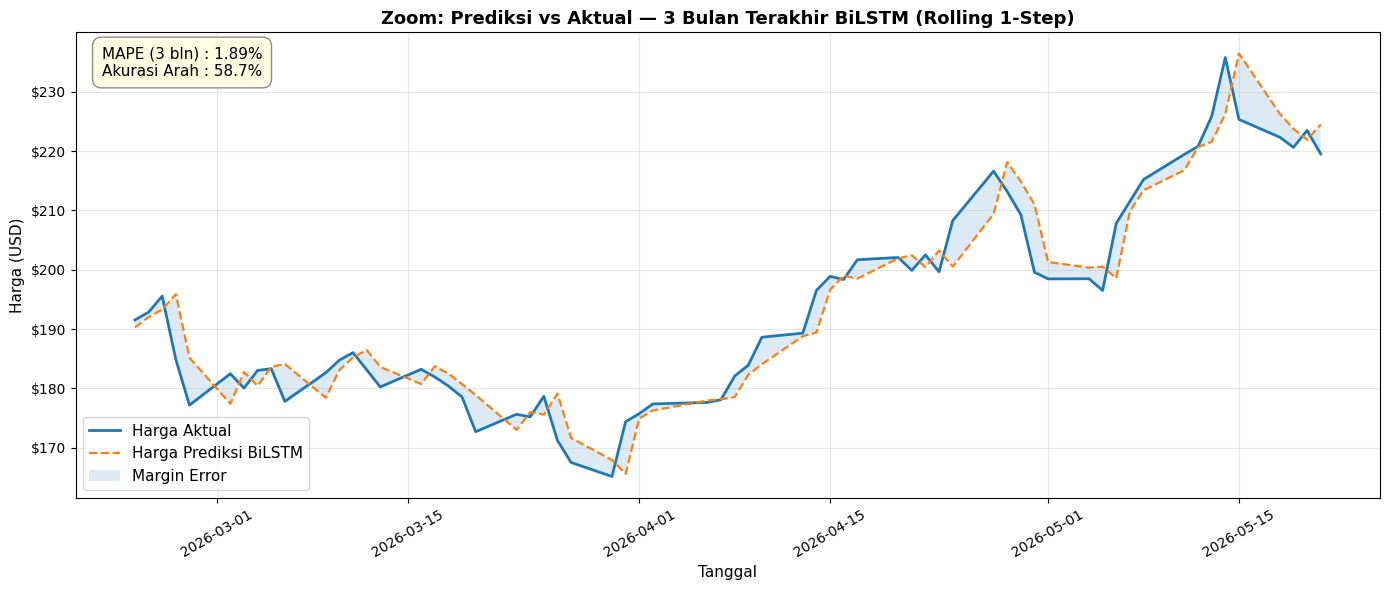


=== METRIK FINAL BiLSTM (ROLLING 1-STEP) ===
MAE Harga    : $2.10
MAPE Harga   : 2.31%
Akurasi Arah : 54.6%
Plot disimpan: lstm_rolling_zoom.png


In [ ]:
# ==============================================================================
# ROLLING 1-STEP PRICE PLOT — BiLSTM-Attention
# predicted_price[t+1] = actual_close[t] x (1 + predicted_return_lstm[t])
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("=" * 70)
print("ROLLING 1-STEP PRICE PLOT — BiLSTM-Attention")
print("=" * 70)

# ----------------------------------------------------------------------
# Ambil prediksi dan target LSTM yang sudah dibuat oleh cell training LSTM
# ----------------------------------------------------------------------
if "prediksi_test_lstm" not in globals():
    raise ValueError("Variabel prediksi_test_lstm belum ada. Jalankan cell training/evaluasi LSTM dulu.")

pred_lstm = np.array(prediksi_test_lstm).flatten()

if "y_test_lstm_asli" in globals():
    y_eval_lstm = np.array(y_test_lstm_asli).flatten()
else:
    y_eval_lstm = np.array(y_test.values[BEST_TS:]).flatten()

# ----------------------------------------------------------------------
# Buat index tanggal LSTM yang sejajar dengan hasil sequence
# LSTM test prediction mulai dari offset BEST_TS di X_test_all
# ----------------------------------------------------------------------
if "BEST_TS" not in globals():
    BEST_TS = bp.get("time_steps", 15) if "bp" in globals() else 15

if "X_test_all" in globals():
    test_index_lstm = pd.Index(X_test_all.index[BEST_TS : BEST_TS + len(pred_lstm)])
else:
    split_val = int(len(X_all_baru) * 0.85)
    test_index_lstm = pd.Index(X_all_baru.index[split_val + BEST_TS : split_val + BEST_TS + len(pred_lstm)])

min_len = min(len(test_index_lstm), len(pred_lstm), len(y_eval_lstm))
test_index_lstm = test_index_lstm[:min_len]
pred_lstm = pred_lstm[:min_len]
y_eval_lstm = y_eval_lstm[:min_len]

all_index = df_nvda.index

harga_prediksi_rolling_lstm = []
harga_close_aktual_target = []
tanggal_target = []
return_aktual_aligned = []
return_pred_aligned = []

for idx, pred_return, actual_return in zip(test_index_lstm, pred_lstm, y_eval_lstm):
    if idx not in all_index:
        continue

    posisi = all_index.get_loc(idx)

    if posisi + 1 >= len(df_nvda):
        continue

    harga_hari_ini = df_nvda.loc[idx, "Close"]
    tanggal_besok = all_index[posisi + 1]
    harga_besok_aktual = df_nvda.loc[tanggal_besok, "Close"]

    harga_besok_prediksi = harga_hari_ini * (1 + pred_return)

    harga_prediksi_rolling_lstm.append(harga_besok_prediksi)
    harga_close_aktual_target.append(harga_besok_aktual)
    tanggal_target.append(tanggal_besok)
    return_aktual_aligned.append(actual_return)
    return_pred_aligned.append(pred_return)

harga_prediksi_rolling_lstm = np.array(harga_prediksi_rolling_lstm)
harga_close_aktual_target = np.array(harga_close_aktual_target)
tanggal_target = pd.Index(tanggal_target)
return_aktual_aligned = np.array(return_aktual_aligned)
return_pred_aligned = np.array(return_pred_aligned)

if len(harga_prediksi_rolling_lstm) == 0:
    raise ValueError("Tidak ada data rolling yang berhasil disejajarkan. Cek index df_nvda dan X_test_all.")

mae_rolling_lstm = np.mean(np.abs(harga_close_aktual_target - harga_prediksi_rolling_lstm))
mape_rolling_lstm = np.mean(np.abs(
    (harga_close_aktual_target - harga_prediksi_rolling_lstm) / harga_close_aktual_target
)) * 100
da_rolling_lstm = (
    np.sign(return_aktual_aligned) == np.sign(return_pred_aligned)
).mean() * 100

print(f"MAE Harga    : ${mae_rolling_lstm:.2f}")
print(f"MAPE Harga   : {mape_rolling_lstm:.2f}%")
print(f"Akurasi Arah : {da_rolling_lstm:.2f}%")

zoom_n = min(63, len(tanggal_target))

tanggal_zoom = tanggal_target[-zoom_n:]
harga_aktual_zoom = harga_close_aktual_target[-zoom_n:]
harga_pred_zoom = harga_prediksi_rolling_lstm[-zoom_n:]
return_aktual_zoom = return_aktual_aligned[-zoom_n:]
return_pred_zoom = return_pred_aligned[-zoom_n:]

mape_zoom_lstm = np.mean(np.abs(
    (harga_aktual_zoom - harga_pred_zoom) / harga_aktual_zoom
)) * 100

da_zoom_lstm = (
    np.sign(return_aktual_zoom) == np.sign(return_pred_zoom)
).mean() * 100

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    tanggal_zoom,
    harga_aktual_zoom,
    label="Harga Aktual",
    linewidth=2.0
)

ax.plot(
    tanggal_zoom,
    harga_pred_zoom,
    label="Harga Prediksi BiLSTM",
    linewidth=1.6,
    linestyle="--"
)

ax.fill_between(
    tanggal_zoom,
    harga_aktual_zoom,
    harga_pred_zoom,
    alpha=0.15,
    label="Margin Error"
)

ax.text(
    0.02,
    0.97,
    f"MAPE (3 bln) : {mape_zoom_lstm:.2f}%\n"
    f"Akurasi Arah : {da_zoom_lstm:.1f}%",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightyellow",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.set_title(
    "Zoom: Prediksi vs Aktual — 3 Bulan Terakhir BiLSTM (Rolling 1-Step)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Harga (USD)", fontsize=11)
ax.set_xlabel("Tanggal", fontsize=11)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("lstm_rolling_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n=== METRIK FINAL BiLSTM (ROLLING 1-STEP) ===")
print(f"MAE Harga    : ${mae_rolling_lstm:.2f}")
print(f"MAPE Harga   : {mape_rolling_lstm:.2f}%")
print(f"Akurasi Arah : {da_rolling_lstm:.1f}%")
print("Plot disimpan: lstm_rolling_zoom.png")

In [ ]:
# =====================================================================
# RIDGE REGRESSION PIPELINE — ALUR SAMA DENGAN MODEL SEBELUMNYA
# =====================================================================

import numpy as np
import pandas as pd
import optuna
import warnings
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer


# =====================================================================
# PRE-FASE: FUNGSI METRIK
# =====================================================================

def directional_accuracy(y_true, y_pred):
    return np.mean(np.sign(np.array(y_true).flatten()) == np.sign(np.array(y_pred).flatten()))

da_scorer = make_scorer(directional_accuracy, greater_is_better=True)


# =====================================================================
# PRE-FASE: SPLIT DATA 70/15/15
# =====================================================================

split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]
X_test_all  = X_all_baru.iloc[split_val:]

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

tscv = TimeSeriesSplit(n_splits=5)

print("=" * 60)
print("SPLIT DATA — RIDGE REGRESSION")
print("=" * 60)
print(f"Train      : {len(X_train_all):>5} baris")
print(f"Validation : {len(X_val_all):>5} baris")
print(f"Test       : {len(X_test_all):>5} baris")
print(f"Total fitur: {X_train_all.shape[1]}")


# =====================================================================
# FASE 1: TUNING OPTUNA RIDGE PADA SEMUA FITUR
# =====================================================================

print("\n" + "=" * 60)
print("FASE 1: Tuning Optuna Ridge pada Semua Fitur...")
print("=" * 60)

def objective_ridge_all(trial):
    alpha = trial.suggest_float("alpha", 1e-5, 1e3, log=True)
    fit_intercept = trial.suggest_categorical("fit_intercept", [True, False])

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(
            alpha=alpha,
            fit_intercept=fit_intercept,
            random_state=42
        ))
    ])

    return cross_val_score(
        model,
        X_train_all,
        y_train,
        cv=tscv,
        scoring=da_scorer,
        n_jobs=-1
    ).mean()


study_ridge_all = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_ridge_all.optimize(objective_ridge_all, n_trials=50)

best_ridge_all = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(
        **study_ridge_all.best_params,
        random_state=42
    ))
])

best_ridge_all.fit(X_train_all, y_train)

print(f"✓ Selesai. Best DA CV: {study_ridge_all.best_value:.5f}")
print(f"  Parameter: {study_ridge_all.best_params}")


# =====================================================================
# FASE 2A: PERMUTATION IMPORTANCE PADA VALIDATION SET
# =====================================================================

print("\n" + "=" * 60)
print("FASE 2A: Permutation Importance Ridge pada Validation Set...")
print("=" * 60)

perm_result_ridge = permutation_importance(
    best_ridge_all,
    X_val_all,
    y_val,
    scoring=da_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df_ridge = pd.DataFrame({
    "Fitur": X_val_all.columns,
    "Skor_DA": perm_result_ridge.importances_mean,
    "Skor_Std": perm_result_ridge.importances_std
}).sort_values(by="Skor_DA", ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur Ridge Regression berdasarkan Permutation Importance:")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 65)

for i, row in perm_df_ridge.head(20).iterrows():
    print(
        f"{i+1:<4} {row['Fitur']:<35} "
        f"{row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}"
    )


# =====================================================================
# FASE 2B: SELEKSI FITUR BERBASIS STATISTIK + DEDUP KELOMPOK
# =====================================================================

print("\n" + "=" * 60)
print("FASE 2B: Seleksi Fitur Ridge Berbasis Statistik...")
print("=" * 60)

kelompok_fitur = {
    "lag_close":    [f"lag_close_{l}"  for l in [1, 3, 7, 14, 21, 30]],
    "lag_volume":   [f"lag_volume_{l}" for l in [1, 3, 7, 14, 21, 30]],
    "lag_return":   [f"lag_return_{l}" for l in [14, 21, 30]],
    "momentum":     [f"momentum_{l}d"  for l in [14, 21, 30]] + ["ROC_10", "ROC_20"],
    "rolling_mean": [f"rolling_mean_close_{w}" for w in [7, 14, 21, 30]],
    "rolling_std":  [f"rolling_std_close_{w}"  for w in [7, 14, 21, 30]],
    "hv":           ["HV_10", "HV_20", "HV_30", "HV_ratio_10_30", "Vol_term_slope"],
    "sma":          ["SMA_20", "SMA_50"],
    "bb_band":      ["BBU_20_2", "BBL_20_2", "BBM_20_2", "BBB_20_2", "BBP_20_2", "BB_Width"],
    "macd":         ["MACD_12_26_9", "MACDs_12_26_9", "MACDh_12_26_9"],
    "rs_spy":       ["RS_vs_SPY", "RS_vs_SPY_zscore", "RS_SPY_trending_up", "alpha_vs_SPY"],
    "rs_qqq":       ["RS_vs_QQQ", "RS_vs_QQQ_zscore", "RS_QQQ_trending_up", "alpha_vs_QQQ"],
    "vix":          ["VIX_Close", "VIX_Change", "VIX_MA5", "VIX_spike", "VIX_above_MA5"],
    "obv":          ["OBV_zscore", "OBV_above_MA20"],
    "ad":           ["AD_Line", "AD_zscore"],
    "volume_flow":  ["volume_spike", "volume_ratio_MA20", "CMF_20", "CMF_positive", "MFI_14"],
    "earnings":     ["is_earnings_day", "days_to_earnings", "pre_earnings_5d", "post_earnings_2d"],
}

fitur_ke_kelompok = {f: k for k, v in kelompok_fitur.items() for f in v}

def seleksi_fitur_ridge(perm_df, mapping, min_features=10, top_k_fallback=20):
    threshold = perm_df["Skor_DA"].std()
    kandidat = perm_df[perm_df["Skor_DA"] > threshold].copy()

    fitur_terpilih = []
    kelompok_terpakai = set()

    for _, row in kandidat.iterrows():
        fitur = row["Fitur"]
        kelompok = mapping.get(fitur, f"_solo_{fitur}")

        if kelompok not in kelompok_terpakai:
            fitur_terpilih.append(fitur)
            kelompok_terpakai.add(kelompok)

    if len(fitur_terpilih) < min_features:
        print(f"⚠️ Fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"→ Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)["Fitur"].tolist()

    return fitur_terpilih, threshold

fitur_ridge_terpilih, threshold_ridge = seleksi_fitur_ridge(
    perm_df_ridge,
    fitur_ke_kelompok,
    min_features=10,
    top_k_fallback=20
)

print(f"Threshold statistis : {threshold_ridge:.5f}")
print(f"Fitur terpilih      : {len(fitur_ridge_terpilih)} fitur\n")

for i, f in enumerate(fitur_ridge_terpilih, 1):
    skor = perm_df_ridge.loc[perm_df_ridge["Fitur"] == f, "Skor_DA"].values[0]
    print(f"{i:>2}. {f:<35} DA importance: {skor:.5f}")

X_train_ridge_sel = X_train_all[fitur_ridge_terpilih]
X_val_ridge_sel   = X_val_all[fitur_ridge_terpilih]
X_test_ridge_sel  = X_test_all[fitur_ridge_terpilih]


# =====================================================================
# FASE 3: TUNING ULANG RIDGE PADA FITUR TERPILIH
# =====================================================================

print("\n" + "=" * 60)
print("FASE 3: Tuning Ulang Ridge pada Fitur Terpilih...")
print("=" * 60)

def objective_ridge_final(trial):
    alpha = trial.suggest_float("alpha", 1e-5, 1e3, log=True)
    fit_intercept = trial.suggest_categorical("fit_intercept", [True, False])

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(
            alpha=alpha,
            fit_intercept=fit_intercept,
            random_state=42
        ))
    ])

    return cross_val_score(
        model,
        X_train_ridge_sel,
        y_train,
        cv=tscv,
        scoring=da_scorer,
        n_jobs=-1
    ).mean()


study_ridge_final = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_ridge_final.optimize(objective_ridge_final, n_trials=50)

best_ridge_final = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(
        **study_ridge_final.best_params,
        random_state=42
    ))
])

best_ridge_final.fit(X_train_ridge_sel, y_train)

print(f"✓ Selesai. Best DA CV: {study_ridge_final.best_value:.5f}")
print(f"  Parameter: {study_ridge_final.best_params}")


# =====================================================================
# EVALUASI MODEL FINAL RIDGE
# =====================================================================

print("\n" + "=" * 60)
print("EVALUASI MODEL FINAL RIDGE REGRESSION")
print("=" * 60)

prediksi_train_ridge = best_ridge_final.predict(X_train_ridge_sel)
prediksi_val_ridge   = best_ridge_final.predict(X_val_ridge_sel)
prediksi_test_ridge  = best_ridge_final.predict(X_test_ridge_sel)

def cetak_rapor_regresi(label, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    da = directional_accuracy(y_true, y_pred)

    print(f"\n[{label}]")
    print(f"MAE  : {mae:.5f}")
    print(f"RMSE : {rmse:.5f}")
    print(f"R2   : {r2:.5f}")
    print(f"DA   : {da:.5f}")

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "DA": da
    }

print(f"Fitur yang digunakan ({len(fitur_ridge_terpilih)}):")
print(fitur_ridge_terpilih)

hasil_train_ridge = cetak_rapor_regresi(
    "DATA TRAIN — Masa Lalu",
    y_train,
    prediksi_train_ridge
)

hasil_val_ridge = cetak_rapor_regresi(
    "DATA VALIDATION",
    y_val,
    prediksi_val_ridge
)

hasil_test_ridge = cetak_rapor_regresi(
    "DATA TEST — Masa Depan",
    y_test,
    prediksi_test_ridge
)


# =====================================================================
# BASELINE COMPARISON
# =====================================================================

print("\n" + "=" * 60)
print("PERBANDINGAN DENGAN BASELINE")
print("=" * 60)

naive_pred = pd.Series(y_test.values).shift(1).fillna(0).values
zero_pred = np.zeros(len(y_test))
ma5_pred = pd.Series(y_test.values).shift(1).rolling(5).mean().fillna(0).values

baseline_rows = []

def baseline_eval(nama, y_true, y_pred):
    return {
        "Model": nama,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "DA": directional_accuracy(y_true, y_pred)
    }

baseline_rows.append(baseline_eval("Naive return t-1", y_test.values, naive_pred))
baseline_rows.append(baseline_eval("Zero prediction", y_test.values, zero_pred))
baseline_rows.append(baseline_eval("Moving Average 5D", y_test.values, ma5_pred))
baseline_rows.append(baseline_eval("Ridge Regression", y_test.values, prediksi_test_ridge))

df_ridge_compare = pd.DataFrame(baseline_rows)

print(df_ridge_compare.to_string(index=False))


# =====================================================================
# SIMPAN HASIL UNTUK META-LEARNER / STACKING
# =====================================================================

hasil_ridge = {
    "Model": "Ridge Regression",
    "MAE_Test": hasil_test_ridge["MAE"],
    "RMSE_Test": hasil_test_ridge["RMSE"],
    "R2_Test": hasil_test_ridge["R2"],
    "DA_Test": hasil_test_ridge["DA"],
    "Best_Params": study_ridge_final.best_params,
    "Fitur_Terpilih": fitur_ridge_terpilih
}

print("\n" + "=" * 60)
print("RINGKASAN FINAL RIDGE")
print("=" * 60)
print(f"Jumlah fitur awal      : {X_all_baru.shape[1]}")
print(f"Jumlah fitur terpilih  : {len(fitur_ridge_terpilih)}")
print(f"Best params final      : {study_ridge_final.best_params}")
print(f"MAE Test               : {hasil_test_ridge['MAE']:.5f}")
print(f"RMSE Test              : {hasil_test_ridge['RMSE']:.5f}")
print(f"R2 Test                : {hasil_test_ridge['R2']:.5f}")
print(f"DA Test                : {hasil_test_ridge['DA']:.5f}")

print("\nVariabel penting yang sudah tersedia:")
print("- best_ridge_final")
print("- fitur_ridge_terpilih")
print("- X_train_ridge_sel, X_val_ridge_sel, X_test_ridge_sel")
print("- prediksi_train_ridge, prediksi_val_ridge, prediksi_test_ridge")
print("- hasil_ridge")

SPLIT DATA — RIDGE REGRESSION
Train      :  4570 baris
Validation :   979 baris
Test       :   980 baris
Total fitur: 71

FASE 1: Tuning Optuna Ridge pada Semua Fitur...
✓ Selesai. Best DA CV: 0.50512
  Parameter: {'alpha': 32.59954816681076, 'fit_intercept': True}

FASE 2A: Permutation Importance Ridge pada Validation Set...

Top 20 Fitur Ridge Regression berdasarkan Permutation Importance:
No   Fitur                                  Skor_DA     ±Std
-----------------------------------------------------------------
1    lag_close_7                            0.02707  0.01069
2    lag_close_21                           0.02584  0.01418
3    Return_Hari_Ini                        0.02319  0.00714
4    rolling_std_close_14                   0.02165  0.00882
5    rolling_std_close_30                   0.01655  0.00757
6    lag_close_3                            0.01246  0.01060
7    MACD_12_26_9                           0.01083  0.01363
8    lag_close_14                           0.01052

ROLLING 1-STEP PRICE PLOT — RIDGE REGRESSION — 3 BULAN TERAKHIR
MAE Harga 3 Bulan    : $9.92
MAPE Harga 3 Bulan   : 5.18%
Akurasi Arah 3 Bulan : 55.56%


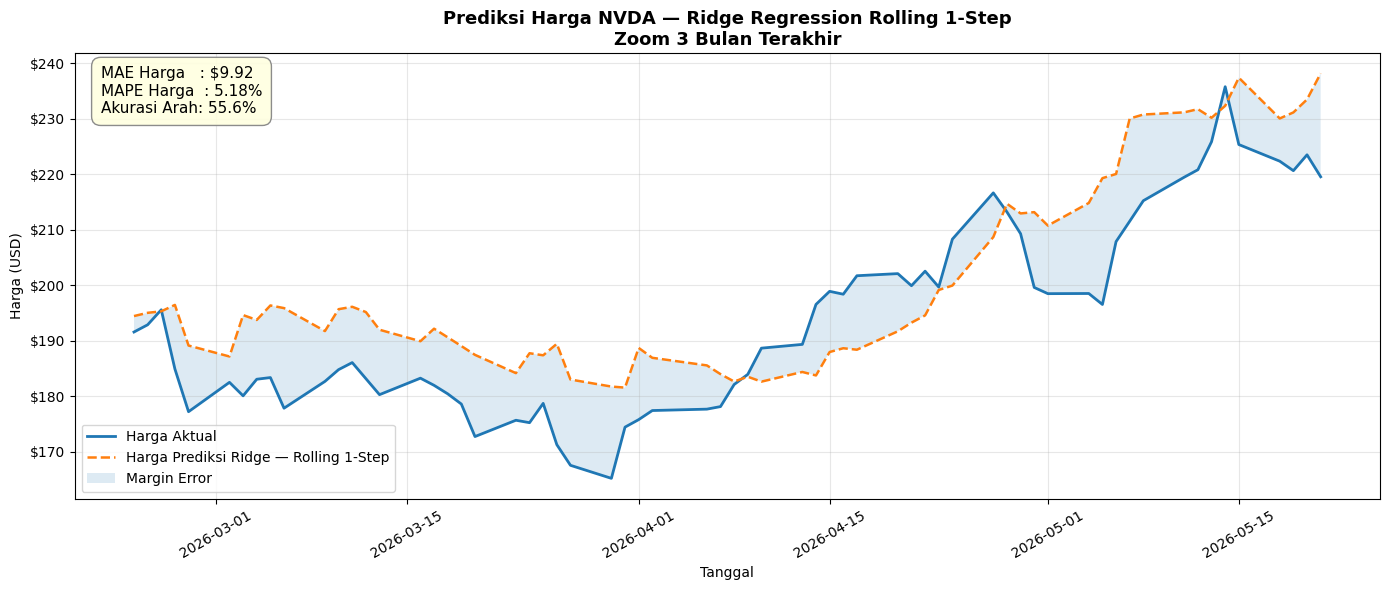


Plot disimpan sebagai: ridge_rolling_1step_3bulan.png


In [ ]:
# ==============================================================================
# ROLLING 1-STEP PRICE PLOT — RIDGE REGRESSION
# ZOOM 3 BULAN TERAKHIR SAJA
# predicted_price[t+1] = actual_close[t] × (1 + predicted_return_ridge[t])
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("=" * 70)
print("ROLLING 1-STEP PRICE PLOT — RIDGE REGRESSION — 3 BULAN TERAKHIR")
print("=" * 70)

# ------------------------------------------------------------------------------
# Pastikan variabel ini sudah ada:
# df_nvda              : dataframe utama dengan kolom Close
# prediksi_test_ridge  : hasil prediksi return dari Ridge
# X_test_ridge_sel     : data test Ridge dengan index tanggal
# y_test               : target test
# ------------------------------------------------------------------------------

# Ambil index test Ridge
tanggal_ridge = X_test_ridge_sel.index

harga_prediksi_rolling_ridge = []
harga_aktual_target_ridge = []
tanggal_target_ridge = []
return_aktual_aligned = []
return_pred_aligned = []

all_index = df_nvda.index

for idx, pred_return, actual_return in zip(
    tanggal_ridge,
    prediksi_test_ridge,
    y_test.values
):
    posisi = all_index.get_loc(idx)

    # Karena target adalah Target_Return_Besok,
    # prediksi pada tanggal idx digunakan untuk memprediksi harga idx + 1
    if posisi + 1 >= len(df_nvda):
        continue

    harga_hari_ini = df_nvda.loc[idx, "Close"]
    tanggal_besok = all_index[posisi + 1]
    harga_besok_aktual = df_nvda.loc[tanggal_besok, "Close"]

    harga_besok_prediksi = harga_hari_ini * (1 + pred_return)

    harga_prediksi_rolling_ridge.append(harga_besok_prediksi)
    harga_aktual_target_ridge.append(harga_besok_aktual)
    tanggal_target_ridge.append(tanggal_besok)
    return_aktual_aligned.append(actual_return)
    return_pred_aligned.append(pred_return)

harga_prediksi_rolling_ridge = np.array(harga_prediksi_rolling_ridge)
harga_aktual_target_ridge = np.array(harga_aktual_target_ridge)
tanggal_target_ridge = pd.Index(tanggal_target_ridge)
return_aktual_aligned = np.array(return_aktual_aligned)
return_pred_aligned = np.array(return_pred_aligned)

# ------------------------------------------------------------------------------
# Ambil 3 bulan terakhir, kurang lebih 63 hari trading
# ------------------------------------------------------------------------------
zoom_n = 63

tanggal_zoom = tanggal_target_ridge[-zoom_n:]
harga_aktual_zoom = harga_aktual_target_ridge[-zoom_n:]
harga_pred_zoom = harga_prediksi_rolling_ridge[-zoom_n:]
return_aktual_zoom = return_aktual_aligned[-zoom_n:]
return_pred_zoom = return_pred_aligned[-zoom_n:]

# ------------------------------------------------------------------------------
# Metrik 3 bulan terakhir
# ------------------------------------------------------------------------------
mae_zoom_ridge = np.mean(np.abs(harga_aktual_zoom - harga_pred_zoom))

mape_zoom_ridge = np.mean(np.abs(
    (harga_aktual_zoom - harga_pred_zoom) / harga_aktual_zoom
)) * 100

da_zoom_ridge = (
    np.sign(return_aktual_zoom) == np.sign(return_pred_zoom)
).mean() * 100

print(f"MAE Harga 3 Bulan    : ${mae_zoom_ridge:.2f}")
print(f"MAPE Harga 3 Bulan   : {mape_zoom_ridge:.2f}%")
print(f"Akurasi Arah 3 Bulan : {da_zoom_ridge:.2f}%")

# ------------------------------------------------------------------------------
# Plot rolling 1-step 3 bulan terakhir
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    tanggal_zoom,
    harga_aktual_zoom,
    label="Harga Aktual",
    linewidth=2.0
)

ax.plot(
    tanggal_zoom,
    harga_pred_zoom,
    label="Harga Prediksi Ridge — Rolling 1-Step",
    linewidth=1.8,
    linestyle="--"
)

ax.fill_between(
    tanggal_zoom,
    harga_aktual_zoom,
    harga_pred_zoom,
    alpha=0.15,
    label="Margin Error"
)

ax.text(
    0.02,
    0.97,
    f"MAE Harga   : ${mae_zoom_ridge:.2f}\n"
    f"MAPE Harga  : {mape_zoom_ridge:.2f}%\n"
    f"Akurasi Arah: {da_zoom_ridge:.1f}%",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightyellow",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.set_title(
    "Prediksi Harga NVDA — Ridge Regression Rolling 1-Step\nZoom 3 Bulan Terakhir",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Harga (USD)")
ax.set_xlabel("Tanggal")
ax.legend()
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("ridge_rolling_1step_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPlot disimpan sebagai: ridge_rolling_1step_3bulan.png")

In [ ]:
# =====================================================================
# SVR PIPELINE CEPAT — ALUR SAMA DENGAN MODEL SEBELUMNYA
# =====================================================================

import numpy as np
import pandas as pd
import optuna
import warnings
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer


# =====================================================================
# PRE-FASE: METRIK
# =====================================================================

def directional_accuracy(y_true, y_pred):
    return np.mean(
        np.sign(np.array(y_true).flatten()) ==
        np.sign(np.array(y_pred).flatten())
    )

da_scorer = make_scorer(directional_accuracy, greater_is_better=True)


# =====================================================================
# PRE-FASE: SPLIT DATA 70/15/15
# =====================================================================

split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]
X_test_all  = X_all_baru.iloc[split_val:]

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

# SVR agak berat, jadi pakai 3 split saja agar cepat
tscv = TimeSeriesSplit(n_splits=3)

print("=" * 60)
print("SPLIT DATA — SVR")
print("=" * 60)
print(f"Train      : {len(X_train_all):>5} baris")
print(f"Validation : {len(X_val_all):>5} baris")
print(f"Test       : {len(X_test_all):>5} baris")
print(f"Total fitur: {X_train_all.shape[1]}")


# =====================================================================
# FASE 1: TUNING OPTUNA SVR PADA SEMUA FITUR
# =====================================================================

print("\n" + "=" * 60)
print("FASE 1: Tuning Optuna SVR pada Semua Fitur...")
print("=" * 60)

def objective_svr_all(trial):
    C = trial.suggest_float("C", 0.01, 100, log=True)
    epsilon = trial.suggest_float("epsilon", 0.0001, 0.05, log=True)
    gamma = trial.suggest_categorical("gamma", ["scale", "auto"])
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear"])

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            C=C,
            epsilon=epsilon,
            gamma=gamma,
            kernel=kernel
        ))
    ])

    return cross_val_score(
        model,
        X_train_all,
        y_train,
        cv=tscv,
        scoring=da_scorer,
        n_jobs=-1
    ).mean()


study_svr_all = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Dibuat cepat: 15 trials
study_svr_all.optimize(objective_svr_all, n_trials=15)

best_svr_all = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(**study_svr_all.best_params))
])

best_svr_all.fit(X_train_all, y_train)

print(f"✓ Selesai. Best DA CV: {study_svr_all.best_value:.5f}")
print(f"  Parameter: {study_svr_all.best_params}")


# =====================================================================
# FASE 2A: PERMUTATION IMPORTANCE PADA VALIDATION SET
# =====================================================================

print("\n" + "=" * 60)
print("FASE 2A: Permutation Importance SVR pada Validation Set...")
print("=" * 60)

perm_result_svr = permutation_importance(
    best_svr_all,
    X_val_all,
    y_val,
    scoring=da_scorer,
    n_repeats=5,       # dibuat cepat
    random_state=42,
    n_jobs=-1
)

perm_df_svr = pd.DataFrame({
    "Fitur": X_val_all.columns,
    "Skor_DA": perm_result_svr.importances_mean,
    "Skor_Std": perm_result_svr.importances_std
}).sort_values(by="Skor_DA", ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur SVR berdasarkan Permutation Importance:")
print(f"{'No':<4} {'Fitur':<35} {'Skor_DA':>10} {'±Std':>8}")
print("-" * 65)

for i, row in perm_df_svr.head(20).iterrows():
    print(
        f"{i+1:<4} {row['Fitur']:<35} "
        f"{row['Skor_DA']:>10.5f} {row['Skor_Std']:>8.5f}"
    )


# =====================================================================
# FASE 2B: SELEKSI FITUR BERBASIS STATISTIK + FALLBACK
# =====================================================================

print("\n" + "=" * 60)
print("FASE 2B: Seleksi Fitur SVR Berbasis Statistik...")
print("=" * 60)

kelompok_fitur = {
    "lag_close":    [f"lag_close_{l}"  for l in [1, 3, 7, 14, 21, 30]],
    "lag_volume":   [f"lag_volume_{l}" for l in [1, 3, 7, 14, 21, 30]],
    "lag_return":   [f"lag_return_{l}" for l in [14, 21, 30]],
    "momentum":     [f"momentum_{l}d"  for l in [14, 21, 30]] + ["ROC_10", "ROC_20"],
    "rolling_mean": [f"rolling_mean_close_{w}" for w in [7, 14, 21, 30]],
    "rolling_std":  [f"rolling_std_close_{w}"  for w in [7, 14, 21, 30]],
    "hv":           ["HV_10", "HV_20", "HV_30", "HV_ratio_10_30", "Vol_term_slope"],
    "sma":          ["SMA_20", "SMA_50"],
    "bb_band":      ["BBU_20_2", "BBL_20_2", "BBM_20_2", "BBB_20_2", "BBP_20_2", "BB_Width"],
    "macd":         ["MACD_12_26_9", "MACDs_12_26_9", "MACDh_12_26_9"],
    "rs_spy":       ["RS_vs_SPY", "RS_vs_SPY_zscore", "RS_SPY_trending_up", "alpha_vs_SPY"],
    "rs_qqq":       ["RS_vs_QQQ", "RS_vs_QQQ_zscore", "RS_QQQ_trending_up", "alpha_vs_QQQ"],
    "vix":          ["VIX_Close", "VIX_Change", "VIX_MA5", "VIX_spike", "VIX_above_MA5"],
    "obv":          ["OBV_zscore", "OBV_above_MA20"],
    "ad":           ["AD_Line", "AD_zscore"],
    "volume_flow":  ["volume_spike", "volume_ratio_MA20", "CMF_20", "CMF_positive", "MFI_14"],
    "earnings":     ["is_earnings_day", "days_to_earnings", "pre_earnings_5d", "post_earnings_2d"],
}

fitur_ke_kelompok = {f: k for k, v in kelompok_fitur.items() for f in v}

def seleksi_fitur_svr(perm_df, mapping, min_features=8, top_k_fallback=15):
    threshold = perm_df["Skor_DA"].std()
    kandidat = perm_df[perm_df["Skor_DA"] > threshold].copy()

    fitur_terpilih = []
    kelompok_terpakai = set()

    for _, row in kandidat.iterrows():
        fitur = row["Fitur"]
        kelompok = mapping.get(fitur, f"_solo_{fitur}")

        if kelompok not in kelompok_terpakai:
            fitur_terpilih.append(fitur)
            kelompok_terpakai.add(kelompok)

    if len(fitur_terpilih) < min_features:
        print(f"⚠️ Fitur lolos threshold hanya {len(fitur_terpilih)}.")
        print(f"→ Fallback: gunakan Top {top_k_fallback} fitur dari ranking permutation importance.")
        fitur_terpilih = perm_df.head(top_k_fallback)["Fitur"].tolist()

    return fitur_terpilih, threshold

fitur_svr_terpilih, threshold_svr = seleksi_fitur_svr(
    perm_df_svr,
    fitur_ke_kelompok,
    min_features=8,
    top_k_fallback=15
)

print(f"Threshold statistis : {threshold_svr:.5f}")
print(f"Fitur terpilih      : {len(fitur_svr_terpilih)} fitur\n")

for i, f in enumerate(fitur_svr_terpilih, 1):
    skor = perm_df_svr.loc[perm_df_svr["Fitur"] == f, "Skor_DA"].values[0]
    print(f"{i:>2}. {f:<35} DA importance: {skor:.5f}")

X_train_svr_sel = X_train_all[fitur_svr_terpilih]
X_val_svr_sel   = X_val_all[fitur_svr_terpilih]
X_test_svr_sel  = X_test_all[fitur_svr_terpilih]


# =====================================================================
# FASE 3: TUNING ULANG SVR PADA FITUR TERPILIH
# =====================================================================

print("\n" + "=" * 60)
print("FASE 3: Tuning Ulang SVR pada Fitur Terpilih...")
print("=" * 60)

def objective_svr_final(trial):
    C = trial.suggest_float("C", 0.01, 100, log=True)
    epsilon = trial.suggest_float("epsilon", 0.0001, 0.05, log=True)
    gamma = trial.suggest_categorical("gamma", ["scale", "auto"])
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear"])

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            C=C,
            epsilon=epsilon,
            gamma=gamma,
            kernel=kernel
        ))
    ])

    return cross_val_score(
        model,
        X_train_svr_sel,
        y_train,
        cv=tscv,
        scoring=da_scorer,
        n_jobs=-1
    ).mean()


study_svr_final = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Dibuat cepat: 20 trials
study_svr_final.optimize(objective_svr_final, n_trials=20)

best_svr_final = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(**study_svr_final.best_params))
])

best_svr_final.fit(X_train_svr_sel, y_train)

print(f"✓ Selesai. Best DA CV: {study_svr_final.best_value:.5f}")
print(f"  Parameter: {study_svr_final.best_params}")


# =====================================================================
# EVALUASI MODEL FINAL SVR
# =====================================================================

print("\n" + "=" * 60)
print("EVALUASI MODEL FINAL SVR")
print("=" * 60)

prediksi_train_svr = best_svr_final.predict(X_train_svr_sel)
prediksi_val_svr   = best_svr_final.predict(X_val_svr_sel)
prediksi_test_svr  = best_svr_final.predict(X_test_svr_sel)

def cetak_rapor_regresi(label, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    da = directional_accuracy(y_true, y_pred)

    print(f"\n[{label}]")
    print(f"MAE  : {mae:.5f}")
    print(f"RMSE : {rmse:.5f}")
    print(f"R2   : {r2:.5f}")
    print(f"DA   : {da:.5f}")

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "DA": da
    }

print(f"Fitur yang digunakan ({len(fitur_svr_terpilih)}):")
print(fitur_svr_terpilih)

hasil_train_svr = cetak_rapor_regresi(
    "DATA TRAIN — Masa Lalu",
    y_train,
    prediksi_train_svr
)

hasil_val_svr = cetak_rapor_regresi(
    "DATA VALIDATION",
    y_val,
    prediksi_val_svr
)

hasil_test_svr = cetak_rapor_regresi(
    "DATA TEST — Masa Depan",
    y_test,
    prediksi_test_svr
)


# =====================================================================
# BASELINE COMPARISON
# =====================================================================

print("\n" + "=" * 60)
print("PERBANDINGAN DENGAN BASELINE")
print("=" * 60)

naive_pred = pd.Series(y_test.values).shift(1).fillna(0).values
zero_pred = np.zeros(len(y_test))
ma5_pred = pd.Series(y_test.values).shift(1).rolling(5).mean().fillna(0).values

def baseline_eval(nama, y_true, y_pred):
    return {
        "Model": nama,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "DA": directional_accuracy(y_true, y_pred)
    }

df_svr_compare = pd.DataFrame([
    baseline_eval("Naive return t-1", y_test.values, naive_pred),
    baseline_eval("Zero prediction", y_test.values, zero_pred),
    baseline_eval("Moving Average 5D", y_test.values, ma5_pred),
    baseline_eval("SVR", y_test.values, prediksi_test_svr),
])

print(df_svr_compare.to_string(index=False))


# =====================================================================
# SIMPAN HASIL UNTUK META-LEARNER / STACKING
# =====================================================================

hasil_svr = {
    "Model": "SVR",
    "MAE_Test": hasil_test_svr["MAE"],
    "RMSE_Test": hasil_test_svr["RMSE"],
    "R2_Test": hasil_test_svr["R2"],
    "DA_Test": hasil_test_svr["DA"],
    "Best_Params": study_svr_final.best_params,
    "Fitur_Terpilih": fitur_svr_terpilih
}

print("\n" + "=" * 60)
print("RINGKASAN FINAL SVR")
print("=" * 60)
print(f"Jumlah fitur awal      : {X_all_baru.shape[1]}")
print(f"Jumlah fitur terpilih  : {len(fitur_svr_terpilih)}")
print(f"Best params final      : {study_svr_final.best_params}")
print(f"MAE Test               : {hasil_test_svr['MAE']:.5f}")
print(f"RMSE Test              : {hasil_test_svr['RMSE']:.5f}")
print(f"R2 Test                : {hasil_test_svr['R2']:.5f}")
print(f"DA Test                : {hasil_test_svr['DA']:.5f}")

print("\nVariabel penting yang sudah tersedia:")
print("- best_svr_final")
print("- fitur_svr_terpilih")
print("- X_train_svr_sel, X_val_svr_sel, X_test_svr_sel")
print("- prediksi_train_svr, prediksi_val_svr, prediksi_test_svr")
print("- hasil_svr")

SPLIT DATA — SVR
Train      :  4570 baris
Validation :   979 baris
Test       :   980 baris
Total fitur: 71

FASE 1: Tuning Optuna SVR pada Semua Fitur...
✓ Selesai. Best DA CV: 0.51022
  Parameter: {'C': 0.013726318898045875, 'epsilon': 0.02845958019429148, 'gamma': 'auto', 'kernel': 'linear'}

FASE 2A: Permutation Importance SVR pada Validation Set...

Top 20 Fitur SVR berdasarkan Permutation Importance:
No   Fitur                                  Skor_DA     ±Std
-----------------------------------------------------------------
1    rolling_std_close_14                   0.01900  0.00996
2    lag_close_30                           0.01634  0.01545
3    lag_close_14                           0.01512  0.01558
4    alpha_vs_QQQ                           0.01267  0.00654
5    Return_Hari_Ini                        0.01246  0.00774
6    lag_close_21                           0.01185  0.00880
7    lag_close_3                            0.01164  0.00917
8    lag_close_7                    

ROLLING 1-STEP PRICE PLOT — SVR — 3 BULAN TERAKHIR
MAE Harga 3 Bulan    : $3.69
MAPE Harga 3 Bulan   : 1.90%
Akurasi Arah 3 Bulan : 58.73%


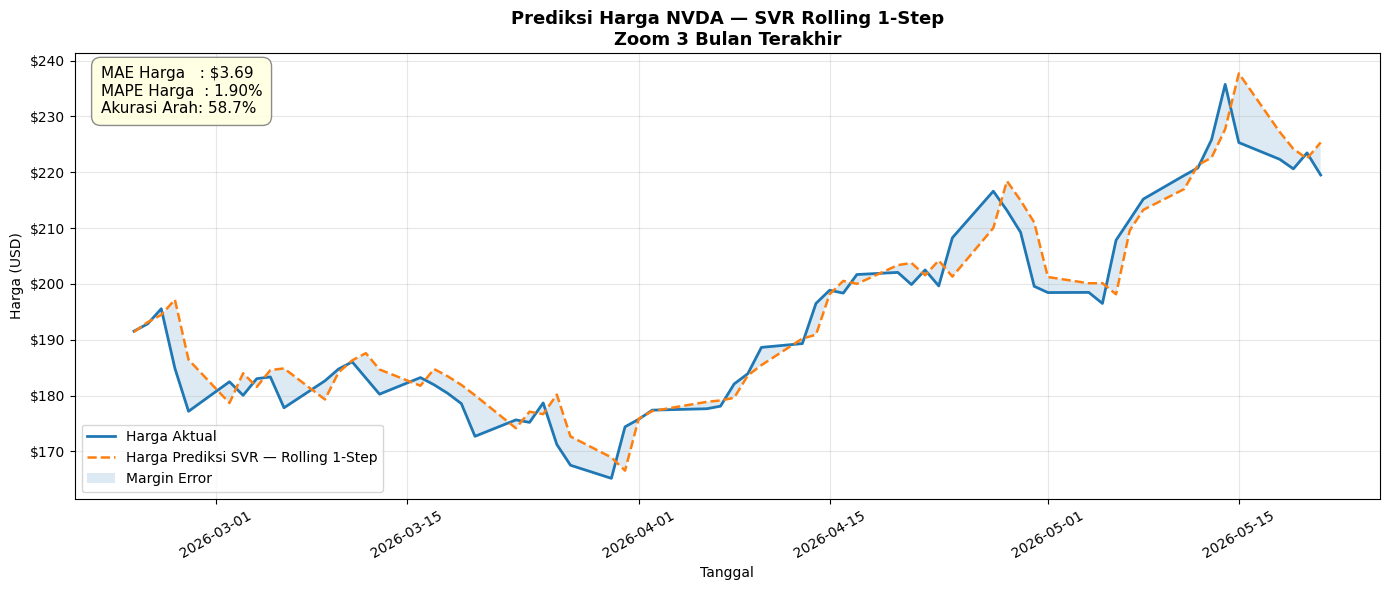


Plot disimpan sebagai: svr_rolling_1step_3bulan.png


In [ ]:
# ==============================================================================
# ROLLING 1-STEP PRICE PLOT — SVR
# ZOOM 3 BULAN TERAKHIR SAJA
# predicted_price[t+1] = actual_close[t] × (1 + predicted_return_svr[t])
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("=" * 70)
print("ROLLING 1-STEP PRICE PLOT — SVR — 3 BULAN TERAKHIR")
print("=" * 70)

# ------------------------------------------------------------------------------
# Pastikan variabel ini sudah ada:
# df_nvda             : dataframe utama dengan kolom Close
# prediksi_test_svr   : hasil prediksi return dari SVR
# X_test_svr_sel      : data test SVR dengan index tanggal
# y_test              : target test
# ------------------------------------------------------------------------------

tanggal_svr = X_test_svr_sel.index

harga_prediksi_rolling_svr = []
harga_aktual_target_svr = []
tanggal_target_svr = []
return_aktual_aligned_svr = []
return_pred_aligned_svr = []

all_index = df_nvda.index

for idx, pred_return, actual_return in zip(
    tanggal_svr,
    prediksi_test_svr,
    y_test.values
):
    posisi = all_index.get_loc(idx)

    # Karena target adalah Target_Return_Besok,
    # prediksi pada tanggal idx digunakan untuk memprediksi harga idx + 1
    if posisi + 1 >= len(df_nvda):
        continue

    harga_hari_ini = df_nvda.loc[idx, "Close"]
    tanggal_besok = all_index[posisi + 1]
    harga_besok_aktual = df_nvda.loc[tanggal_besok, "Close"]

    harga_besok_prediksi = harga_hari_ini * (1 + pred_return)

    harga_prediksi_rolling_svr.append(harga_besok_prediksi)
    harga_aktual_target_svr.append(harga_besok_aktual)
    tanggal_target_svr.append(tanggal_besok)
    return_aktual_aligned_svr.append(actual_return)
    return_pred_aligned_svr.append(pred_return)

harga_prediksi_rolling_svr = np.array(harga_prediksi_rolling_svr)
harga_aktual_target_svr = np.array(harga_aktual_target_svr)
tanggal_target_svr = pd.Index(tanggal_target_svr)
return_aktual_aligned_svr = np.array(return_aktual_aligned_svr)
return_pred_aligned_svr = np.array(return_pred_aligned_svr)

# ------------------------------------------------------------------------------
# Ambil 3 bulan terakhir, kurang lebih 63 hari trading
# ------------------------------------------------------------------------------
zoom_n = 63

tanggal_zoom = tanggal_target_svr[-zoom_n:]
harga_aktual_zoom = harga_aktual_target_svr[-zoom_n:]
harga_pred_zoom = harga_prediksi_rolling_svr[-zoom_n:]
return_aktual_zoom = return_aktual_aligned_svr[-zoom_n:]
return_pred_zoom = return_pred_aligned_svr[-zoom_n:]

# ------------------------------------------------------------------------------
# Metrik 3 bulan terakhir
# ------------------------------------------------------------------------------
mae_zoom_svr = np.mean(np.abs(harga_aktual_zoom - harga_pred_zoom))

mape_zoom_svr = np.mean(np.abs(
    (harga_aktual_zoom - harga_pred_zoom) / harga_aktual_zoom
)) * 100

da_zoom_svr = (
    np.sign(return_aktual_zoom) == np.sign(return_pred_zoom)
).mean() * 100

print(f"MAE Harga 3 Bulan    : ${mae_zoom_svr:.2f}")
print(f"MAPE Harga 3 Bulan   : {mape_zoom_svr:.2f}%")
print(f"Akurasi Arah 3 Bulan : {da_zoom_svr:.2f}%")

# ------------------------------------------------------------------------------
# Plot rolling 1-step 3 bulan terakhir
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    tanggal_zoom,
    harga_aktual_zoom,
    label="Harga Aktual",
    linewidth=2.0
)

ax.plot(
    tanggal_zoom,
    harga_pred_zoom,
    label="Harga Prediksi SVR — Rolling 1-Step",
    linewidth=1.8,
    linestyle="--"
)

ax.fill_between(
    tanggal_zoom,
    harga_aktual_zoom,
    harga_pred_zoom,
    alpha=0.15,
    label="Margin Error"
)

ax.text(
    0.02,
    0.97,
    f"MAE Harga   : ${mae_zoom_svr:.2f}\n"
    f"MAPE Harga  : {mape_zoom_svr:.2f}%\n"
    f"Akurasi Arah: {da_zoom_svr:.1f}%",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightyellow",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.set_title(
    "Prediksi Harga NVDA — SVR Rolling 1-Step\nZoom 3 Bulan Terakhir",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Harga (USD)")
ax.set_xlabel("Tanggal")
ax.legend()
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("svr_rolling_1step_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPlot disimpan sebagai: svr_rolling_1step_3bulan.png")

In [ ]:
# ==============================================================================
# CELL SEBELUM STACKING:
# BUAT PREDIKSI VALIDATION YANG MASIH KURANG TANPA TRAINING ULANG
# ==============================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("MEMBUAT PREDIKSI VALIDATION UNTUK STACKING — TANPA TRAINING ULANG")
print("=" * 70)

# ------------------------------------------------------------------------------
# 1. Pastikan split 70/15/15 tersedia
# ------------------------------------------------------------------------------

split_train = int(len(X_all_baru) * 0.70)
split_val   = int(len(X_all_baru) * 0.85)

X_train_all = X_all_baru.iloc[:split_train]
X_val_all   = X_all_baru.iloc[split_train:split_val]
X_test_all  = X_all_baru.iloc[split_val:]

y_train = y.iloc[:split_train]
y_val   = y.iloc[split_train:split_val]
y_test  = y.iloc[split_val:]

print(f"Train      : {X_train_all.shape}")
print(f"Validation : {X_val_all.shape}")
print(f"Test       : {X_test_all.shape}")


# ------------------------------------------------------------------------------
# 2. Helper function: buat prediksi validation & test tanpa fit ulang
# ------------------------------------------------------------------------------

def buat_prediksi_val_test(
    nama_model,
    model_var_name,
    fitur_var_name,
    pred_val_name,
    pred_test_name,
    x_val_name,
    x_test_name
):
    """
    Membuat prediksi validation dan test dari model final yang sudah ada.
    Tidak melakukan .fit(), hanya .predict().
    """

    print("\n" + "-" * 70)
    print(f"CEK {nama_model}")
    print("-" * 70)

    if model_var_name not in globals():
        print(f"❌ {model_var_name} tidak ditemukan. Tidak bisa buat prediksi {nama_model}.")
        return

    if fitur_var_name not in globals():
        print(f"❌ {fitur_var_name} tidak ditemukan. Tidak bisa buat prediksi {nama_model}.")
        return

    model = globals()[model_var_name]
    fitur = globals()[fitur_var_name]

    # Pastikan fitur valid
    fitur_valid = [f for f in fitur if f in X_all_baru.columns]

    if len(fitur_valid) == 0:
        print(f"❌ Tidak ada fitur valid untuk {nama_model}.")
        return

    if len(fitur_valid) != len(fitur):
        fitur_hilang = [f for f in fitur if f not in X_all_baru.columns]
        print(f"⚠️ Ada fitur tidak ditemukan dan dibuang: {fitur_hilang}")

    X_val_sel  = X_val_all[fitur_valid]
    X_test_sel = X_test_all[fitur_valid]

    # Simpan X_val dan X_test selected ke globals
    globals()[x_val_name] = X_val_sel
    globals()[x_test_name] = X_test_sel

    # Hanya predict, tidak training ulang
    globals()[pred_val_name] = model.predict(X_val_sel)
    globals()[pred_test_name] = model.predict(X_test_sel)

    print(f"✅ {pred_val_name} berhasil dibuat | shape={globals()[pred_val_name].shape}")
    print(f"✅ {pred_test_name} berhasil dibuat | shape={globals()[pred_test_name].shape}")
    print(f"✅ Fitur dipakai ({len(fitur_valid)}): {fitur_valid}")
    print(f"Std pred val  : {np.std(globals()[pred_val_name]):.8f}")
    print(f"Std pred test : {np.std(globals()[pred_test_name]):.8f}")


# ------------------------------------------------------------------------------
# 3. Random Forest
# ------------------------------------------------------------------------------

buat_prediksi_val_test(
    nama_model="Random Forest",
    model_var_name="best_rf_final",
    fitur_var_name="fitur_rf_terpilih",
    pred_val_name="prediksi_val_rf",
    pred_test_name="prediksi_test_rf",
    x_val_name="X_val_rf_sel",
    x_test_name="X_test_rf_sel"
)


# ------------------------------------------------------------------------------
# 4. XGBoost
# ------------------------------------------------------------------------------

buat_prediksi_val_test(
    nama_model="XGBoost",
    model_var_name="best_xgb_final",
    fitur_var_name="fitur_xgb_terpilih",
    pred_val_name="prediksi_val_xgb",
    pred_test_name="prediksi_test_xgb",
    x_val_name="X_val_xgb_sel",
    x_test_name="X_test_xgb_sel"
)


# ------------------------------------------------------------------------------
# 5. LightGBM
# ------------------------------------------------------------------------------

buat_prediksi_val_test(
    nama_model="LightGBM",
    model_var_name="best_lgb_final",
    fitur_var_name="fitur_lgb_terpilih",
    pred_val_name="prediksi_val_lgb",
    pred_test_name="prediksi_test_lgb",
    x_val_name="X_val_lgb_sel",
    x_test_name="X_test_lgb_sel"
)


# ------------------------------------------------------------------------------
# 6. SVR, kalau mau tetap dicek juga
# ------------------------------------------------------------------------------

buat_prediksi_val_test(
    nama_model="SVR",
    model_var_name="best_svr_final",
    fitur_var_name="fitur_svr_terpilih",
    pred_val_name="prediksi_val_svr",
    pred_test_name="prediksi_test_svr",
    x_val_name="X_val_svr_sel",
    x_test_name="X_test_svr_sel"
)


# ------------------------------------------------------------------------------
# 7. Cek semua prediksi untuk stacking
# ------------------------------------------------------------------------------

print("\n" + "=" * 70)
print("RINGKASAN VARIABEL PREDIKSI UNTUK STACKING")
print("=" * 70)

cek_vars = [
    "prediksi_val_rf", "prediksi_test_rf",
    "prediksi_val_xgb", "prediksi_test_xgb",
    "prediksi_val_lgb", "prediksi_test_lgb",
    "prediksi_val_lstm", "prediksi_test_lstm",
    "prediksi_val_svr", "prediksi_test_svr"
]

for v in cek_vars:
    if v in globals():
        arr = np.array(globals()[v]).flatten()
        print(
            f"✅ {v:<22} ada | "
            f"shape={arr.shape} | "
            f"std={np.std(arr):.8f} | "
            f"min={np.min(arr):.6f} | "
            f"max={np.max(arr):.6f}"
        )
    else:
        print(f"❌ {v:<22} belum ada")


# ------------------------------------------------------------------------------
# 8. Warning khusus kalau ada prediksi hampir konstan
# ------------------------------------------------------------------------------

print("\n" + "=" * 70)
print("CEK PREDIKSI KONSTAN / HAMPIR KONSTAN")
print("=" * 70)

for v in cek_vars:
    if v in globals():
        arr = np.array(globals()[v]).flatten()
        if np.std(arr) < 1e-10:
            print(f"⚠️ {v} hampir konstan. Kemungkinan akan dibuang saat stacking.")
        else:
            print(f"✅ {v} aman, tidak konstan.")

print("\n✅ Cell selesai. Sekarang jalankan ulang cell STACKING META-LEARNER.")

MEMBUAT PREDIKSI VALIDATION UNTUK STACKING — TANPA TRAINING ULANG
Train      : (4570, 71)
Validation : (979, 71)
Test       : (980, 71)

----------------------------------------------------------------------
CEK Random Forest
----------------------------------------------------------------------
✅ prediksi_val_rf berhasil dibuat | shape=(979,)
✅ prediksi_test_rf berhasil dibuat | shape=(980,)
✅ Fitur dipakai (20): ['momentum_30d', 'VIX_MA5', 'lag_return_14', 'lag_volume_30', 'Return_Hari_Ini', 'RSI_14', 'Volume', 'BB_Width', 'ATR_14', 'MACDh_12_26_9', 'lag_volume_7', 'lag_volume_1', 'SMA_50', 'lag_close_3', 'lag_close_1', 'rolling_std_close_7', 'rolling_std_close_14', 'BBU_20_2', 'BBL_20_2', 'SMA_20']
Std pred val  : 0.00136564
Std pred test : 0.00121066

----------------------------------------------------------------------
CEK XGBoost
----------------------------------------------------------------------
✅ prediksi_val_xgb berhasil dibuat | shape=(979,)
✅ prediksi_test_xgb berhasil d

In [ ]:
# ==============================================================================
# STACKING META-LEARNER — RF + XGBoost + LightGBM + LSTM + SVR
# Meta-learner: Ridge Regression
# ==============================================================================

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer

# ==============================================================================
# 1. METRIK
# ==============================================================================

def directional_accuracy(y_true, y_pred):
    return np.mean(
        np.sign(np.array(y_true).flatten()) ==
        np.sign(np.array(y_pred).flatten())
    )

da_scorer = make_scorer(directional_accuracy, greater_is_better=True)

def eval_regresi_da(nama, y_true, y_pred):
    return {
        "Model": nama,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "DA": directional_accuracy(y_true, y_pred)
    }


# ==============================================================================
# 2. CEK VARIABEL YANG DIBUTUHKAN
# ==============================================================================

print("=" * 70)
print("STACKING META-LEARNER")
print("=" * 70)

required_vars = [
    "prediksi_val_rf", "prediksi_test_rf",
    "prediksi_val_xgb", "prediksi_test_xgb",
    "prediksi_val_lgb", "prediksi_test_lgb",
    "prediksi_val_lstm", "prediksi_test_lstm",
    "prediksi_val_svr", "prediksi_test_svr",
    "y_val", "y_test"
]

missing_vars = [v for v in required_vars if v not in globals()]

if len(missing_vars) > 0:
    print("⚠️ Variabel berikut belum ditemukan:")
    for v in missing_vars:
        print(f" - {v}")

    print("\nPastikan semua model sudah menghasilkan prediksi validation dan test.")
    print("Kalau hanya prediksi test yang ada, model belum bisa dipakai untuk meta-learner yang benar.")
else:
    print("✅ Semua variabel utama ditemukan.")


# ==============================================================================
# 3. ALIGNMENT DATA
# ==============================================================================

# LSTM biasanya lebih pendek karena time_steps.
# Model tree/SVR punya panjang full validation/test.
# Maka semua model dipotong mulai dari BEST_TS agar sejajar dengan LSTM.
if "BEST_TS" not in globals():
    BEST_TS = 15
    print("Info: BEST_TS tidak ditemukan, default dipakai BEST_TS = 15")

print(f"\nBEST_TS untuk alignment: {BEST_TS}")

# Target validation dan test yang disejajarkan dengan LSTM
# Jika y_val_lstm_asli / y_test_lstm_asli tersedia, pakai itu karena sudah pasti aligned.
if "y_val_lstm_asli" in globals():
    y_meta_val = np.array(y_val_lstm_asli).flatten()
else:
    y_meta_val = np.array(y_val.values[BEST_TS:]).flatten()

if "y_test_lstm_asli" in globals():
    y_meta_test = np.array(y_test_lstm_asli).flatten()
else:
    y_meta_test = np.array(y_test.values[BEST_TS:]).flatten()


# ==============================================================================
# 4. SUSUN PREDIKSI BASE LEARNER
# ==============================================================================

base_val_preds = {}
base_test_preds = {}

# Random Forest
if "prediksi_val_rf" in globals() and "prediksi_test_rf" in globals():
    base_val_preds["RandomForest"] = np.array(prediksi_val_rf)[BEST_TS:]
    base_test_preds["RandomForest"] = np.array(prediksi_test_rf)[BEST_TS:]

# XGBoost
if "prediksi_val_xgb" in globals() and "prediksi_test_xgb" in globals():
    base_val_preds["XGBoost"] = np.array(prediksi_val_xgb)[BEST_TS:]
    base_test_preds["XGBoost"] = np.array(prediksi_test_xgb)[BEST_TS:]

# LightGBM
if "prediksi_val_lgb" in globals() and "prediksi_test_lgb" in globals():
    base_val_preds["LightGBM"] = np.array(prediksi_val_lgb)[BEST_TS:]
    base_test_preds["LightGBM"] = np.array(prediksi_test_lgb)[BEST_TS:]

# LSTM / BiLSTM-Attention
if "prediksi_val_lstm" in globals() and "prediksi_test_lstm" in globals():
    # Prediksi LSTM sudah aligned karena sequence, jadi tidak perlu dipotong BEST_TS lagi
    base_val_preds["BiLSTM_Attention"] = np.array(prediksi_val_lstm)
    base_test_preds["BiLSTM_Attention"] = np.array(prediksi_test_lstm)

# SVR
if "prediksi_val_svr" in globals() and "prediksi_test_svr" in globals():
    base_val_preds["SVR"] = np.array(prediksi_val_svr)[BEST_TS:]
    base_test_preds["SVR"] = np.array(prediksi_test_svr)[BEST_TS:]


# ==============================================================================
# 5. RAPIAKAN PANJANG DATA
# ==============================================================================

# Samakan panjang semua validation
min_len_val = min(
    [len(y_meta_val)] +
    [len(v) for v in base_val_preds.values()]
)

# Samakan panjang semua test
min_len_test = min(
    [len(y_meta_test)] +
    [len(v) for v in base_test_preds.values()]
)

y_meta_val = y_meta_val[:min_len_val]
y_meta_test = y_meta_test[:min_len_test]

for k in base_val_preds:
    base_val_preds[k] = np.array(base_val_preds[k])[:min_len_val]

for k in base_test_preds:
    base_test_preds[k] = np.array(base_test_preds[k])[:min_len_test]

X_meta_val = pd.DataFrame(base_val_preds)
X_meta_test = pd.DataFrame(base_test_preds)

print("\nShape awal meta-data:")
print(f"X_meta_val  : {X_meta_val.shape}")
print(f"y_meta_val  : {y_meta_val.shape}")
print(f"X_meta_test : {X_meta_test.shape}")
print(f"y_meta_test : {y_meta_test.shape}")

print("\nKolom meta awal:")
print(list(X_meta_val.columns))


# ==============================================================================
# 6. BERSIHKAN MODEL YANG BERMASALAH
# ==============================================================================

drop_cols = []

for col in X_meta_val.columns:
    val_arr = X_meta_val[col].values
    test_arr = X_meta_test[col].values

    # Drop kalau ada NaN / inf
    if not np.all(np.isfinite(val_arr)) or not np.all(np.isfinite(test_arr)):
        print(f"⚠️ {col} dibuang karena mengandung NaN/inf.")
        drop_cols.append(col)
        continue

    # Drop kalau prediksi hampir konstan
    if np.std(val_arr) < 1e-10 or np.std(test_arr) < 1e-10:
        print(f"⚠️ {col} dibuang karena prediksi konstan / hampir konstan.")
        drop_cols.append(col)
        continue

if len(drop_cols) > 0:
    X_meta_val = X_meta_val.drop(columns=drop_cols)
    X_meta_test = X_meta_test.drop(columns=drop_cols)

print("\nKolom meta setelah cleaning:")
print(list(X_meta_val.columns))

if X_meta_val.shape[1] < 2:
    raise ValueError("Model base learner yang valid kurang dari 2. Stacking tidak layak dijalankan.")


# ==============================================================================
# 7. CEK KORELASI ANTAR BASE LEARNER
# ==============================================================================

print("\n" + "=" * 70)
print("KORELASI PREDIKSI BASE LEARNER — VALIDATION")
print("=" * 70)

corr_meta = X_meta_val.corr()
print(corr_meta.round(3))

print("\nInterpretasi:")
print("- Korelasi > 0.85  : model terlalu mirip")
print("- Korelasi 0.50-0.85: masih mungkin membantu")
print("- Korelasi < 0.70  : cukup komplementer jika DA tidak buruk")


# ==============================================================================
# 8. TUNING RINGAN META-LEARNER RIDGE
# ==============================================================================

print("\n" + "=" * 70)
print("TUNING META-LEARNER RIDGE")
print("=" * 70)

tscv_meta = TimeSeriesSplit(n_splits=3)

alpha_grid = [0.001, 0.01, 0.1, 1, 10, 100, 500, 1000]

best_alpha = None
best_score = -np.inf

for alpha in alpha_grid:
    meta_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha, fit_intercept=True))
    ])

    score = cross_val_score(
        meta_model,
        X_meta_val,
        y_meta_val,
        cv=tscv_meta,
        scoring=da_scorer,
        n_jobs=-1
    ).mean()

    print(f"alpha={alpha:<8} | DA CV={score:.5f}")

    if score > best_score:
        best_score = score
        best_alpha = alpha

print(f"\nBest alpha meta-learner : {best_alpha}")
print(f"Best DA CV meta         : {best_score:.5f}")


# ==============================================================================
# 9. TRAIN META-LEARNER FINAL
# ==============================================================================

meta_learner = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha, fit_intercept=True))
])

meta_learner.fit(X_meta_val, y_meta_val)

prediksi_val_meta = meta_learner.predict(X_meta_val)
prediksi_test_meta = meta_learner.predict(X_meta_test)

print("\n✅ Meta-learner selesai dilatih.")


# ==============================================================================
# 10. EVALUASI META-LEARNER
# ==============================================================================

print("\n" + "=" * 70)
print("EVALUASI STACKING META-LEARNER")
print("=" * 70)

hasil_val_meta = eval_regresi_da(
    "Stacking Ridge Meta — Validation",
    y_meta_val,
    prediksi_val_meta
)

hasil_test_meta = eval_regresi_da(
    "Stacking Ridge Meta — Test",
    y_meta_test,
    prediksi_test_meta
)

print("\n[VALIDATION]")
print(f"MAE  : {hasil_val_meta['MAE']:.5f}")
print(f"RMSE : {hasil_val_meta['RMSE']:.5f}")
print(f"R2   : {hasil_val_meta['R2']:.5f}")
print(f"DA   : {hasil_val_meta['DA']:.5f}")

print("\n[TEST]")
print(f"MAE  : {hasil_test_meta['MAE']:.5f}")
print(f"RMSE : {hasil_test_meta['RMSE']:.5f}")
print(f"R2   : {hasil_test_meta['R2']:.5f}")
print(f"DA   : {hasil_test_meta['DA']:.5f}")


# ==============================================================================
# 11. PERBANDINGAN DENGAN BASE MODEL INDIVIDUAL
# ==============================================================================

print("\n" + "=" * 70)
print("PERBANDINGAN BASE MODEL VS STACKING — TEST SET")
print("=" * 70)

hasil_compare = []

for col in X_meta_test.columns:
    hasil_compare.append(
        eval_regresi_da(col, y_meta_test, X_meta_test[col].values)
    )

hasil_compare.append(
    eval_regresi_da("Stacking_Ridge_Meta", y_meta_test, prediksi_test_meta)
)

df_compare_stacking = pd.DataFrame(hasil_compare)
df_compare_stacking = df_compare_stacking.sort_values(by="DA", ascending=False)

print(df_compare_stacking.to_string(index=False))


# ==============================================================================
# 12. LIHAT BOBOT META-LEARNER
# ==============================================================================

ridge_model = meta_learner.named_steps["ridge"]

coef_df = pd.DataFrame({
    "Model": X_meta_val.columns,
    "Bobot_Meta": ridge_model.coef_
}).sort_values(by="Bobot_Meta", key=abs, ascending=False)

print("\n" + "=" * 70)
print("BOBOT META-LEARNER")
print("=" * 70)
print(coef_df.to_string(index=False))

print("\nIntercept meta-learner:")
print(ridge_model.intercept_)


# ==============================================================================
# 13. BASELINE COMPARISON
# ==============================================================================

print("\n" + "=" * 70)
print("BASELINE COMPARISON — TEST SET TER-ALIGN")
print("=" * 70)

naive_meta = pd.Series(y_meta_test).shift(1).fillna(0).values
zero_meta = np.zeros(len(y_meta_test))
ma5_meta = pd.Series(y_meta_test).shift(1).rolling(5).mean().fillna(0).values

df_baseline_meta = pd.DataFrame([
    eval_regresi_da("Naive return t-1", y_meta_test, naive_meta),
    eval_regresi_da("Zero prediction", y_meta_test, zero_meta),
    eval_regresi_da("Moving Average 5D", y_meta_test, ma5_meta),
    eval_regresi_da("Stacking_Ridge_Meta", y_meta_test, prediksi_test_meta)
])

print(df_baseline_meta.to_string(index=False))


# ==============================================================================
# 14. SIMPAN HASIL UNTUK LANJUTAN
# ==============================================================================

hasil_stacking_meta = {
    "Model": "Stacking Ridge Meta",
    "Base_Learners": list(X_meta_val.columns),
    "Best_Alpha": best_alpha,
    "MAE_Test": hasil_test_meta["MAE"],
    "RMSE_Test": hasil_test_meta["RMSE"],
    "R2_Test": hasil_test_meta["R2"],
    "DA_Test": hasil_test_meta["DA"]
}

print("\n" + "=" * 70)
print("RINGKASAN FINAL STACKING")
print("=" * 70)
print(f"Base learner dipakai : {list(X_meta_val.columns)}")
print(f"Best alpha           : {best_alpha}")
print(f"MAE Test             : {hasil_test_meta['MAE']:.5f}")
print(f"RMSE Test            : {hasil_test_meta['RMSE']:.5f}")
print(f"R2 Test              : {hasil_test_meta['R2']:.5f}")
print(f"DA Test              : {hasil_test_meta['DA']:.5f}")

print("\nVariabel penting yang tersedia:")
print("- X_meta_val")
print("- X_meta_test")
print("- y_meta_val")
print("- y_meta_test")
print("- meta_learner")
print("- prediksi_val_meta")
print("- prediksi_test_meta")
print("- df_compare_stacking")
print("- hasil_stacking_meta")

STACKING META-LEARNER
✅ Semua variabel utama ditemukan.

BEST_TS untuk alignment: 15

Shape awal meta-data:
X_meta_val  : (964, 5)
y_meta_val  : (964,)
X_meta_test : (965, 5)
y_meta_test : (965,)

Kolom meta awal:
['RandomForest', 'XGBoost', 'LightGBM', 'BiLSTM_Attention', 'SVR']
⚠️ SVR dibuang karena prediksi konstan / hampir konstan.

Kolom meta setelah cleaning:
['RandomForest', 'XGBoost', 'LightGBM', 'BiLSTM_Attention']

KORELASI PREDIKSI BASE LEARNER — VALIDATION
                  RandomForest  XGBoost  LightGBM  BiLSTM_Attention
RandomForest             1.000      NaN     0.737            -0.023
XGBoost                    NaN      NaN       NaN               NaN
LightGBM                 0.737      NaN     1.000            -0.021
BiLSTM_Attention        -0.023      NaN    -0.021             1.000

Interpretasi:
- Korelasi > 0.85  : model terlalu mirip
- Korelasi 0.50-0.85: masih mungkin membantu
- Korelasi < 0.70  : cukup komplementer jika DA tidak buruk

TUNING META-LEARNER RIDGE

ROLLING 1-STEP PRICE PLOT — STACKING META-LEARNER — 3 BULAN TERAKHIR
Index memakai test_index_lstm.
MAE Harga 3 Bulan    : $3.62
MAPE Harga 3 Bulan   : 1.86%
Akurasi Arah 3 Bulan : 57.14%


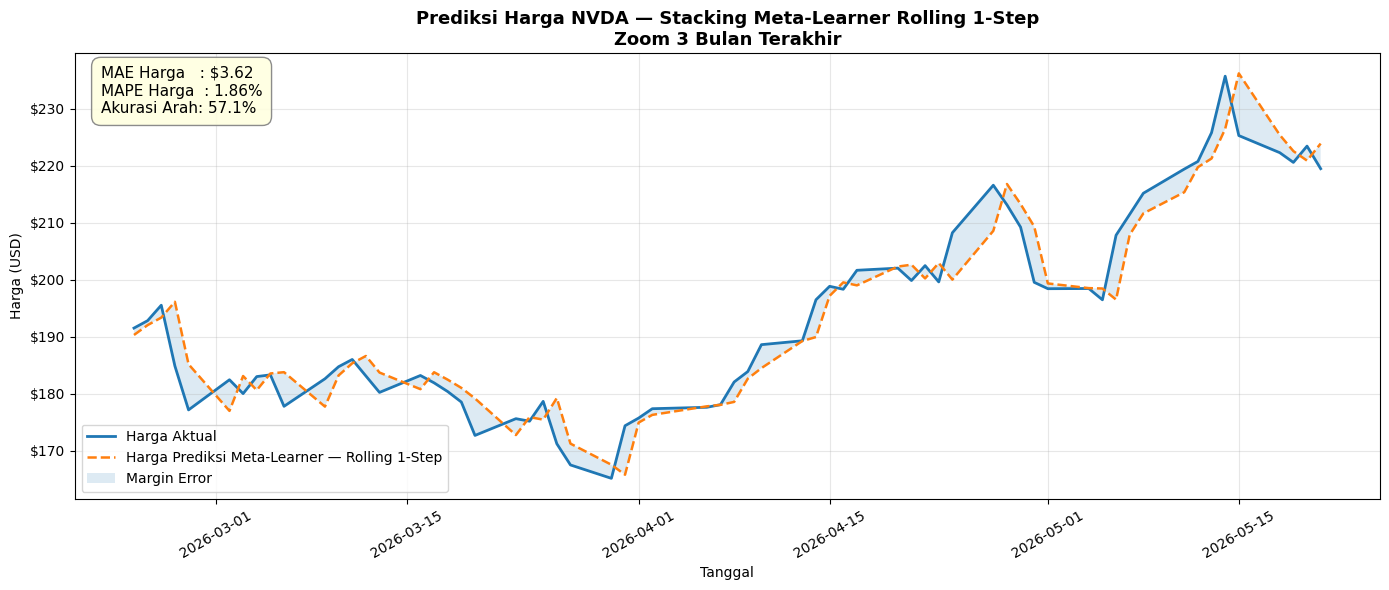


Plot disimpan sebagai: meta_learner_rolling_1step_3bulan.png


In [ ]:
# ==============================================================================
# ROLLING 1-STEP PRICE PLOT — STACKING META-LEARNER
# ZOOM 3 BULAN TERAKHIR SAJA
# predicted_price[t+1] = actual_close[t] × (1 + predicted_return_meta[t])
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("=" * 75)
print("ROLLING 1-STEP PRICE PLOT — STACKING META-LEARNER — 3 BULAN TERAKHIR")
print("=" * 75)

# ------------------------------------------------------------------------------
# CEK VARIABEL WAJIB
# ------------------------------------------------------------------------------

required_vars = ["prediksi_test_meta", "y_meta_test", "df_nvda"]

missing_vars = [v for v in required_vars if v not in globals()]

if len(missing_vars) > 0:
    raise ValueError(f"Variabel berikut belum ada: {missing_vars}")

if "BEST_TS" not in globals():
    BEST_TS = 15
    print("Info: BEST_TS tidak ditemukan, default dipakai BEST_TS = 15")

# ------------------------------------------------------------------------------
# AMBIL INDEX TEST YANG ALIGN DENGAN META-LEARNER
# ------------------------------------------------------------------------------

if "test_index_lstm" in globals():
    tanggal_meta = pd.Index(test_index_lstm[:len(prediksi_test_meta)])
    print("Index memakai test_index_lstm.")
elif "X_test_all" in globals():
    tanggal_meta = pd.Index(X_test_all.index[BEST_TS : BEST_TS + len(prediksi_test_meta)])
    print("Index memakai X_test_all.index dengan offset BEST_TS.")
else:
    raise ValueError("Tidak ditemukan test_index_lstm atau X_test_all untuk membuat tanggal.")

# Samakan panjang
min_len = min(len(tanggal_meta), len(prediksi_test_meta), len(y_meta_test))

tanggal_meta = tanggal_meta[:min_len]
pred_meta = np.array(prediksi_test_meta).flatten()[:min_len]
y_meta = np.array(y_meta_test).flatten()[:min_len]

# ------------------------------------------------------------------------------
# KONVERSI RETURN PREDIKSI MENJADI HARGA ROLLING 1-STEP
# ------------------------------------------------------------------------------

harga_prediksi_rolling_meta = []
harga_aktual_target_meta = []
tanggal_target_meta = []
return_aktual_aligned_meta = []
return_pred_aligned_meta = []

all_index = df_nvda.index

for idx, pred_return, actual_return in zip(tanggal_meta, pred_meta, y_meta):
    if idx not in all_index:
        continue

    posisi = all_index.get_loc(idx)

    # Target_Return_Besok:
    # prediksi pada tanggal idx digunakan untuk memprediksi harga Close idx + 1
    if posisi + 1 >= len(df_nvda):
        continue

    harga_hari_ini = df_nvda.loc[idx, "Close"]
    tanggal_besok = all_index[posisi + 1]
    harga_besok_aktual = df_nvda.loc[tanggal_besok, "Close"]

    harga_besok_prediksi = harga_hari_ini * (1 + pred_return)

    harga_prediksi_rolling_meta.append(harga_besok_prediksi)
    harga_aktual_target_meta.append(harga_besok_aktual)
    tanggal_target_meta.append(tanggal_besok)
    return_aktual_aligned_meta.append(actual_return)
    return_pred_aligned_meta.append(pred_return)

harga_prediksi_rolling_meta = np.array(harga_prediksi_rolling_meta)
harga_aktual_target_meta = np.array(harga_aktual_target_meta)
tanggal_target_meta = pd.Index(tanggal_target_meta)
return_aktual_aligned_meta = np.array(return_aktual_aligned_meta)
return_pred_aligned_meta = np.array(return_pred_aligned_meta)

# ------------------------------------------------------------------------------
# AMBIL 3 BULAN TERAKHIR
# ------------------------------------------------------------------------------

zoom_n = 63

tanggal_zoom = tanggal_target_meta[-zoom_n:]
harga_aktual_zoom = harga_aktual_target_meta[-zoom_n:]
harga_pred_zoom = harga_prediksi_rolling_meta[-zoom_n:]
return_aktual_zoom = return_aktual_aligned_meta[-zoom_n:]
return_pred_zoom = return_pred_aligned_meta[-zoom_n:]

# ------------------------------------------------------------------------------
# METRIK 3 BULAN TERAKHIR
# ------------------------------------------------------------------------------

mae_zoom_meta = np.mean(np.abs(harga_aktual_zoom - harga_pred_zoom))

mape_zoom_meta = np.mean(np.abs(
    (harga_aktual_zoom - harga_pred_zoom) / harga_aktual_zoom
)) * 100

da_zoom_meta = (
    np.sign(return_aktual_zoom) == np.sign(return_pred_zoom)
).mean() * 100

print(f"MAE Harga 3 Bulan    : ${mae_zoom_meta:.2f}")
print(f"MAPE Harga 3 Bulan   : {mape_zoom_meta:.2f}%")
print(f"Akurasi Arah 3 Bulan : {da_zoom_meta:.2f}%")

# ------------------------------------------------------------------------------
# PLOT ROLLING 1-STEP 3 BULAN TERAKHIR
# ------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    tanggal_zoom,
    harga_aktual_zoom,
    label="Harga Aktual",
    linewidth=2.0
)

ax.plot(
    tanggal_zoom,
    harga_pred_zoom,
    label="Harga Prediksi Meta-Learner — Rolling 1-Step",
    linewidth=1.8,
    linestyle="--"
)

ax.fill_between(
    tanggal_zoom,
    harga_aktual_zoom,
    harga_pred_zoom,
    alpha=0.15,
    label="Margin Error"
)

ax.text(
    0.02,
    0.97,
    f"MAE Harga   : ${mae_zoom_meta:.2f}\n"
    f"MAPE Harga  : {mape_zoom_meta:.2f}%\n"
    f"Akurasi Arah: {da_zoom_meta:.1f}%",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="lightyellow",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.set_title(
    "Prediksi Harga NVDA — Stacking Meta-Learner Rolling 1-Step\nZoom 3 Bulan Terakhir",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Harga (USD)")
ax.set_xlabel("Tanggal")
ax.legend()
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("meta_learner_rolling_1step_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nPlot disimpan sebagai: meta_learner_rolling_1step_3bulan.png")

XAI — SHAP BiLSTM-Attention — 3 BULAN TERAKHIR
Background train sequence : (100, 15, 20)
Data dijelaskan           : (63, 15, 20)
Jumlah fitur              : 20
Time steps                : 15
SHAP explainer: GradientExplainer

Top 20 Fitur SHAP BiLSTM — 3 Bulan Terakhir:


,Fitur,Mean_Abs_SHAP_3Bulan
0,rolling_std_close_7,1.273809
1,BBL_20_2,1.044993
2,rolling_mean_close_7,0.865878
3,SMA_50,0.739322
4,lag_close_1,0.690515
5,BBU_20_2,0.653902
6,SMA_20,0.628691
7,lag_close_3,0.568962
8,lag_close_7,0.542569
9,ATR_14,0.501906


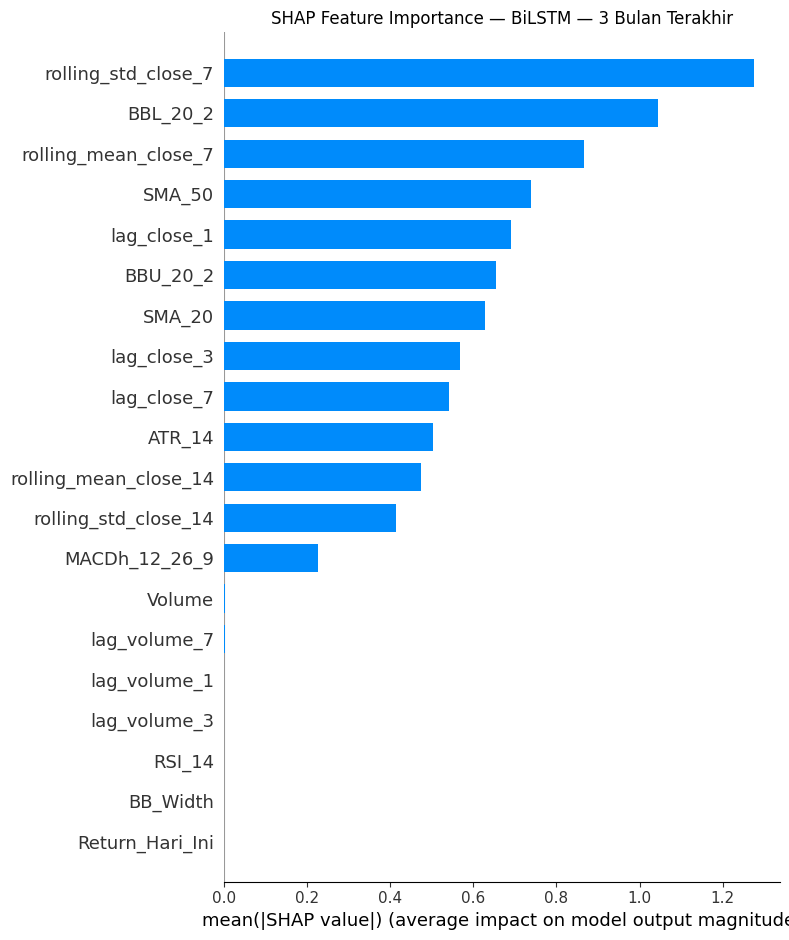

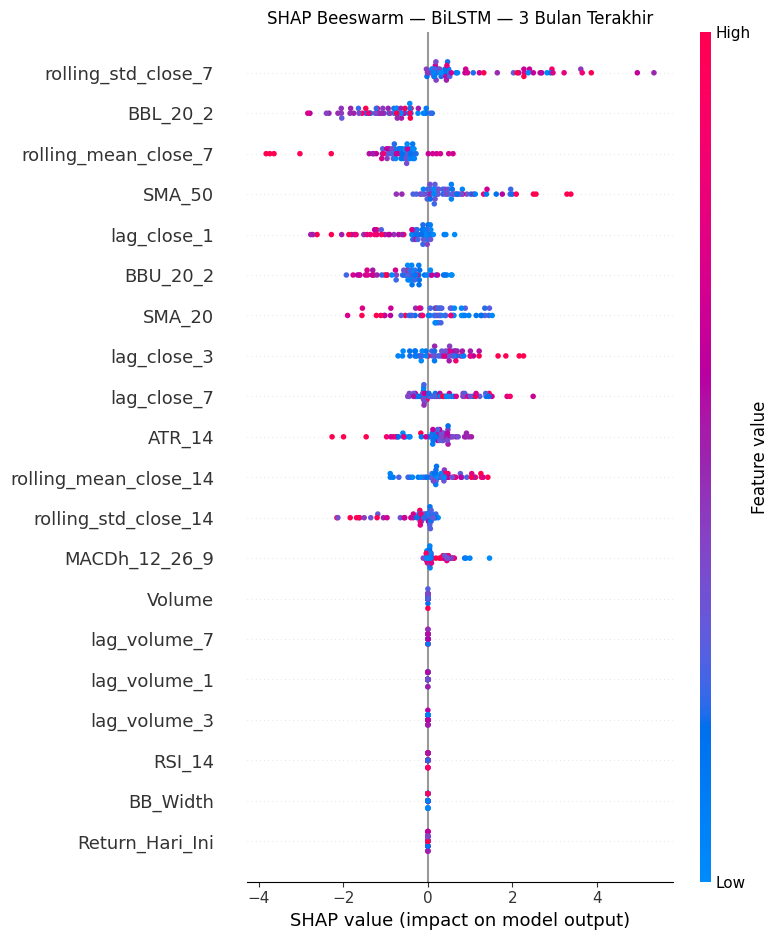

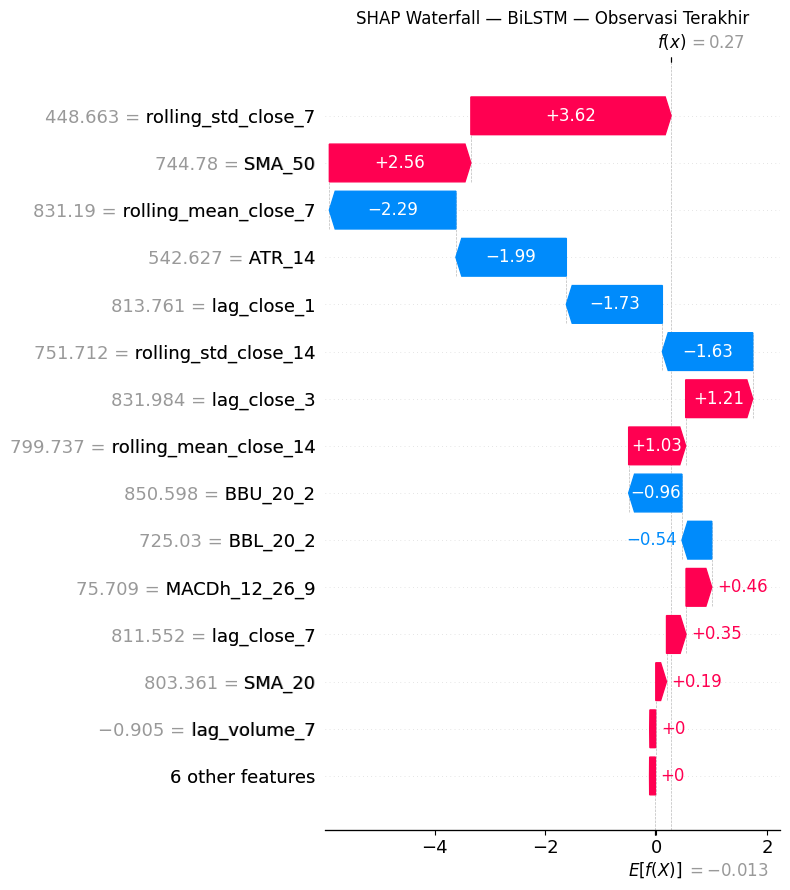


File disimpan:
- shap_bar_BiLSTM_3bulan.png
- shap_beeswarm_BiLSTM_3bulan.png
- shap_waterfall_BiLSTM_last_3bulan.png


In [ ]:
# ==============================================================================
# XAI CELL — SHAP EXPLAINABILITY BiLSTM-Attention — 3 BULAN TERAKHIR
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore")

try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

print("=" * 70)
print("XAI — SHAP BiLSTM-Attention — 3 BULAN TERAKHIR")
print("=" * 70)

# ------------------------------------------------------------------------------
# Cek variabel dari cell LSTM final
# ------------------------------------------------------------------------------
required_vars = [
    "model_lstm_final",
    "X_tr_final",
    "X_te_final",
    "fitur_lstm_terpilih",
    "prediksi_test_lstm"
]

missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Variabel belum ada: {missing_vars}. Jalankan cell training/evaluasi LSTM dulu.")

# ------------------------------------------------------------------------------
# Ambil 3 bulan terakhir dari test sequence
# 63 trading days kira-kira setara 3 bulan bursa
# ------------------------------------------------------------------------------
N_3BULAN = 63

X_explain_seq = X_te_final[-N_3BULAN:].copy()
pred_explain = np.array(prediksi_test_lstm).flatten()[-len(X_explain_seq):]

# Background SHAP dari train sequence, bukan test
N_BACKGROUND = min(100, len(X_tr_final))
rng = np.random.default_rng(42)
background_idx = rng.choice(len(X_tr_final), size=N_BACKGROUND, replace=False)
X_background_seq = X_tr_final[background_idx].copy()

print(f"Background train sequence : {X_background_seq.shape}")
print(f"Data dijelaskan           : {X_explain_seq.shape}")
print(f"Jumlah fitur              : {len(fitur_lstm_terpilih)}")
print(f"Time steps                : {X_explain_seq.shape[1]}")

# ------------------------------------------------------------------------------
# Wrapper prediksi agar SHAP membaca output regresi 1D
# ------------------------------------------------------------------------------
def predict_lstm_for_shap(X):
    pred = model_lstm_final.predict(X, verbose=0)
    return pred.reshape(-1)

# ------------------------------------------------------------------------------
# SHAP untuk sequence model
# GradientExplainer biasanya lebih cocok untuk Keras/TensorFlow.
# Jika gagal, fallback ke KernelExplainer dengan subset kecil.
# ------------------------------------------------------------------------------
try:
    explainer = shap.GradientExplainer(model_lstm_final, X_background_seq)
    shap_values_raw = explainer.shap_values(X_explain_seq)

    if isinstance(shap_values_raw, list):
        shap_values_seq = shap_values_raw[0]
    else:
        shap_values_seq = shap_values_raw

    if shap_values_seq.ndim == 4:
        shap_values_seq = shap_values_seq[:, :, :, 0]

    print("SHAP explainer: GradientExplainer")

except Exception as e:
    print("GradientExplainer gagal, fallback ke KernelExplainer.")
    print(f"Alasan: {e}")

    # KernelExplainer butuh input 2D, jadi sequence di-flatten
    N_KERNEL_EXPLAIN = min(30, len(X_explain_seq))
    X_background_flat = X_background_seq.reshape(X_background_seq.shape[0], -1)
    X_explain_flat = X_explain_seq[-N_KERNEL_EXPLAIN:].reshape(N_KERNEL_EXPLAIN, -1)

    def predict_lstm_flat(X_flat):
        X_seq = X_flat.reshape(X_flat.shape[0], X_te_final.shape[1], X_te_final.shape[2])
        return model_lstm_final.predict(X_seq, verbose=0).reshape(-1)

    explainer = shap.KernelExplainer(predict_lstm_flat, X_background_flat[:50])
    shap_values_flat = explainer.shap_values(X_explain_flat, nsamples=100)

    if isinstance(shap_values_flat, list):
        shap_values_flat = shap_values_flat[0]

    shap_values_seq = shap_values_flat.reshape(
        N_KERNEL_EXPLAIN,
        X_te_final.shape[1],
        X_te_final.shape[2]
    )

    X_explain_seq = X_explain_seq[-N_KERNEL_EXPLAIN:]
    print("SHAP explainer: KernelExplainer")

# ------------------------------------------------------------------------------
# Agregasi SHAP dari dimensi time_steps menjadi per fitur
# Untuk tiap fitur: rata-rata kontribusi absolut sepanjang time window.
# ------------------------------------------------------------------------------
shap_feature_values = shap_values_seq.sum(axis=1)
X_feature_values = X_explain_seq[:, -1, :]

shap_importance_lstm_3bulan = pd.DataFrame({
    "Fitur": fitur_lstm_terpilih,
    "Mean_Abs_SHAP_3Bulan": np.abs(shap_feature_values).mean(axis=0)
}).sort_values("Mean_Abs_SHAP_3Bulan", ascending=False).reset_index(drop=True)

print("\nTop 20 Fitur SHAP BiLSTM — 3 Bulan Terakhir:")
display(shap_importance_lstm_3bulan.head(20))

# ------------------------------------------------------------------------------
# Buat Explanation object untuk plot summary
# ------------------------------------------------------------------------------
shap_explanation = shap.Explanation(
    values=shap_feature_values,
    data=X_feature_values,
    feature_names=fitur_lstm_terpilih
)

# ------------------------------------------------------------------------------
# Plot 1: Bar Plot
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_feature_values,
    features=X_feature_values,
    feature_names=fitur_lstm_terpilih,
    plot_type="bar",
    max_display=20,
    show=False
)
plt.title("SHAP Feature Importance — BiLSTM — 3 Bulan Terakhir")
plt.tight_layout()
plt.savefig("shap_bar_BiLSTM_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# Plot 2: Beeswarm Plot
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_feature_values,
    features=X_feature_values,
    feature_names=fitur_lstm_terpilih,
    max_display=20,
    show=False
)
plt.title("SHAP Beeswarm — BiLSTM — 3 Bulan Terakhir")
plt.tight_layout()
plt.savefig("shap_beeswarm_BiLSTM_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# Plot 3: Waterfall untuk observasi terakhir
# ------------------------------------------------------------------------------
sample_id = len(X_explain_seq) - 1
base_value = float(np.mean(model_lstm_final.predict(X_background_seq, verbose=0)))

waterfall_exp = shap.Explanation(
    values=shap_feature_values[sample_id],
    base_values=base_value,
    data=X_feature_values[sample_id],
    feature_names=fitur_lstm_terpilih
)

shap.plots.waterfall(
    waterfall_exp,
    max_display=15,
    show=False
)
plt.title("SHAP Waterfall — BiLSTM — Observasi Terakhir")
plt.tight_layout()
plt.savefig("shap_waterfall_BiLSTM_last_3bulan.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nFile disimpan:")
print("- shap_bar_BiLSTM_3bulan.png")
print("- shap_beeswarm_BiLSTM_3bulan.png")
print("- shap_waterfall_BiLSTM_last_3bulan.png")